In [1]:
import pandas as pd
df=pd.read_excel(r"C:\Users\kiran\Manipal Academy of Higher Education\OneDrive - Manipal Academy of Higher Education\PW\CardioMetabolic\final_data.xlsx")
print(df.head())

   Residence  Age_c  Sex  Marital_Status  Education  Living  SRH  ADL  IADL  \
0          1     70    1               2          1       2    4    0     1   
1          1     68    2               2          1       2    3    0     1   
2          1     54    1               2          4       2    2    0     0   
3          1     51    2               2          1       2    3    0     0   
4          1     85    2               3          1       3    2    0     1   

   BMI  Tobacco  Drinker  Yoga  Physical_Activity  MPCE  Caste  Religion  \
0    0        0        0     3                  0     4      4         2   
1    2        2        0     3                  0     4      4         2   
2    1        0        0     1                  2     4      4         2   
3    3        0        0     3                  1     4      4         2   
4    1        0        0     3                  0     4      4         3   

   Region  CMD  
0       1    1  
1       1    1  
2       1    0  


In [2]:
df.isnull().sum()
df.isnull().mean()*100

Residence            0.0
Age_c                0.0
Sex                  0.0
Marital_Status       0.0
Education            0.0
Living               0.0
SRH                  0.0
ADL                  0.0
IADL                 0.0
BMI                  0.0
Tobacco              0.0
Drinker              0.0
Yoga                 0.0
Physical_Activity    0.0
MPCE                 0.0
Caste                0.0
Religion             0.0
Region               0.0
CMD                  0.0
dtype: float64

In [3]:
#definig independent and dependent variables 
x=df.iloc[:,:18]
x
y=df.iloc[:,-1]
y

0        1
1        1
2        0
3        1
4        1
        ..
59684    1
59685    1
59686    0
59687    1
59688    0
Name: CMD, Length: 59689, dtype: int64

In [4]:
# Check CMD distribution
print("CMD Class Distribution:")
print(y.value_counts())
print("\nPercentage:")
print(y.value_counts(normalize=True) * 100)

# Total
print(f"\nTotal samples: {len(y)}")
print(f"CMD = 0 (No CMD): {(y==0).sum()}")
print(f"CMD = 1 (CMD): {(y==1).sum()}")

CMD Class Distribution:
CMD
0    38281
1    21408
Name: count, dtype: int64

Percentage:
CMD
0    64.134095
1    35.865905
Name: proportion, dtype: float64

Total samples: 59689
CMD = 0 (No CMD): 38281
CMD = 1 (CMD): 21408


In [5]:
from sklearn.model_selection import train_test_split

In [6]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
x_train
y_train

16355    1
8586     0
25229    0
38377    0
3068     1
        ..
54343    0
38158    0
860      0
15795    0
56422    0
Name: CMD, Length: 47751, dtype: int64

In [7]:
#scaling
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)

In [8]:
#1.Logistic Regression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             confusion_matrix, roc_auc_score, precision_recall_curve,
                             cohen_kappa_score, matthews_corrcoef, balanced_accuracy_score)

import numpy as np
import pandas as pd

model_lr=LogisticRegression(solver='saga',max_iter=100000,random_state=0)
model_lr.fit(x_train_scaled,y_train)

y_pred=model_lr.predict(x_test_scaled)
y_prob = model_lr.predict_proba(x_test_scaled)[:, 1] 

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
TP = cm[1, 1]
TN = cm[0, 0]
FP = cm[0, 1]
FN = cm[1, 0]

# Metrics Calculation
accuracy = accuracy_score(y_test, y_pred)
sensitivity = recall_score(y_test, y_pred)
specificity = TN / (TN + FP)
precision = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
npv = TN / (TN + FN)
balanced_acc = balanced_accuracy_score(y_test, y_pred)
mcc = matthews_corrcoef(y_test, y_pred)
kappa = cohen_kappa_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

# PR-AUC
precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_prob)
pr_auc = np.trapz(recall_curve, precision_curve)  # Area under PR curve

# Display Metrics
metrics = {
    "Accuracy": round(accuracy, 4),
    "Sensitivity/Recall": round(sensitivity, 4),
    "Specificity": round(specificity, 4),
    "Precision": round(precision, 4),
    "F1 Score": round(f1, 4),
    "NPV": round(npv, 4),
    "Balanced Accuracy": round(balanced_acc, 4),
    "MCC": round(mcc, 4),
    "Cohen's Kappa": round(kappa, 4),
    "AUC-ROC": round(auc, 4),
    "PR-AUC": round(pr_auc, 4)
}

for k, v in metrics.items():
    print(f"{k}: {v}")

Accuracy: 0.702
Sensitivity/Recall: 0.4147
Specificity: 0.8643
Precision: 0.6332
F1 Score: 0.5012
NPV: 0.7233
Balanced Accuracy: 0.6395
MCC: 0.3154
Cohen's Kappa: 0.3017
AUC-ROC: 0.7348
PR-AUC: 0.2422


C:\Users\kiran\AppData\Local\Temp\ipykernel_7276\447060859.py:38: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pr_auc = np.trapz(recall_curve, precision_curve)  # Area under PR curve


In [9]:
import sys
!{sys.executable} -m pip install shap

Defaulting to user installation because normal site-packages is not writeable


In [10]:
import shap

# Create a masker using training data
masker = shap.maskers.Independent(x_train_scaled)

# SHAP explainer for Logistic Regression
explainer = shap.LinearExplainer(model_lr, masker=masker)

# Compute SHAP values
shap_values = explainer(x_test_scaled)

# Convert to DataFrame
shap_df = pd.DataFrame(shap_values.values, columns=x_train.columns)

# Global SHAP importance: mean absolute value
shap_importance = pd.DataFrame({
    'Feature': x_train.columns,
    'SHAP Importance': np.abs(shap_df).mean().values
}).sort_values(by='SHAP Importance', ascending=False)

print("Top 10 SHAP Feature Importances (Logistic Regression):")
print(shap_importance.head(10))

Top 10 SHAP Feature Importances (Logistic Regression):
              Feature  SHAP Importance
9                 BMI         0.358723
6                 SRH         0.340367
1               Age_c         0.253294
0           Residence         0.218614
14               MPCE         0.159815
4           Education         0.144167
13  Physical_Activity         0.092097
2                 Sex         0.072889
17             Region         0.053211
8                IADL         0.052453


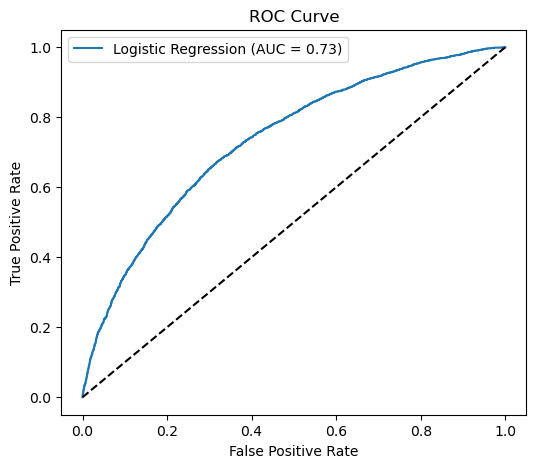

C:\Users\kiran\AppData\Local\Temp\ipykernel_7276\2257657080.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


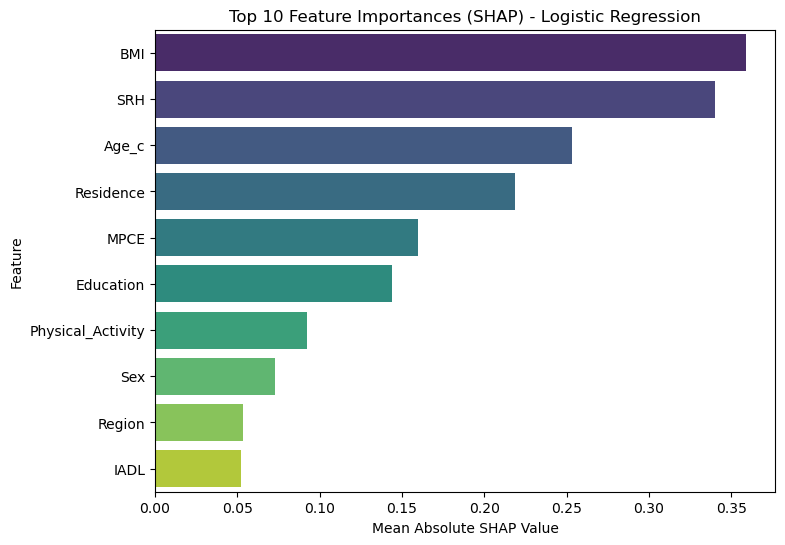

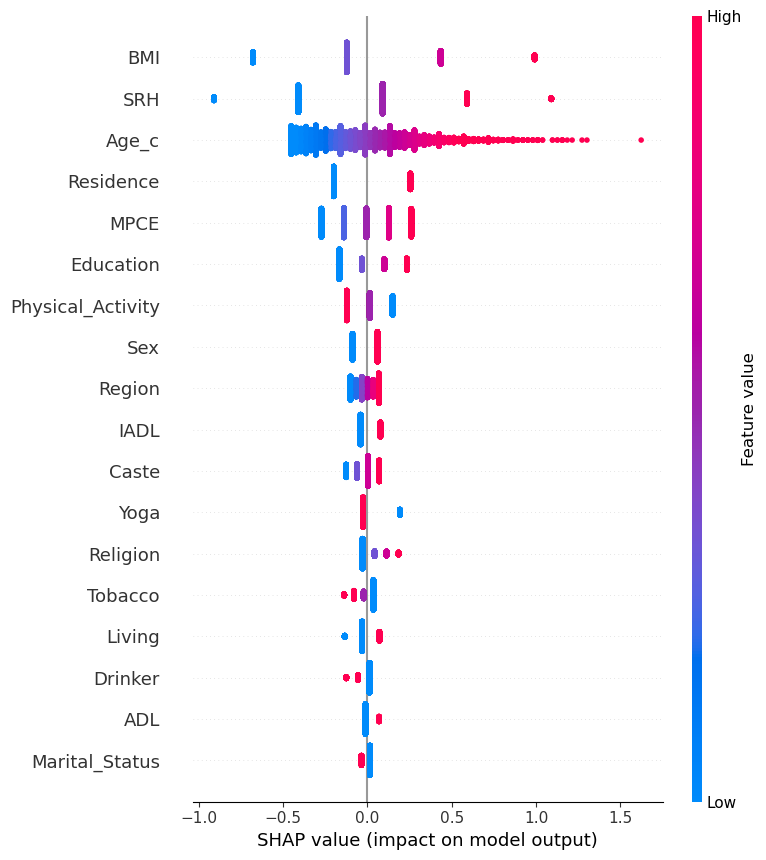

In [11]:
# ROC Curve (already in your code)
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve

fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {auc:.2f})')
plt.plot([0,1], [0,1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# SHAP Feature Importance Bar Graph (Top 10)
plt.figure(figsize=(8,6))
sns.barplot(
    x='SHAP Importance',
    y='Feature',
    data=shap_importance.head(10),
    palette='viridis'
)
plt.xlabel('Mean Absolute SHAP Value')
plt.ylabel('Feature')
plt.title('Top 10 Feature Importances (SHAP) - Logistic Regression')
plt.show()

# Optional: SHAP summary plot (beeswarm)
shap.summary_plot(shap_values, x_test_scaled, feature_names=x_train.columns)

In [12]:
from imblearn.over_sampling import SMOTE

In [13]:
smote = SMOTE(random_state=42)
x_train_smote, y_train_smote = smote.fit_resample(x_train, y_train)
x_train_smote

,Residence,Age_c,Sex,Marital_Status,Education,Living,SRH,ADL,IADL,BMI,Tobacco,Drinker,Yoga,Physical_Activity,MPCE,Caste,Religion,Region
0,1,63,2,2,1,2,3,0,0,2,3,0,3,2,2,1,1,3
1,2,66,1,3,2,3,2,0,1,1,0,0,1,1,1,1,1,1
2,1,67,2,3,1,3,3,0,0,0,0,0,3,2,2,3,1,4
3,1,53,2,2,2,2,3,0,1,0,2,0,3,2,3,3,2,5
4,1,72,2,2,1,2,3,0,1,0,0,0,1,1,3,1,4,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61299,2,56,2,2,4,2,2,0,0,2,0,0,3,1,2,3,1,6
61300,1,45,1,2,2,1,2,0,0,1,0,0,3,2,5,1,4,1
61301,1,50,1,2,3,2,3,0,0,1,0,0,3,0,1,3,1,6
61302,1,70,2,2,1,2,3,0,0,0,0,0,3,0,3,3,1,2


In [14]:
#After Smote applying logistic regression

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

model=LogisticRegression(solver='saga',max_iter=100000,random_state=0)
model.fit(x_train_smote,y_train_smote)

y_pred=model.predict(x_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {round(accuracy, 2)}")
print("Classification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.65
Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.65      0.71      7629
           1       0.52      0.66      0.58      4309

    accuracy                           0.65     11938
   macro avg       0.64      0.66      0.64     11938
weighted avg       0.68      0.65      0.66     11938



In [14]:
# 2.SVM Model 
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             confusion_matrix, roc_auc_score, precision_recall_curve,
                             cohen_kappa_score, matthews_corrcoef, balanced_accuracy_score,
                             classification_report)

# Model training
model_svm = SVC(kernel='linear', C=1, probability=True, random_state=0)  # probability=True needed for ROC
model_svm.fit(x_train_scaled, y_train)

# Predictions
y_pred = model_svm.predict(x_test_scaled)
y_prob = model_svm.predict_proba(x_test_scaled)[:, 1]  # probability for positive class

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
TP = cm[1, 1]
TN = cm[0, 0]
FP = cm[0, 1]
FN = cm[1, 0]

# Metrics Calculation
accuracy = accuracy_score(y_test, y_pred)
sensitivity = recall_score(y_test, y_pred)
specificity = TN / (TN + FP)
precision = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
npv = TN / (TN + FN)
balanced_acc = balanced_accuracy_score(y_test, y_pred)
mcc = matthews_corrcoef(y_test, y_pred)
kappa = cohen_kappa_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

# PR-AUC
precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_prob)
pr_auc = np.trapz(recall_curve, precision_curve)

# Display metrics
metrics = {
    "Accuracy": round(accuracy, 4),
    "Sensitivity/Recall": round(sensitivity, 4),
    "Specificity": round(specificity, 4),
    "Precision": round(precision, 4),
    "F1 Score": round(f1, 4),
    "NPV": round(npv, 4),
    "Balanced Accuracy": round(balanced_acc, 4),
    "MCC": round(mcc, 4),
    "Cohen's Kappa": round(kappa, 4),
    "AUC-ROC": round(auc, 4),
    "PR-AUC": round(pr_auc, 4)
}

for k, v in metrics.items():
    print(f"{k}: {v}")

Accuracy: 0.7023
Sensitivity/Recall: 0.3808
Specificity: 0.8839
Precision: 0.6494
F1 Score: 0.4801
NPV: 0.7165
Balanced Accuracy: 0.6323
MCC: 0.3112
Cohen's Kappa: 0.2909
AUC-ROC: 0.7346
PR-AUC: 0.2422


C:\Users\kiran\AppData\Local\Temp\ipykernel_7276\2328118250.py:37: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pr_auc = np.trapz(recall_curve, precision_curve)


In [16]:
import shap
import pandas as pd
import numpy as np

# --- Feature Importance from coefficients ---
importance = pd.DataFrame({
    'Feature': x_train.columns,
    'Coefficient': model.coef_[0]
})
importance['Importance'] = np.abs(importance['Coefficient'])
importance = importance.sort_values(by='Importance', ascending=False)
print("Top 10 Important Features (SVM Linear):\n", importance.head(10))

# --- SHAP Values ---
masker = shap.maskers.Independent(x_train_scaled)
explainer = shap.LinearExplainer(model_svm, masker=masker)
shap_values = explainer(x_test_scaled)

# Convert to DataFrame
shap_df = pd.DataFrame(shap_values.values, columns=x_train.columns)

# Global SHAP importance: mean absolute value
shap_importance = pd.DataFrame({
    'Feature': x_train.columns,
    'SHAP Importance': np.abs(shap_df).mean().values
}).sort_values(by='SHAP Importance', ascending=False)

print("Top 10 SHAP Feature Importances (SVM Linear):")
print(shap_importance.head(10))

Top 10 Important Features (SVM Linear):
               Feature  Coefficient  Importance
9                 BMI     0.460041    0.460041
11            Drinker    -0.401543    0.401543
6                 SRH     0.387574    0.387574
13  Physical_Activity    -0.315717    0.315717
3      Marital_Status    -0.225692    0.225692
0           Residence     0.207475    0.207475
10            Tobacco    -0.168019    0.168019
7                 ADL    -0.154063    0.154063
12               Yoga    -0.142670    0.142670
8                IADL    -0.129077    0.129077
Top 10 SHAP Feature Importances (SVM Linear):
              Feature  SHAP Importance
9                 BMI         0.345796
6                 SRH         0.295684
1               Age_c         0.216845
0           Residence         0.200474
4           Education         0.118141
14               MPCE         0.116048
13  Physical_Activity         0.072773
2                 Sex         0.062668
8                IADL         0.052367
15    

C:\Users\kiran\AppData\Local\Temp\ipykernel_11180\981408368.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


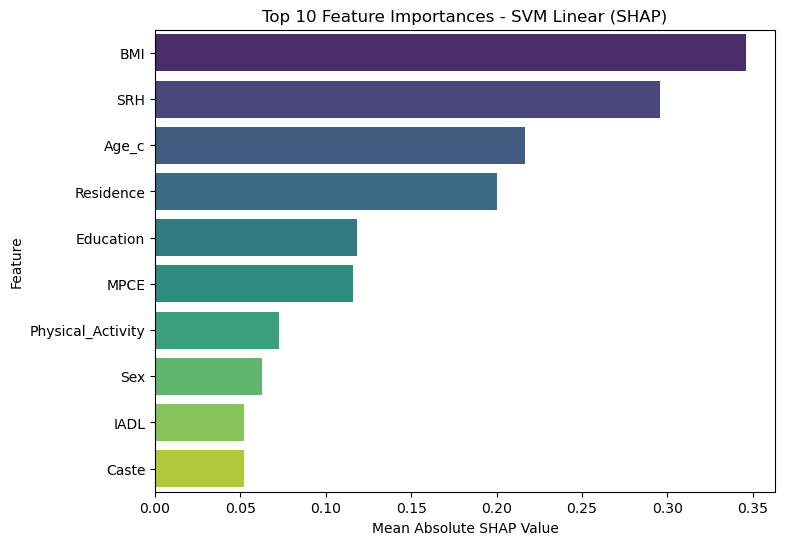

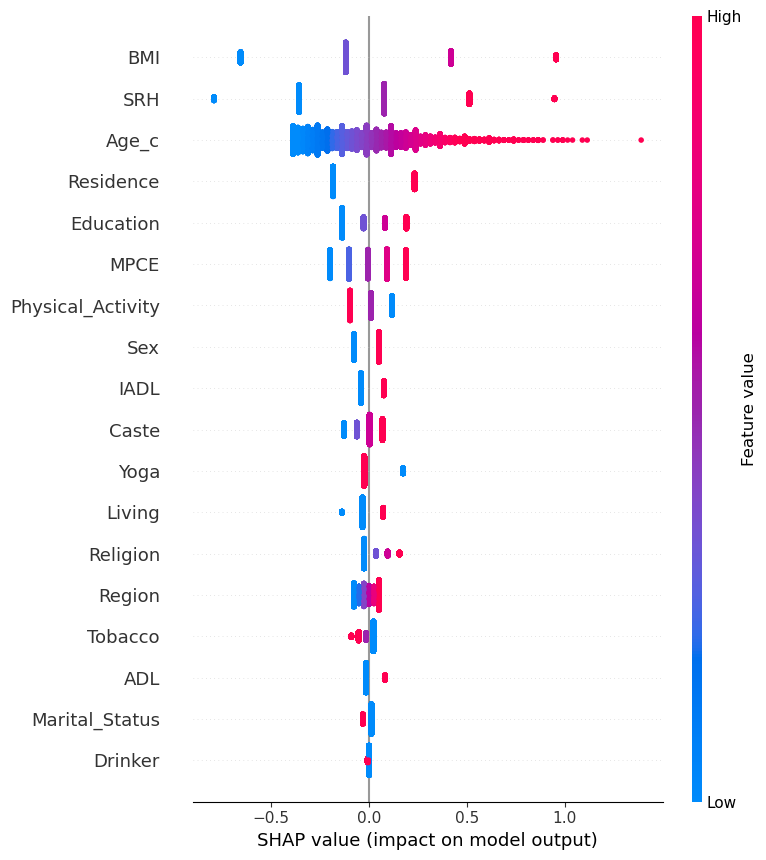

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve

plt.figure(figsize=(8,6))
sns.barplot(
    x='SHAP Importance',
    y='Feature',
    data=shap_importance.head(10),
    palette='viridis'
)
plt.xlabel('Mean Absolute SHAP Value')
plt.ylabel('Feature')
plt.title('Top 10 Feature Importances - SVM Linear (SHAP)')
plt.show()

# Optional: SHAP summary plot
shap.summary_plot(shap_values.values, x_test_scaled, feature_names=x_train.columns)

In [18]:
#For smote data
#SVM Model
from sklearn.svm import SVC

model=SVC(kernel='linear',C=1)
model.fit(x_train_smote,y_train_smote)
y_pred=model.predict(x_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {round(accuracy, 2)}")
print("Classification Report:")
print(classification_report(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred)
cm

Accuracy: 0.65
Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.65      0.70      7629
           1       0.51      0.66      0.58      4309

    accuracy                           0.65     11938
   macro avg       0.64      0.65      0.64     11938
weighted avg       0.68      0.65      0.66     11938



array([[4930, 2699],
       [1449, 2860]])

In [15]:
#3.ANN

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.optimizers import SGD
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             confusion_matrix, roc_auc_score, precision_recall_curve,
                             cohen_kappa_score, matthews_corrcoef, balanced_accuracy_score)

# Build ANN
model_ann = Sequential([
    Flatten(input_shape=(x_train_scaled.shape[1],)),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
])

# Compile model
model_ann.compile(optimizer=SGD(learning_rate=0.01), loss='binary_crossentropy', metrics=['accuracy'])

# Train model
history = model_ann.fit(x_train_scaled, y_train, epochs=50, batch_size=32, validation_split=0.2, verbose=0)

# Predict
y_prob = model_ann.predict(x_test_scaled).flatten()
y_pred = (y_prob >= 0.5).astype(int)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
TP = cm[1, 1]
TN = cm[0, 0]
FP = cm[0, 1]
FN = cm[1, 0]

# Metrics calculation
accuracy = accuracy_score(y_test, y_pred)
sensitivity = recall_score(y_test, y_pred)
specificity = TN / (TN + FP)
precision = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
npv = TN / (TN + FN)
balanced_acc = balanced_accuracy_score(y_test, y_pred)
mcc = matthews_corrcoef(y_test, y_pred)
kappa = cohen_kappa_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

# PR-AUC
precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_prob)
pr_auc = np.trapz(recall_curve, precision_curve)

# Display metrics
metrics = {
    "Accuracy": round(accuracy, 4),
    "Sensitivity/Recall": round(sensitivity, 4),
    "Specificity": round(specificity, 4),
    "Precision": round(precision, 4),
    "F1 Score": round(f1, 4),
    "NPV": round(npv, 4),
    "Balanced Accuracy": round(balanced_acc, 4),
    "MCC": round(mcc, 4),
    "Cohen's Kappa": round(kappa, 4),
    "AUC-ROC": round(auc, 4),
    "PR-AUC": round(pr_auc, 4)
}

for k, v in metrics.items():
    print(f"{k}: {v}")

C:\Users\kiran\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


374/374 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Accuracy: 0.7082
Sensitivity/Recall: 0.4275
Specificity: 0.8668
Precision: 0.6445
F1 Score: 0.514
NPV: 0.7283
Balanced Accuracy: 0.6472
MCC: 0.3312
Cohen's Kappa: 0.3176
AUC-ROC: 0.7391
PR-AUC: 0.2509


C:\Users\kiran\AppData\Local\Temp\ipykernel_7276\3149938937.py:49: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pr_auc = np.trapz(recall_curve, precision_curve)


In [20]:
import shap
import numpy as np
import pandas as pd

# Fix: flatten output
explainer = shap.KernelExplainer(
    lambda x: model_ann.predict(x).flatten(), 
    x_train_scaled[:100]
)

shap_values = explainer.shap_values(x_test_scaled[:100], nsamples=100)

# Convert properly
shap_values = np.array(shap_values)

# Ensure correct shape
if shap_values.ndim > 2:
    shap_values = shap_values.squeeze()

shap_df = pd.DataFrame(shap_values, columns=x_train.columns)

# Feature importance
shap_importance = pd.DataFrame({
    'Feature': x_train.columns,
    'SHAP Importance': np.abs(shap_df).mean(axis=0)
}).sort_values(by='SHAP Importance', ascending=False)

print("Top 10 Important Features (SHAP):")
print(shap_importance.head(10))

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 


  0%|          | 0/100 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 704us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 658us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 745us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 637us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 648us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 653us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 638us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 625us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 670us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 784us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 650us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 640us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 


  0%|          | 0/100 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 754us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 802us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 666us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 832us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 934us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 960us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 923us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 989us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms

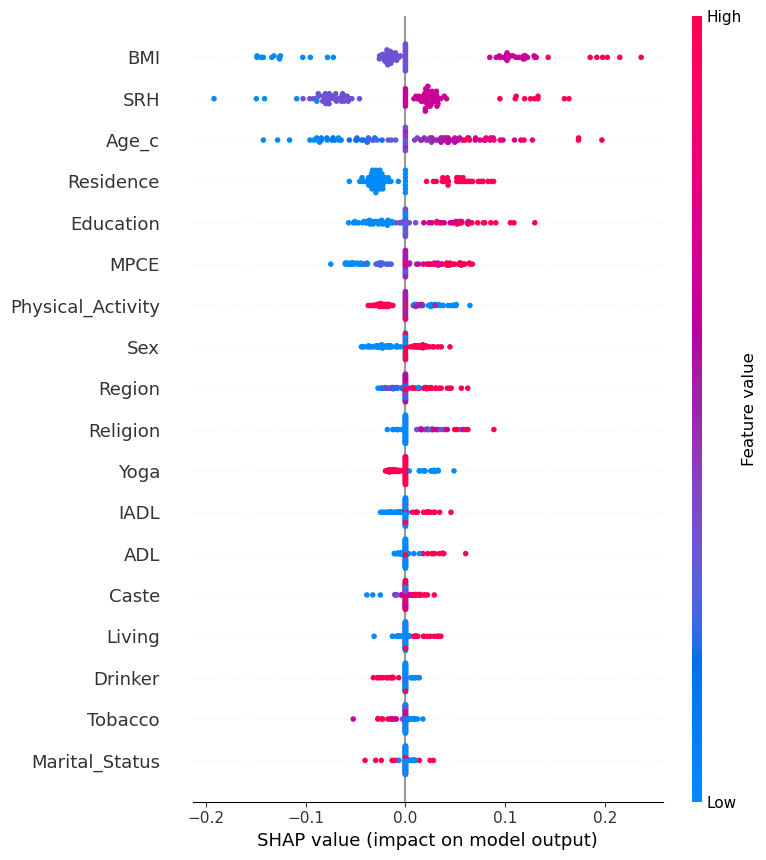

In [21]:
import shap
import numpy as np

# Step 1: Proper explainer (VERY IMPORTANT)
explainer = shap.KernelExplainer(
    lambda x: model_ann.predict(x).reshape(-1),   # <-- FIX HERE
    x_train_scaled[:100]
)

# Step 2: Compute SHAP values
shap_values = explainer.shap_values(x_test_scaled[:100], nsamples=100)

# Step 3: Convert to numpy
shap_vals = np.array(shap_values)

# Step 4: Fix dimensions
print("Before fix shape:", shap_vals.shape)

# Case handling
if shap_vals.ndim == 3:
    shap_vals = shap_vals[0]

# If shape is (features,1) → transpose
if shap_vals.shape[0] == x_train.shape[1]:
    shap_vals = shap_vals.T

print("After fix shape:", shap_vals.shape)

# Step 5: Final SHAP plot
shap.summary_plot(
    shap_vals,
    x_test_scaled[:100],
    feature_names=x_train.columns
)

In [16]:
#4.Decision Tree

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             confusion_matrix, roc_auc_score, precision_recall_curve,
                             cohen_kappa_score, matthews_corrcoef, balanced_accuracy_score)

# Build and train Decision Tree
model_dt = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
model_dt.fit(x_train, y_train)

# Predictions
y_pred = model_dt.predict(x_test)
y_prob = model_dt.predict_proba(x_test)[:, 1]  # probability for positive class

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
TP = cm[1, 1]
TN = cm[0, 0]
FP = cm[0, 1]
FN = cm[1, 0]

# Metrics calculation
accuracy = accuracy_score(y_test, y_pred)
sensitivity = recall_score(y_test, y_pred)
specificity = TN / (TN + FP)
precision = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
npv = TN / (TN + FN)
balanced_acc = balanced_accuracy_score(y_test, y_pred)
mcc = matthews_corrcoef(y_test, y_pred)
kappa = cohen_kappa_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

# PR-AUC
precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_prob)
pr_auc = np.trapz(recall_curve, precision_curve)

# Display metrics
metrics = {
    "Accuracy": round(accuracy, 4),
    "Sensitivity/Recall": round(sensitivity, 4),
    "Specificity": round(specificity, 4),
    "Precision": round(precision, 4),
    "F1 Score": round(f1, 4),
    "NPV": round(npv, 4),
    "Balanced Accuracy": round(balanced_acc, 4),
    "MCC": round(mcc, 4),
    "Cohen's Kappa": round(kappa, 4),
    "AUC-ROC": round(auc, 4),
    "PR-AUC": round(pr_auc, 4)
}

for k, v in metrics.items():
    print(f"{k}: {v}")

Accuracy: 0.6804
Sensitivity/Recall: 0.479
Specificity: 0.7942
Precision: 0.568
F1 Score: 0.5197
NPV: 0.7296
Balanced Accuracy: 0.6366
MCC: 0.2851
Cohen's Kappa: 0.2828
AUC-ROC: 0.6785
PR-AUC: 0.2151


C:\Users\kiran\AppData\Local\Temp\ipykernel_7276\2297484031.py:37: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pr_auc = np.trapz(recall_curve, precision_curve)


Top 10 Feature Importances (Decision Tree):
          Feature  Importance
9             BMI    0.512586
6             SRH    0.268903
1           Age_c    0.126206
0       Residence    0.092305
2             Sex    0.000000
3  Marital_Status    0.000000
5          Living    0.000000
4       Education    0.000000
7             ADL    0.000000
8            IADL    0.000000

Top 10 SHAP Feature Importances (Decision Tree):
                       Feature  SHAP Importance
BMI                        BMI         0.095861
SRH                        SRH         0.057084
Residence            Residence         0.033370
Age_c                    Age_c         0.028341
Sex                        Sex         0.000000
Marital_Status  Marital_Status         0.000000
Living                  Living         0.000000
Education            Education         0.000000
ADL                        ADL         0.000000
IADL                      IADL         0.000000


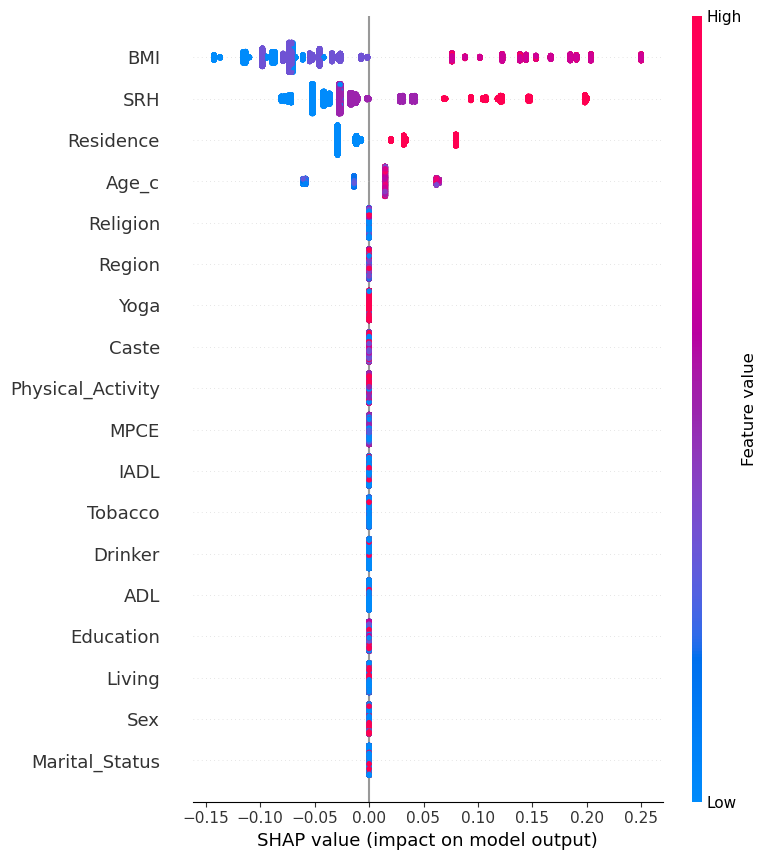

In [23]:
import pandas as pd
import shap
import matplotlib.pyplot as plt
import numpy as np

# -------------------------------
# Feature importance from tree
# -------------------------------
feature_importance = pd.DataFrame({
    'Feature': x_train.columns,
    'Importance': model_dt.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("Top 10 Feature Importances (Decision Tree):")
print(feature_importance.head(10))

# -------------------------------
# SHAP values for Decision Tree
# -------------------------------
explainer = shap.TreeExplainer(model_dt)
shap_values = explainer.shap_values(x_test)

# Convert to numpy
shap_values = np.array(shap_values)

# Fix: handle 3D output (samples, features, classes)
if shap_values.ndim == 3:
    shap_values = shap_values[:, :, 1]   # take class 1

# -------------------------------
# Convert to DataFrame
# -------------------------------
shap_df = pd.DataFrame(shap_values, columns=x_train.columns)

# -------------------------------
# Global SHAP importance
# -------------------------------
shap_importance = pd.DataFrame({
    'Feature': x_train.columns,
    'SHAP Importance': np.abs(shap_df).mean(axis=0)
}).sort_values(by='SHAP Importance', ascending=False)

print("\nTop 10 SHAP Feature Importances (Decision Tree):")
print(shap_importance.head(10))

# -------------------------------
# SHAP summary plot
# -------------------------------
shap.summary_plot(shap_values, x_test.values, feature_names=x_train.columns)

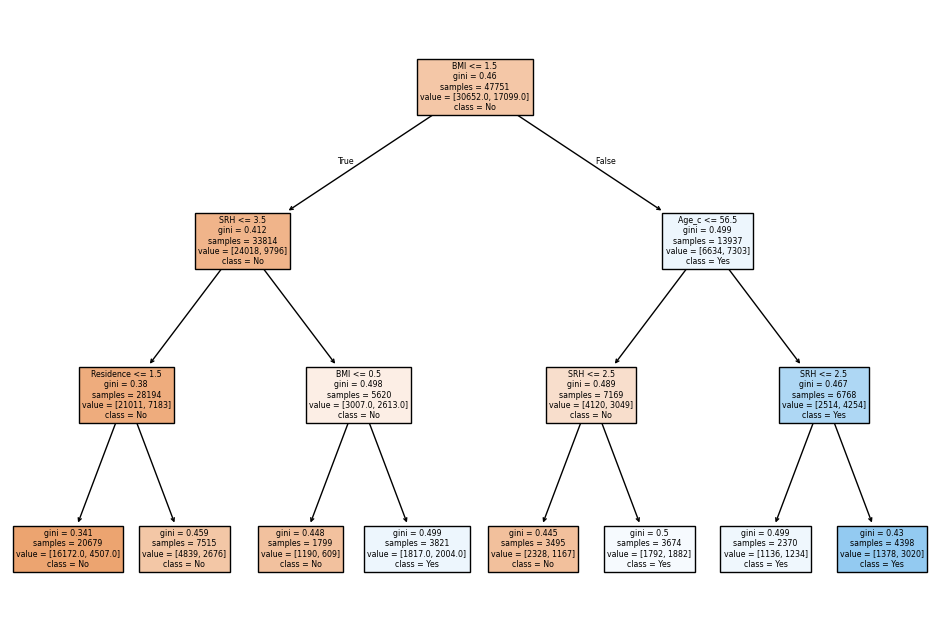

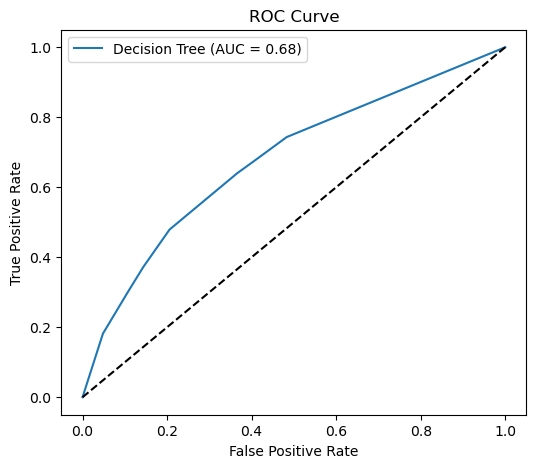

C:\Users\kiran\AppData\Local\Temp\ipykernel_11180\1013336451.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


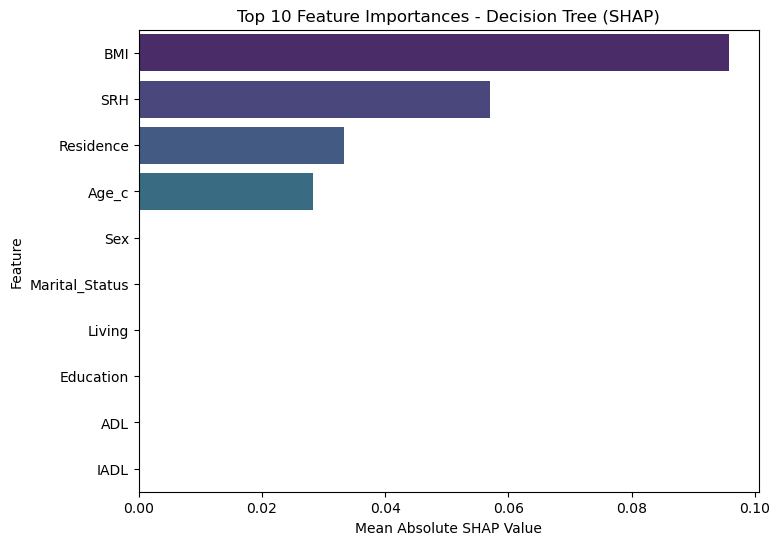

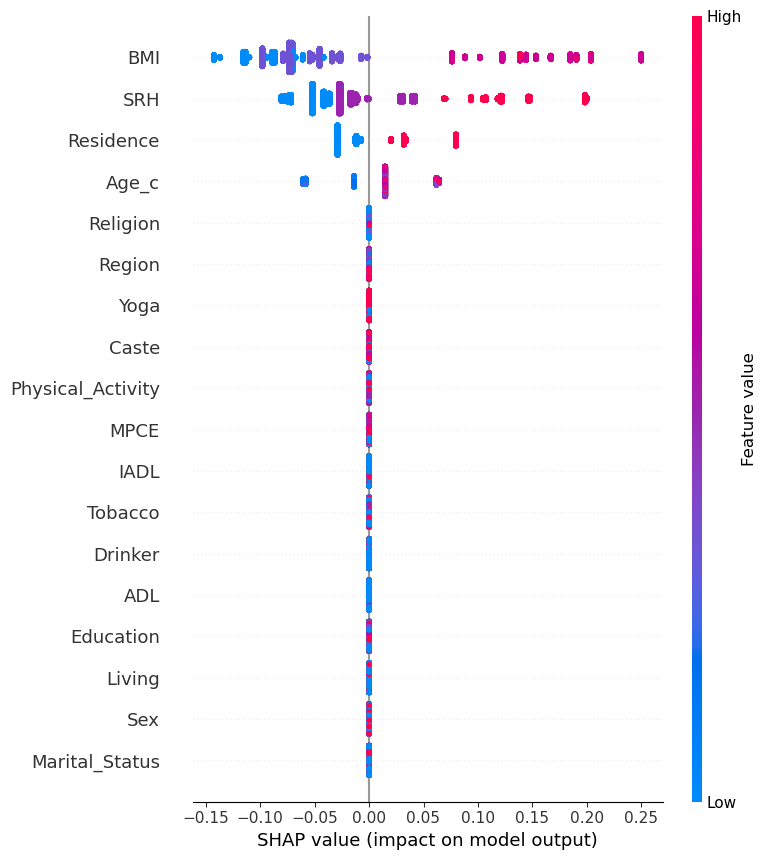

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve
from sklearn.tree import plot_tree

# Plot Decision Tree
plt.figure(figsize=(12,8))
plot_tree(model_dt,
          feature_names=x_train.columns,
          class_names=['No','Yes'],
          filled=True)
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f'Decision Tree (AUC = {auc:.2f})')
plt.plot([0,1],[0,1],'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# Feature Importance Bar Graph (Top 10 SHAP)
plt.figure(figsize=(8,6))
sns.barplot(
    x='SHAP Importance',
    y='Feature',
    data=shap_importance.head(10),
    palette='viridis'
)
plt.xlabel('Mean Absolute SHAP Value')
plt.ylabel('Feature')
plt.title('Top 10 Feature Importances - Decision Tree (SHAP)')
plt.show()

# Optional: SHAP summary plot (beeswarm)
shap.summary_plot(shap_values, x_test, feature_names=x_train.columns)

In [17]:
#5.Random Forest
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             confusion_matrix, roc_auc_score, precision_recall_curve,
                             cohen_kappa_score, matthews_corrcoef, balanced_accuracy_score)

# Build and train Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(x_train, y_train)

# Predictions
y_pred = rf_model.predict(x_test)
y_prob = rf_model.predict_proba(x_test)[:, 1]  # probability for positive class

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
TP = cm[1, 1]
TN = cm[0, 0]
FP = cm[0, 1]
FN = cm[1, 0]

# Metrics calculation
accuracy = accuracy_score(y_test, y_pred)
sensitivity = recall_score(y_test, y_pred)
specificity = TN / (TN + FP)
precision = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
npv = TN / (TN + FN)
balanced_acc = balanced_accuracy_score(y_test, y_pred)
mcc = matthews_corrcoef(y_test, y_pred)
kappa = cohen_kappa_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

# PR-AUC
precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_prob)
pr_auc = np.trapz(recall_curve, precision_curve)

# Display metrics
metrics = {
    "Accuracy": round(accuracy, 4),
    "Sensitivity/Recall": round(sensitivity, 4),
    "Specificity": round(specificity, 4),
    "Precision": round(precision, 4),
    "F1 Score": round(f1, 4),
    "NPV": round(npv, 4),
    "Balanced Accuracy": round(balanced_acc, 4),
    "MCC": round(mcc, 4),
    "Cohen's Kappa": round(kappa, 4),
    "AUC-ROC": round(auc, 4),
    "PR-AUC": round(pr_auc, 4)
}

for k, v in metrics.items():
    print(f"{k}: {v}")

Accuracy: 0.6916
Sensitivity/Recall: 0.4358
Specificity: 0.836
Precision: 0.6002
F1 Score: 0.505
NPV: 0.724
Balanced Accuracy: 0.6359
MCC: 0.2969
Cohen's Kappa: 0.2891
AUC-ROC: 0.718
PR-AUC: 0.2198


C:\Users\kiran\AppData\Local\Temp\ipykernel_7276\584625698.py:36: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pr_auc = np.trapz(recall_curve, precision_curve)


In [26]:
import shap
import pandas as pd
import numpy as np

# Feature importance from Random Forest
feature_importance = pd.DataFrame({
    'Feature': x_train.columns,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("Top 10 Feature Importances (Random Forest):")
print(feature_importance.head(10))

# SHAP values for Random Forest
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(x_test[:100])

# Check shape
print("shap_values type:", type(shap_values))
print("shap_values[1] shape:", np.array(shap_values[1]).shape)
print("x_train columns:", x_train.shape[1])

# Fix: use mean across correct axis
shap_vals = np.abs(shap_values[1])
if shap_vals.shape[1] != x_train.shape[1]:
    shap_vals = shap_vals.T

# Global SHAP importance
shap_importance = pd.DataFrame({
    'Feature': x_train.columns,
    'SHAP Importance': shap_vals.mean(axis=0)
}).sort_values(by='SHAP Importance', ascending=False)

print("Top 10 SHAP Feature Importances (Random Forest):")
print(shap_importance.head(10))

Top 10 Feature Importances (Random Forest):
              Feature  Importance
1               Age_c    0.213035
17             Region    0.088148
14               MPCE    0.085961
9                 BMI    0.072641
6                 SRH    0.066810
4           Education    0.063663
15              Caste    0.062506
13  Physical_Activity    0.051239
10            Tobacco    0.046620
16           Religion    0.044972
shap_values type: <class 'numpy.ndarray'>
shap_values[1] shape: (18, 2)
x_train columns: 18
Top 10 SHAP Feature Importances (Random Forest):
              Feature  SHAP Importance
1               Age_c         0.096932
6                 SRH         0.058892
13  Physical_Activity         0.050482
9                 BMI         0.032671
0           Residence         0.031298
4           Education         0.030011
15              Caste         0.020810
17             Region         0.016939
8                IADL         0.009246
5              Living         0.007139


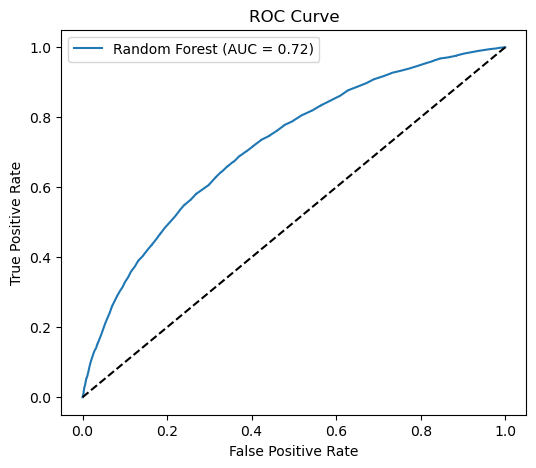

C:\Users\kiran\AppData\Local\Temp\ipykernel_11180\1017416022.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


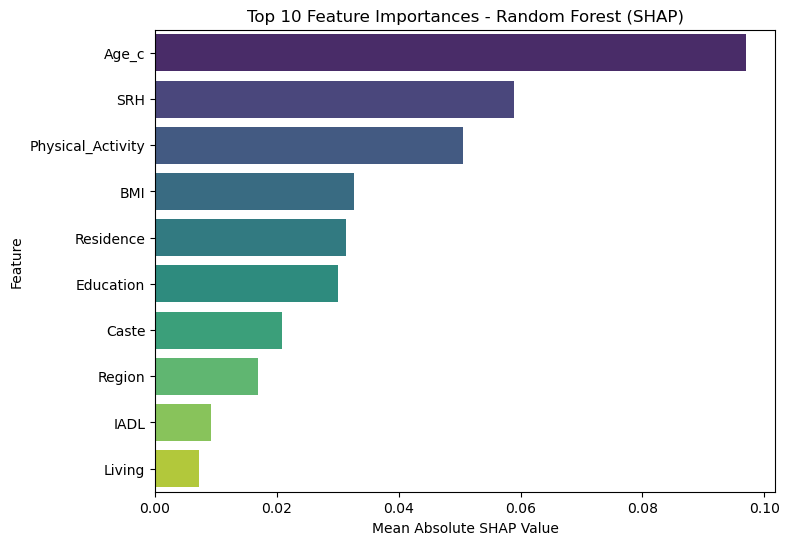

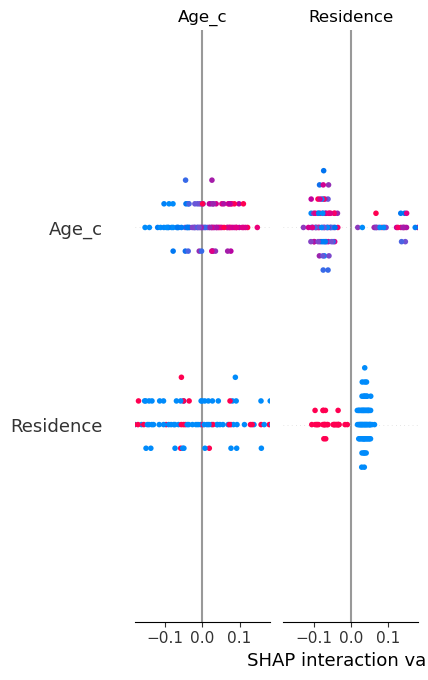

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve

shap_vals_fixed = np.array(shap_values)

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f'Random Forest (AUC = {auc:.2f})')
plt.plot([0,1],[0,1],'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# Feature Importance Bar Graph (Top 10 SHAP)
plt.figure(figsize=(8,6))
sns.barplot(
    x='SHAP Importance',
    y='Feature',
    data=shap_importance.head(10),
    palette='viridis'
)
plt.xlabel('Mean Absolute SHAP Value')
plt.ylabel('Feature')
plt.title('Top 10 Feature Importances - Random Forest (SHAP)')
plt.show()

# SHAP summary plot (bar type - avoids index bug)
shap.summary_plot(
    shap_vals_fixed,
    x_test.reset_index(drop=True).iloc[:100],
    feature_names=x_train.columns,
    plot_type="bar"   # <-- FIX HERE
)

In [18]:
#6. KNN

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             confusion_matrix, roc_auc_score, precision_recall_curve,
                             cohen_kappa_score, matthews_corrcoef, balanced_accuracy_score)

# Build and train KNN
model_knn = KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=2)
model_knn.fit(x_train_scaled, y_train)

# Predictions
y_pred = model_knn.predict(x_test_scaled)
y_prob = model_knn.predict_proba(x_test_scaled)[:, 1]

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
TP = cm[1, 1]
TN = cm[0, 0]
FP = cm[0, 1]
FN = cm[1, 0]

# Metrics calculation
accuracy = accuracy_score(y_test, y_pred)
sensitivity = recall_score(y_test, y_pred)
specificity = TN / (TN + FP)
precision = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
npv = TN / (TN + FN)
balanced_acc = balanced_accuracy_score(y_test, y_pred)
mcc = matthews_corrcoef(y_test, y_pred)
kappa = cohen_kappa_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

# PR-AUC
precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_prob)
pr_auc = np.trapz(recall_curve, precision_curve)

# Display metrics
metrics = {
    "Accuracy": round(accuracy, 4),
    "Sensitivity/Recall": round(sensitivity, 4),
    "Specificity": round(specificity, 4),
    "Precision": round(precision, 4),
    "F1 Score": round(f1, 4),
    "NPV": round(npv, 4),
    "Balanced Accuracy": round(balanced_acc, 4),
    "MCC": round(mcc, 4),
    "Cohen's Kappa": round(kappa, 4),
    "AUC-ROC": round(auc, 4),
    "PR-AUC": round(pr_auc, 4)
}

for k, v in metrics.items():
    print(f"{k}: {v}")

Accuracy: 0.6619
Sensitivity/Recall: 0.4163
Specificity: 0.8006
Precision: 0.5412
F1 Score: 0.4706
NPV: 0.7083
Balanced Accuracy: 0.6085
MCC: 0.2327
Cohen's Kappa: 0.2284
AUC-ROC: 0.6606
PR-AUC: 0.1661


C:\Users\kiran\AppData\Local\Temp\ipykernel_7276\98058833.py:37: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pr_auc = np.trapz(recall_curve, precision_curve)


In [29]:
import shap
import pandas as pd
import numpy as np

# SHAP values for KNN
explainer = shap.KernelExplainer(
    lambda x: model_knn.predict_proba(x)[:, 1],
    x_train_scaled[:100]
)
shap_values = explainer.shap_values(x_test_scaled[:100], nsamples=100)

# Convert to numpy
shap_vals = np.array(shap_values)

# Fix dimensions
if shap_vals.ndim == 3:
    shap_vals = shap_vals[0]
if shap_vals.shape[0] == x_train.shape[1]:
    shap_vals = shap_vals.T

# Global SHAP importance
shap_importance = pd.DataFrame({
    'Feature': x_train.columns,
    'SHAP Importance': np.abs(shap_vals).mean(axis=0)
}).sort_values(by='SHAP Importance', ascending=False)

print("Top 10 SHAP Feature Importances (KNN):")
print(shap_importance.head(10))

  0%|          | 0/100 [00:00<?, ?it/s]

Top 10 SHAP Feature Importances (KNN):
              Feature  SHAP Importance
0           Residence         0.049059
1               Age_c         0.042605
9                 BMI         0.039844
6                 SRH         0.034242
14               MPCE         0.027515
4           Education         0.023943
15              Caste         0.023776
12               Yoga         0.020624
13  Physical_Activity         0.019788
17             Region         0.018736


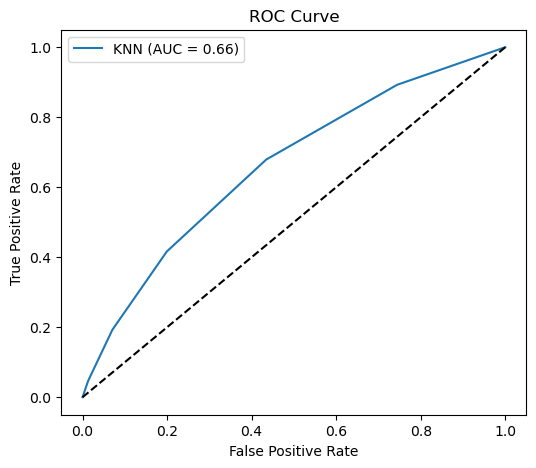

C:\Users\kiran\AppData\Local\Temp\ipykernel_11180\1177842979.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


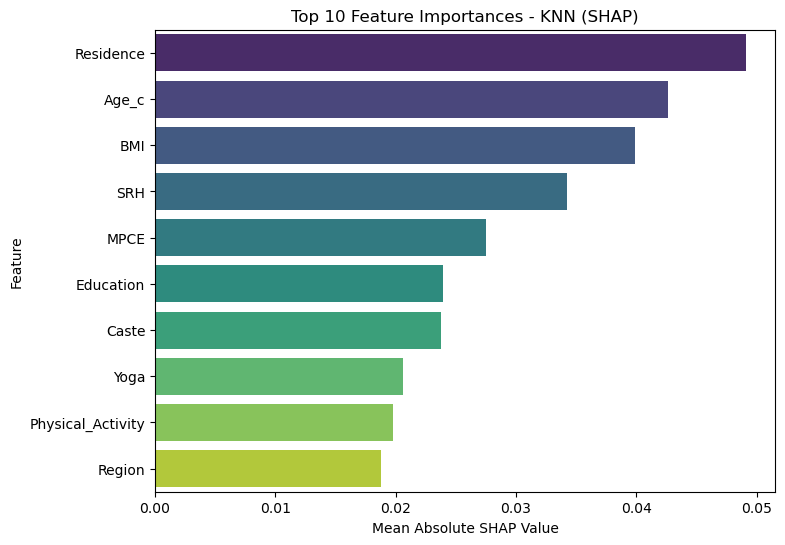

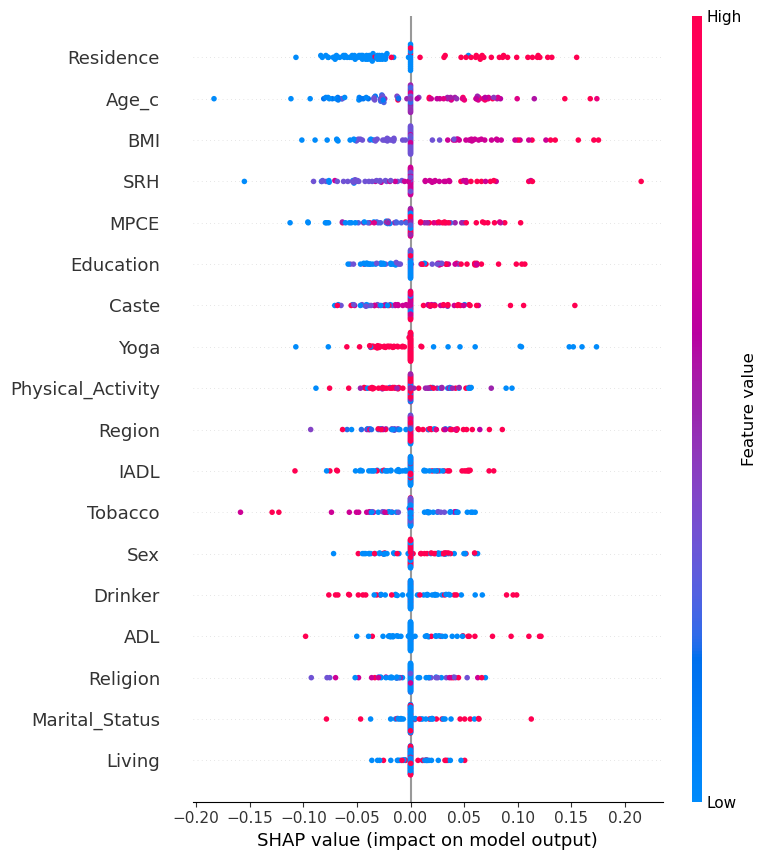

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'KNN (AUC = {auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# Feature Importance Bar Graph (Top 10 SHAP)
plt.figure(figsize=(8, 6))
sns.barplot(
    x='SHAP Importance',
    y='Feature',
    data=shap_importance.head(10),
    palette='viridis'
)
plt.xlabel('Mean Absolute SHAP Value')
plt.ylabel('Feature')
plt.title('Top 10 Feature Importances - KNN (SHAP)')
plt.show()

# SHAP summary plot (beeswarm)
shap.summary_plot(shap_vals, x_test_scaled[:100], feature_names=x_train.columns)

In [19]:
#7. Naive Bayes

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             confusion_matrix, roc_auc_score, precision_recall_curve,
                             cohen_kappa_score, matthews_corrcoef, balanced_accuracy_score)

# Build and train Naive Bayes
model_nb = MultinomialNB()
model_nb.fit(x_train, y_train)

# Predictions
y_pred = model_nb.predict(x_test)
y_prob = model_nb.predict_proba(x_test)[:, 1]

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
TP = cm[1, 1]
TN = cm[0, 0]
FP = cm[0, 1]
FN = cm[1, 0]

# Metrics calculation
accuracy = accuracy_score(y_test, y_pred)
sensitivity = recall_score(y_test, y_pred)
specificity = TN / (TN + FP)
precision = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
npv = TN / (TN + FN)
balanced_acc = balanced_accuracy_score(y_test, y_pred)
mcc = matthews_corrcoef(y_test, y_pred)
kappa = cohen_kappa_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

# PR-AUC
precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_prob)
pr_auc = np.trapz(recall_curve, precision_curve)

# Display metrics
metrics = {
    "Accuracy": round(accuracy, 4),
    "Sensitivity/Recall": round(sensitivity, 4),
    "Specificity": round(specificity, 4),
    "Precision": round(precision, 4),
    "F1 Score": round(f1, 4),
    "NPV": round(npv, 4),
    "Balanced Accuracy": round(balanced_acc, 4),
    "MCC": round(mcc, 4),
    "Cohen's Kappa": round(kappa, 4),
    "AUC-ROC": round(auc, 4),
    "PR-AUC": round(pr_auc, 4)
}

for k, v in metrics.items():
    print(f"{k}: {v}")

Accuracy: 0.6692
Sensitivity/Recall: 0.2769
Specificity: 0.8908
Precision: 0.5888
F1 Score: 0.3766
NPV: 0.6856
Balanced Accuracy: 0.5838
MCC: 0.2145
Cohen's Kappa: 0.1895
AUC-ROC: 0.6684
PR-AUC: 0.1703


C:\Users\kiran\AppData\Local\Temp\ipykernel_7276\3393895287.py:37: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pr_auc = np.trapz(recall_curve, precision_curve)


In [32]:
import shap
import pandas as pd
import numpy as np

# SHAP values for Naive Bayes
explainer = shap.KernelExplainer(
    lambda x: model_nb.predict_proba(x)[:, 1],
    x_train[:100]
)
shap_values = explainer.shap_values(x_test[:100], nsamples=100)

# Convert to numpy
shap_vals = np.array(shap_values)

# Fix dimensions
if shap_vals.ndim == 3:
    shap_vals = shap_vals[0]
if shap_vals.shape[0] == x_train.shape[1]:
    shap_vals = shap_vals.T

# Global SHAP importance
shap_importance = pd.DataFrame({
    'Feature': x_train.columns,
    'SHAP Importance': np.abs(shap_vals).mean(axis=0)
}).sort_values(by='SHAP Importance', ascending=False)

print("Top 10 SHAP Feature Importances (Naive Bayes):")
print(shap_importance.head(10))

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but MultinomialNB was fitted with feature names
  warnings.warn(


  0%|          | 0/100 [00:00<?, ?it/s]

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but MultinomialNB was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but MultinomialNB was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but MultinomialNB was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but MultinomialNB was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but MultinomialNB was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packag

Top 10 SHAP Feature Importances (Naive Bayes):
              Feature  SHAP Importance
10            Tobacco         0.057362
13  Physical_Activity         0.032194
9                 BMI         0.031432
11            Drinker         0.029013
14               MPCE         0.016478
7                 ADL         0.015739
4           Education         0.014394
8                IADL         0.011316
12               Yoga         0.010974
6                 SRH         0.006403


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but MultinomialNB was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but MultinomialNB was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but MultinomialNB was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but MultinomialNB was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but MultinomialNB was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packag

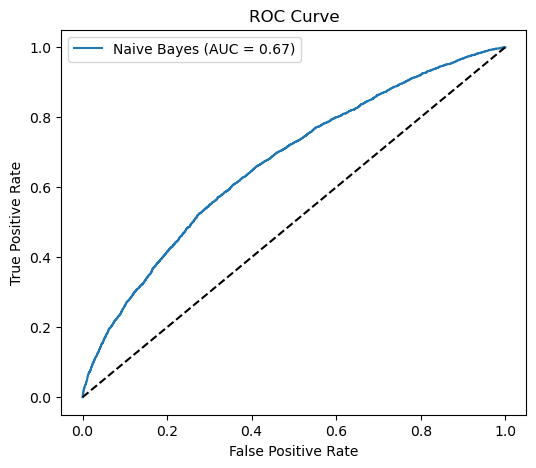

C:\Users\kiran\AppData\Local\Temp\ipykernel_11180\1372969151.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


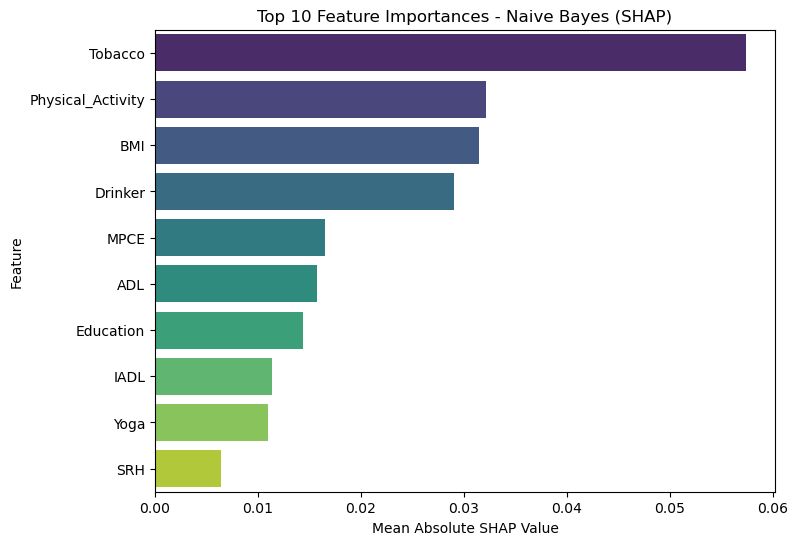

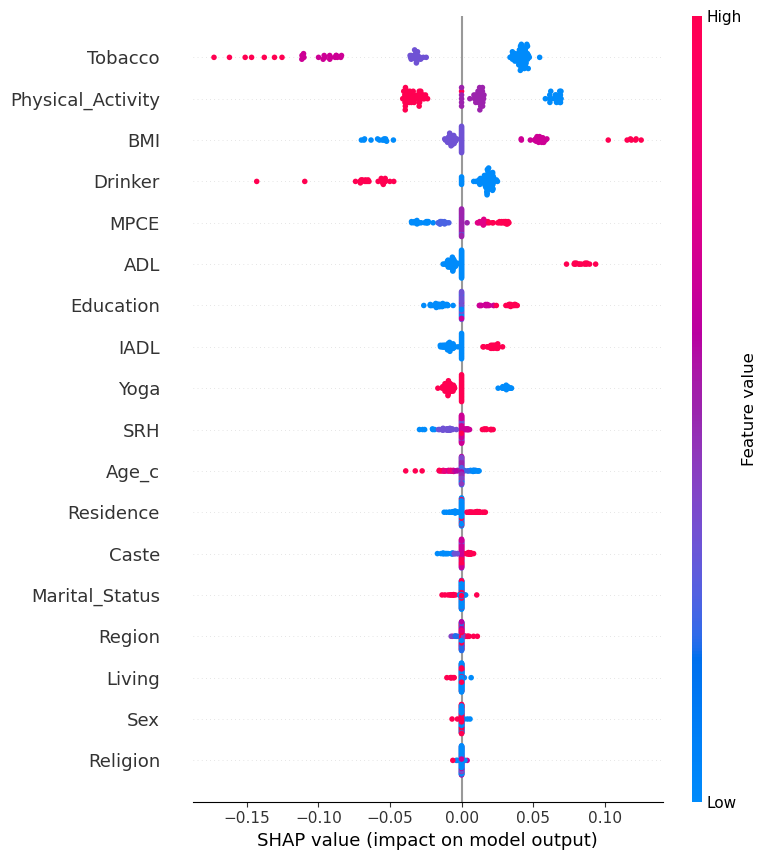

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'Naive Bayes (AUC = {auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# Feature Importance Bar Graph (Top 10 SHAP)
plt.figure(figsize=(8, 6))
sns.barplot(
    x='SHAP Importance',
    y='Feature',
    data=shap_importance.head(10),
    palette='viridis'
)
plt.xlabel('Mean Absolute SHAP Value')
plt.ylabel('Feature')
plt.title('Top 10 Feature Importances - Naive Bayes (SHAP)')
plt.show()

# SHAP summary plot (beeswarm)
shap.summary_plot(shap_vals, x_test[:100], feature_names=x_train.columns)

In [20]:
#8. Gradient Boosting

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             confusion_matrix, roc_auc_score, precision_recall_curve,
                             cohen_kappa_score, matthews_corrcoef, balanced_accuracy_score)

# Build and train Gradient Boosting
model_gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
model_gb.fit(x_train_scaled, y_train)

# Predictions
y_pred = model_gb.predict(x_test_scaled)
y_prob = model_gb.predict_proba(x_test_scaled)[:, 1]

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
TP = cm[1, 1]
TN = cm[0, 0]
FP = cm[0, 1]
FN = cm[1, 0]

# Metrics calculation
accuracy = accuracy_score(y_test, y_pred)
sensitivity = recall_score(y_test, y_pred)
specificity = TN / (TN + FP)
precision = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
npv = TN / (TN + FN)
balanced_acc = balanced_accuracy_score(y_test, y_pred)
mcc = matthews_corrcoef(y_test, y_pred)
kappa = cohen_kappa_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

# PR-AUC
precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_prob)
pr_auc = np.trapz(recall_curve, precision_curve)

# Display metrics
metrics = {
    "Accuracy": round(accuracy, 4),
    "Sensitivity/Recall": round(sensitivity, 4),
    "Specificity": round(specificity, 4),
    "Precision": round(precision, 4),
    "F1 Score": round(f1, 4),
    "NPV": round(npv, 4),
    "Balanced Accuracy": round(balanced_acc, 4),
    "MCC": round(mcc, 4),
    "Cohen's Kappa": round(kappa, 4),
    "AUC-ROC": round(auc, 4),
    "PR-AUC": round(pr_auc, 4)
}

for k, v in metrics.items():
    print(f"{k}: {v}")

Accuracy: 0.7101
Sensitivity/Recall: 0.4351
Specificity: 0.8654
Precision: 0.6461
F1 Score: 0.52
NPV: 0.7306
Balanced Accuracy: 0.6503
MCC: 0.3365
Cohen's Kappa: 0.3235
AUC-ROC: 0.7457
PR-AUC: 0.2619


C:\Users\kiran\AppData\Local\Temp\ipykernel_7276\875509188.py:37: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pr_auc = np.trapz(recall_curve, precision_curve)


In [35]:
import shap
import pandas as pd
import numpy as np

# SHAP values for Gradient Boosting
explainer = shap.TreeExplainer(model_gb)
shap_values = explainer.shap_values(x_test_scaled)

# Convert to numpy
shap_vals = np.array(shap_values)

# Fix dimensions
if shap_vals.ndim == 3:
    shap_vals = shap_vals[0]
if shap_vals.shape[0] == x_train.shape[1]:
    shap_vals = shap_vals.T

# Global SHAP importance
shap_importance = pd.DataFrame({
    'Feature': x_train.columns,
    'SHAP Importance': np.abs(shap_vals).mean(axis=0)
}).sort_values(by='SHAP Importance', ascending=False)

print("Top 10 SHAP Feature Importances (Gradient Boosting):")
print(shap_importance.head(10))

Top 10 SHAP Feature Importances (Gradient Boosting):
              Feature  SHAP Importance
9                 BMI         0.345337
6                 SRH         0.303547
1               Age_c         0.269443
0           Residence         0.178572
14               MPCE         0.142579
4           Education         0.133096
13  Physical_Activity         0.112326
17             Region         0.087804
2                 Sex         0.073073
15              Caste         0.065161


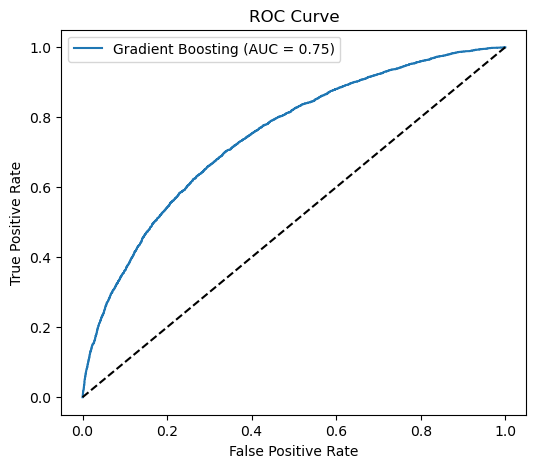

C:\Users\kiran\AppData\Local\Temp\ipykernel_11180\661727831.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


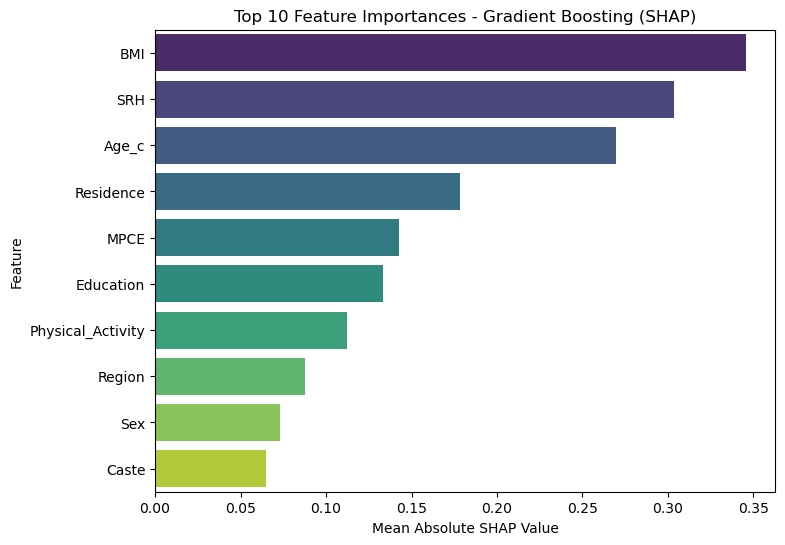

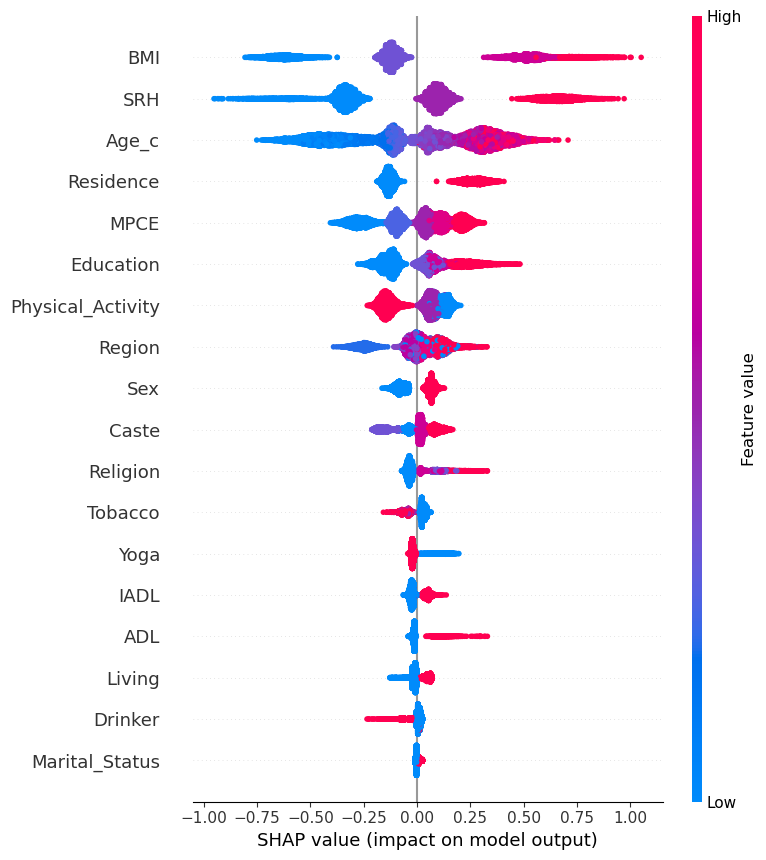

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'Gradient Boosting (AUC = {auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# Feature Importance Bar Graph (Top 10 SHAP)
plt.figure(figsize=(8, 6))
sns.barplot(
    x='SHAP Importance',
    y='Feature',
    data=shap_importance.head(10),
    palette='viridis'
)
plt.xlabel('Mean Absolute SHAP Value')
plt.ylabel('Feature')
plt.title('Top 10 Feature Importances - Gradient Boosting (SHAP)')
plt.show()

# SHAP summary plot (beeswarm)
shap.summary_plot(shap_vals, x_test_scaled, feature_names=x_train.columns)

In [21]:
#9. AdaBoost

from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             confusion_matrix, roc_auc_score, precision_recall_curve,
                             cohen_kappa_score, matthews_corrcoef, balanced_accuracy_score)

# Build and train AdaBoost
model_ada = AdaBoostClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
model_ada.fit(x_train_scaled, y_train)

# Predictions
y_pred = model_ada.predict(x_test_scaled)
y_prob = model_ada.predict_proba(x_test_scaled)[:, 1]

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
TP = cm[1, 1]
TN = cm[0, 0]
FP = cm[0, 1]
FN = cm[1, 0]

# Metrics calculation
accuracy = accuracy_score(y_test, y_pred)
sensitivity = recall_score(y_test, y_pred)
specificity = TN / (TN + FP)
precision = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
npv = TN / (TN + FN)
balanced_acc = balanced_accuracy_score(y_test, y_pred)
mcc = matthews_corrcoef(y_test, y_pred)
kappa = cohen_kappa_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

# PR-AUC
precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_prob)
pr_auc = np.trapz(recall_curve, precision_curve)

# Display metrics
metrics = {
    "Accuracy": round(accuracy, 4),
    "Sensitivity/Recall": round(sensitivity, 4),
    "Specificity": round(specificity, 4),
    "Precision": round(precision, 4),
    "F1 Score": round(f1, 4),
    "NPV": round(npv, 4),
    "Balanced Accuracy": round(balanced_acc, 4),
    "MCC": round(mcc, 4),
    "Cohen's Kappa": round(kappa, 4),
    "AUC-ROC": round(auc, 4),
    "PR-AUC": round(pr_auc, 4)
}

for k, v in metrics.items():
    print(f"{k}: {v}")

Accuracy: 0.6911
Sensitivity/Recall: 0.2957
Specificity: 0.9144
Precision: 0.6611
F1 Score: 0.4086
NPV: 0.6968
Balanced Accuracy: 0.605
MCC: 0.2742
Cohen's Kappa: 0.2388
AUC-ROC: 0.7237
PR-AUC: 0.2303


C:\Users\kiran\AppData\Local\Temp\ipykernel_7276\2320809763.py:37: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pr_auc = np.trapz(recall_curve, precision_curve)


In [38]:
import shap
import pandas as pd
import numpy as np

# SHAP values for AdaBoost (KernelExplainer instead of TreeExplainer)
explainer = shap.KernelExplainer(
    lambda x: model_ada.predict_proba(x)[:, 1],
    x_train_scaled[:100]
)
shap_values = explainer.shap_values(x_test_scaled[:100], nsamples=100)

# Convert to numpy
shap_vals = np.array(shap_values)

# Fix dimensions
if shap_vals.ndim == 3:
    shap_vals = shap_vals[0]
if shap_vals.shape[0] == x_train.shape[1]:
    shap_vals = shap_vals.T

# Global SHAP importance
shap_importance = pd.DataFrame({
    'Feature': x_train.columns,
    'SHAP Importance': np.abs(shap_vals).mean(axis=0)
}).sort_values(by='SHAP Importance', ascending=False)

print("Top 10 SHAP Feature Importances (AdaBoost):")
print(shap_importance.head(10))

  0%|          | 0/100 [00:00<?, ?it/s]

Top 10 SHAP Feature Importances (AdaBoost):
              Feature  SHAP Importance
9                 BMI         0.065876
6                 SRH         0.045411
0           Residence         0.035911
1               Age_c         0.035843
14               MPCE         0.015875
13  Physical_Activity         0.014473
4           Education         0.003186
15              Caste         0.002172
17             Region         0.000076
5              Living         0.000072


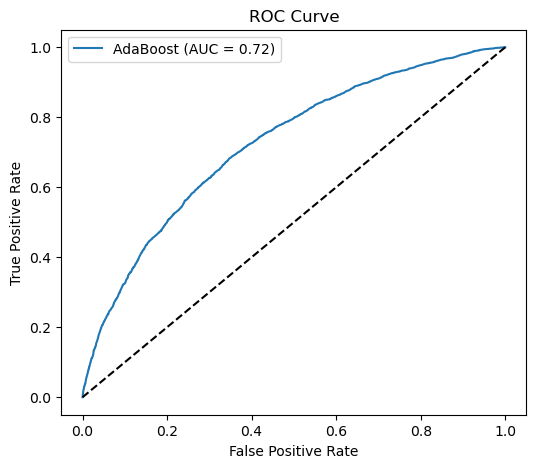

C:\Users\kiran\AppData\Local\Temp\ipykernel_11180\3396988505.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


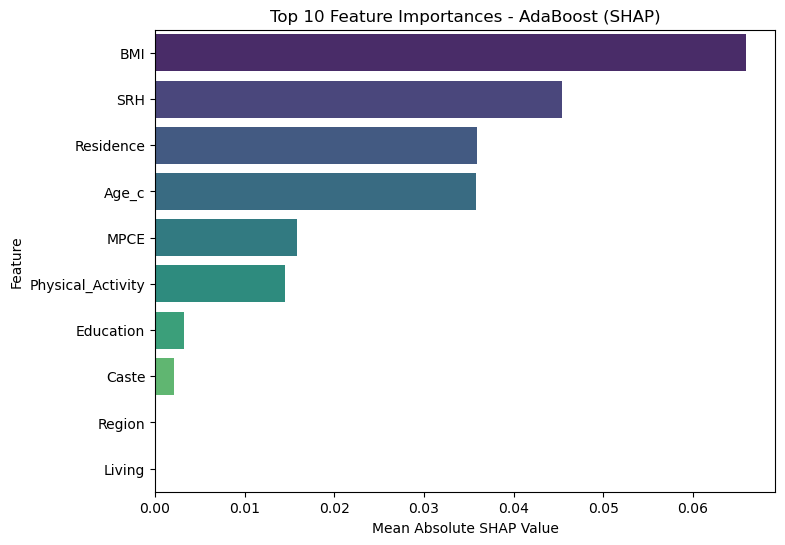

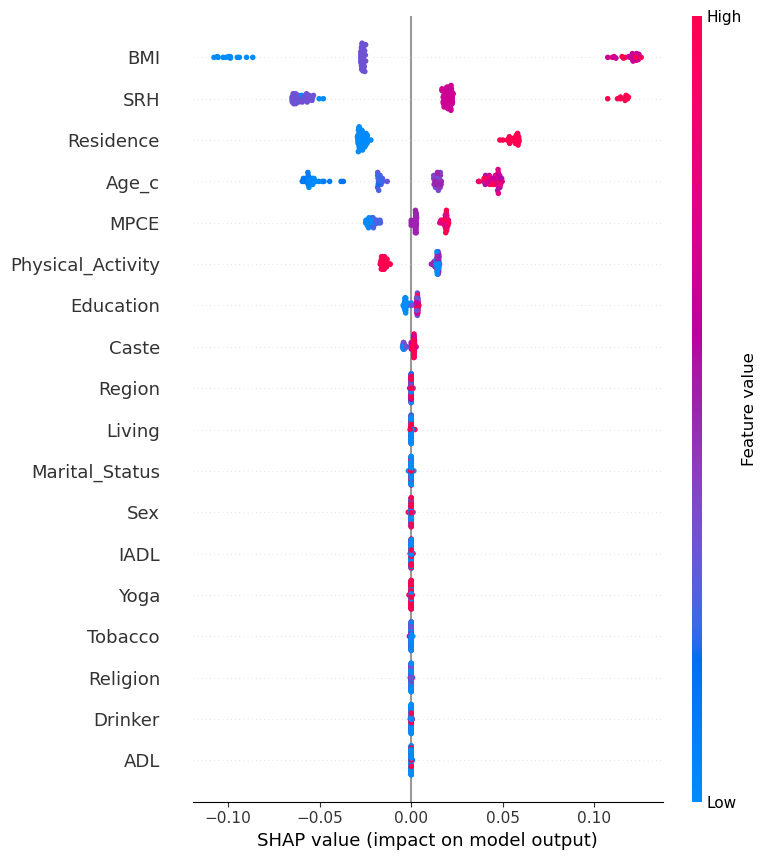

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'AdaBoost (AUC = {auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# Feature Importance Bar Graph (Top 10 SHAP)
plt.figure(figsize=(8, 6))
sns.barplot(
    x='SHAP Importance',
    y='Feature',
    data=shap_importance.head(10),
    palette='viridis'
)
plt.xlabel('Mean Absolute SHAP Value')
plt.ylabel('Feature')
plt.title('Top 10 Feature Importances - AdaBoost (SHAP)')
plt.show()

# SHAP summary plot
shap.summary_plot(shap_vals, x_test_scaled[:100], feature_names=x_train.columns)

In [40]:
import sys
!{sys.executable} -m pip install xgboost

Defaulting to user installation because normal site-packages is not writeable


In [22]:
#10. XGBoost

from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             confusion_matrix, roc_auc_score, precision_recall_curve,
                             cohen_kappa_score, matthews_corrcoef, balanced_accuracy_score)
import numpy as np

# Build and train XGBoost
model_xgb = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42, use_label_encoder=False, eval_metric='logloss')
model_xgb.fit(x_train_scaled, y_train)

# Predictions
y_pred = model_xgb.predict(x_test_scaled)
y_prob = model_xgb.predict_proba(x_test_scaled)[:, 1]

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
TP = cm[1, 1]
TN = cm[0, 0]
FP = cm[0, 1]
FN = cm[1, 0]

# Metrics calculation
accuracy = accuracy_score(y_test, y_pred)
sensitivity = recall_score(y_test, y_pred)
specificity = TN / (TN + FP)
precision = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
npv = TN / (TN + FN)
balanced_acc = balanced_accuracy_score(y_test, y_pred)
mcc = matthews_corrcoef(y_test, y_pred)
kappa = cohen_kappa_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

# PR-AUC
precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_prob)
pr_auc = np.trapz(recall_curve, precision_curve)

# Display metrics
metrics = {
    "Accuracy": round(accuracy, 4),
    "Sensitivity/Recall": round(sensitivity, 4),
    "Specificity": round(specificity, 4),
    "Precision": round(precision, 4),
    "F1 Score": round(f1, 4),
    "NPV": round(npv, 4),
    "Balanced Accuracy": round(balanced_acc, 4),
    "MCC": round(mcc, 4),
    "Cohen's Kappa": round(kappa, 4),
    "AUC-ROC": round(auc, 4),
    "PR-AUC": round(pr_auc, 4)
}

for k, v in metrics.items():
    print(f"{k}: {v}")

Accuracy: 0.712
Sensitivity/Recall: 0.4398
Specificity: 0.8658
Precision: 0.6492
F1 Score: 0.5243
NPV: 0.7323
Balanced Accuracy: 0.6528
MCC: 0.3414
Cohen's Kappa: 0.3286
AUC-ROC: 0.7457
PR-AUC: 0.2616


C:\Users\kiran\AppData\Roaming\Python\Python313\site-packages\xgboost\training.py:200: UserWarning: [13:09:13] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\kiran\AppData\Local\Temp\ipykernel_7276\3005066021.py:38: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pr_auc = np.trapz(recall_curve, precision_curve)


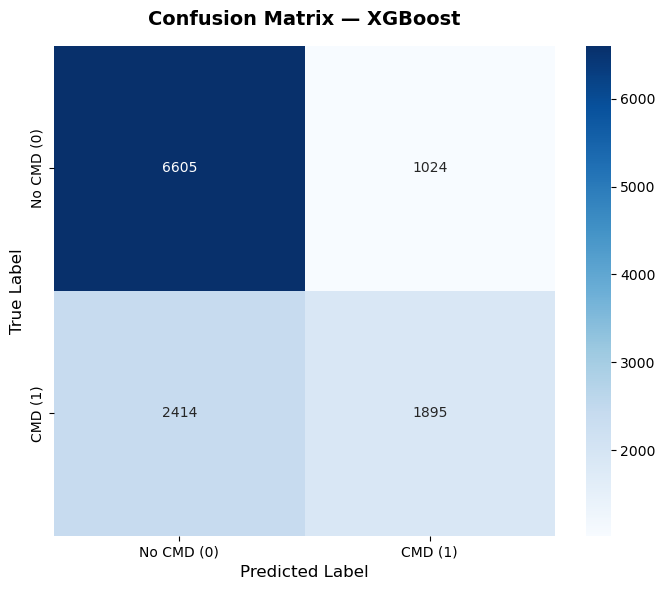

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Assuming y_test and y_pred_xgb are already defined
y_pred_xgb = model_xgb.predict(x_test_scaled)
cm = confusion_matrix(y_test, y_pred_xgb)

fig, ax = plt.subplots(figsize=(7, 6))

# Set background colors to white
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

# Generate heatmap - Removed linewidths for a cleaner look on white
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No CMD (0)', 'CMD (1)'],
            yticklabels=['No CMD (0)', 'CMD (1)'],
            ax=ax, cbar=True)

# Update text colors to black for contrast against white background
ax.set_xlabel('Predicted Label', fontsize=12, color='black')
ax.set_ylabel('True Label', fontsize=12, color='black')
ax.set_title('Confusion Matrix — XGBoost', fontsize=14, fontweight='bold', color='black', pad=15)
ax.tick_params(colors='black')

plt.tight_layout()
# Save with white facecolor
plt.savefig('confusion_matrix_xgboost_white.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

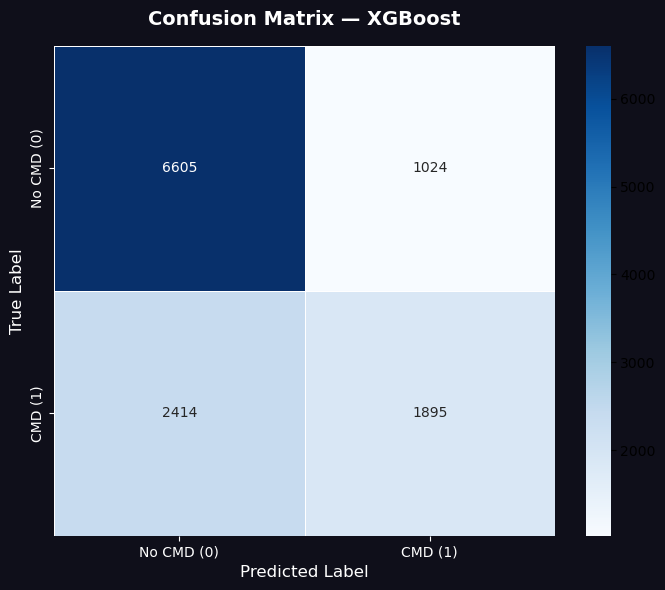

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

y_pred_xgb = model_xgb.predict(x_test_scaled)
cm = confusion_matrix(y_test, y_pred_xgb)

fig, ax = plt.subplots(figsize=(7, 6))
fig.patch.set_facecolor('#0f0f1a')
ax.set_facecolor('#0f0f1a')

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No CMD (0)', 'CMD (1)'],
            yticklabels=['No CMD (0)', 'CMD (1)'],
            ax=ax, linewidths=0.5)

ax.set_xlabel('Predicted Label', fontsize=12, color='white')
ax.set_ylabel('True Label', fontsize=12, color='white')
ax.set_title('Confusion Matrix — XGBoost', fontsize=14, fontweight='bold', color='white', pad=15)
ax.tick_params(colors='white')
plt.tight_layout()
plt.savefig('confusion_matrix_xgboost.png', dpi=150, bbox_inches='tight', facecolor='#0f0f1a')
plt.show()

In [43]:
import shap
import pandas as pd
import numpy as np

# SHAP values for XGBoost (KernelExplainer instead of TreeExplainer)
explainer = shap.KernelExplainer(
    lambda x: model_xgb.predict_proba(x)[:, 1],
    x_train_scaled[:100]
)
shap_values = explainer.shap_values(x_test_scaled[:100], nsamples=100)

# Convert to numpy
shap_vals = np.array(shap_values)

# Fix dimensions
if shap_vals.ndim == 3:
    shap_vals = shap_vals[0]
if shap_vals.shape[0] == x_train.shape[1]:
    shap_vals = shap_vals.T

# Global SHAP importance
shap_importance = pd.DataFrame({
    'Feature': x_train.columns,
    'SHAP Importance': np.abs(shap_vals).mean(axis=0)
}).sort_values(by='SHAP Importance', ascending=False)

print("Top 10 SHAP Feature Importances (XGBoost):")
print(shap_importance.head(10))

  0%|          | 0/100 [00:00<?, ?it/s]

Top 10 SHAP Feature Importances (XGBoost):
              Feature  SHAP Importance
9                 BMI         0.066903
1               Age_c         0.052020
6                 SRH         0.050845
0           Residence         0.032115
14               MPCE         0.024618
4           Education         0.023034
13  Physical_Activity         0.017548
17             Region         0.017133
2                 Sex         0.009151
16           Religion         0.008556


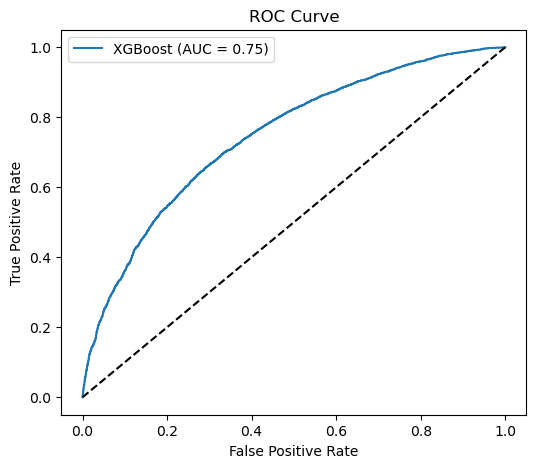

✅ ROC Curve saved!


C:\Users\kiran\AppData\Local\Temp\ipykernel_11180\3144242345.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


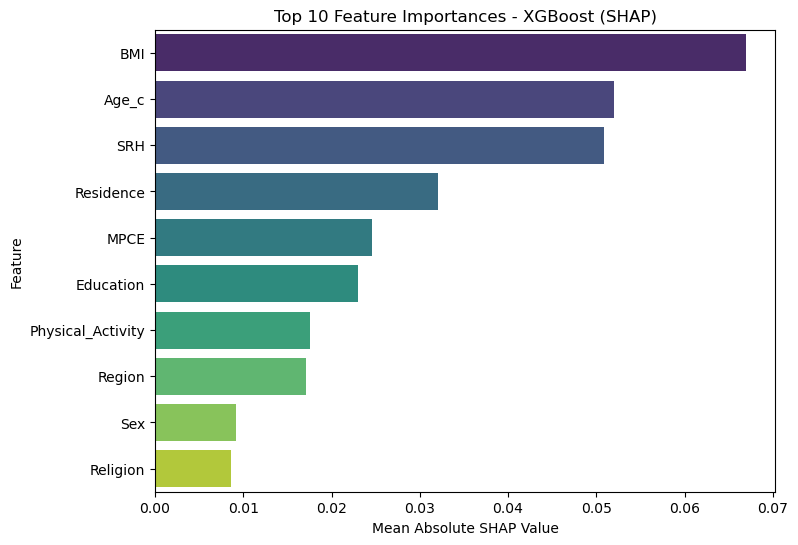

✅ SHAP Importance saved!


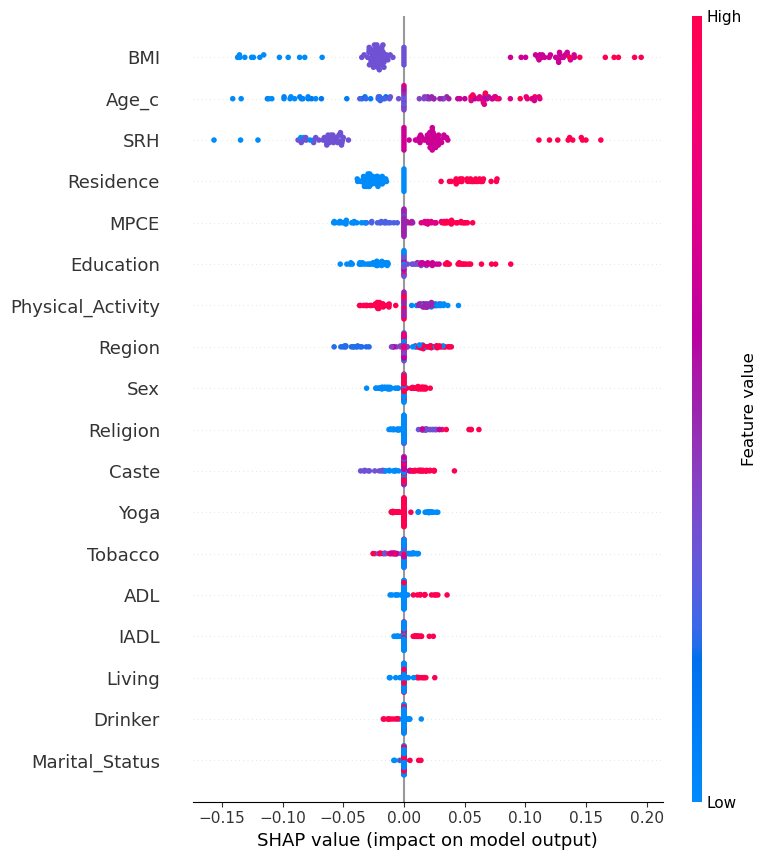

✅ SHAP Summary saved!


In [44]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve

# ── 1. ROC Curve ──
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'XGBoost (AUC = {auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.savefig('xgboost_roc_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ ROC Curve saved!")

# ── 2. Feature Importance Bar Graph ──
plt.figure(figsize=(8, 6))
sns.barplot(
    x='SHAP Importance',
    y='Feature',
    data=shap_importance.head(10),
    palette='viridis'
)
plt.xlabel('Mean Absolute SHAP Value')
plt.ylabel('Feature')
plt.title('Top 10 Feature Importances - XGBoost (SHAP)')
plt.savefig('xgboost_shap_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ SHAP Importance saved!")

# ── 3. SHAP Summary Plot ──
shap.summary_plot(shap_vals, x_test_scaled[:100], 
                  feature_names=x_train.columns,
                  show=False)
plt.savefig('xgboost_shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ SHAP Summary saved!")

⏳ Computing PDP for XGBoost...
  ✅ BMI done
  ✅ Age_c done
  ✅ SRH done
  ✅ Residence done
  ✅ MPCE done
  ✅ Education done
  ✅ Physical_Activity done
  ✅ Caste done
  ✅ Region done
  ✅ Sex done


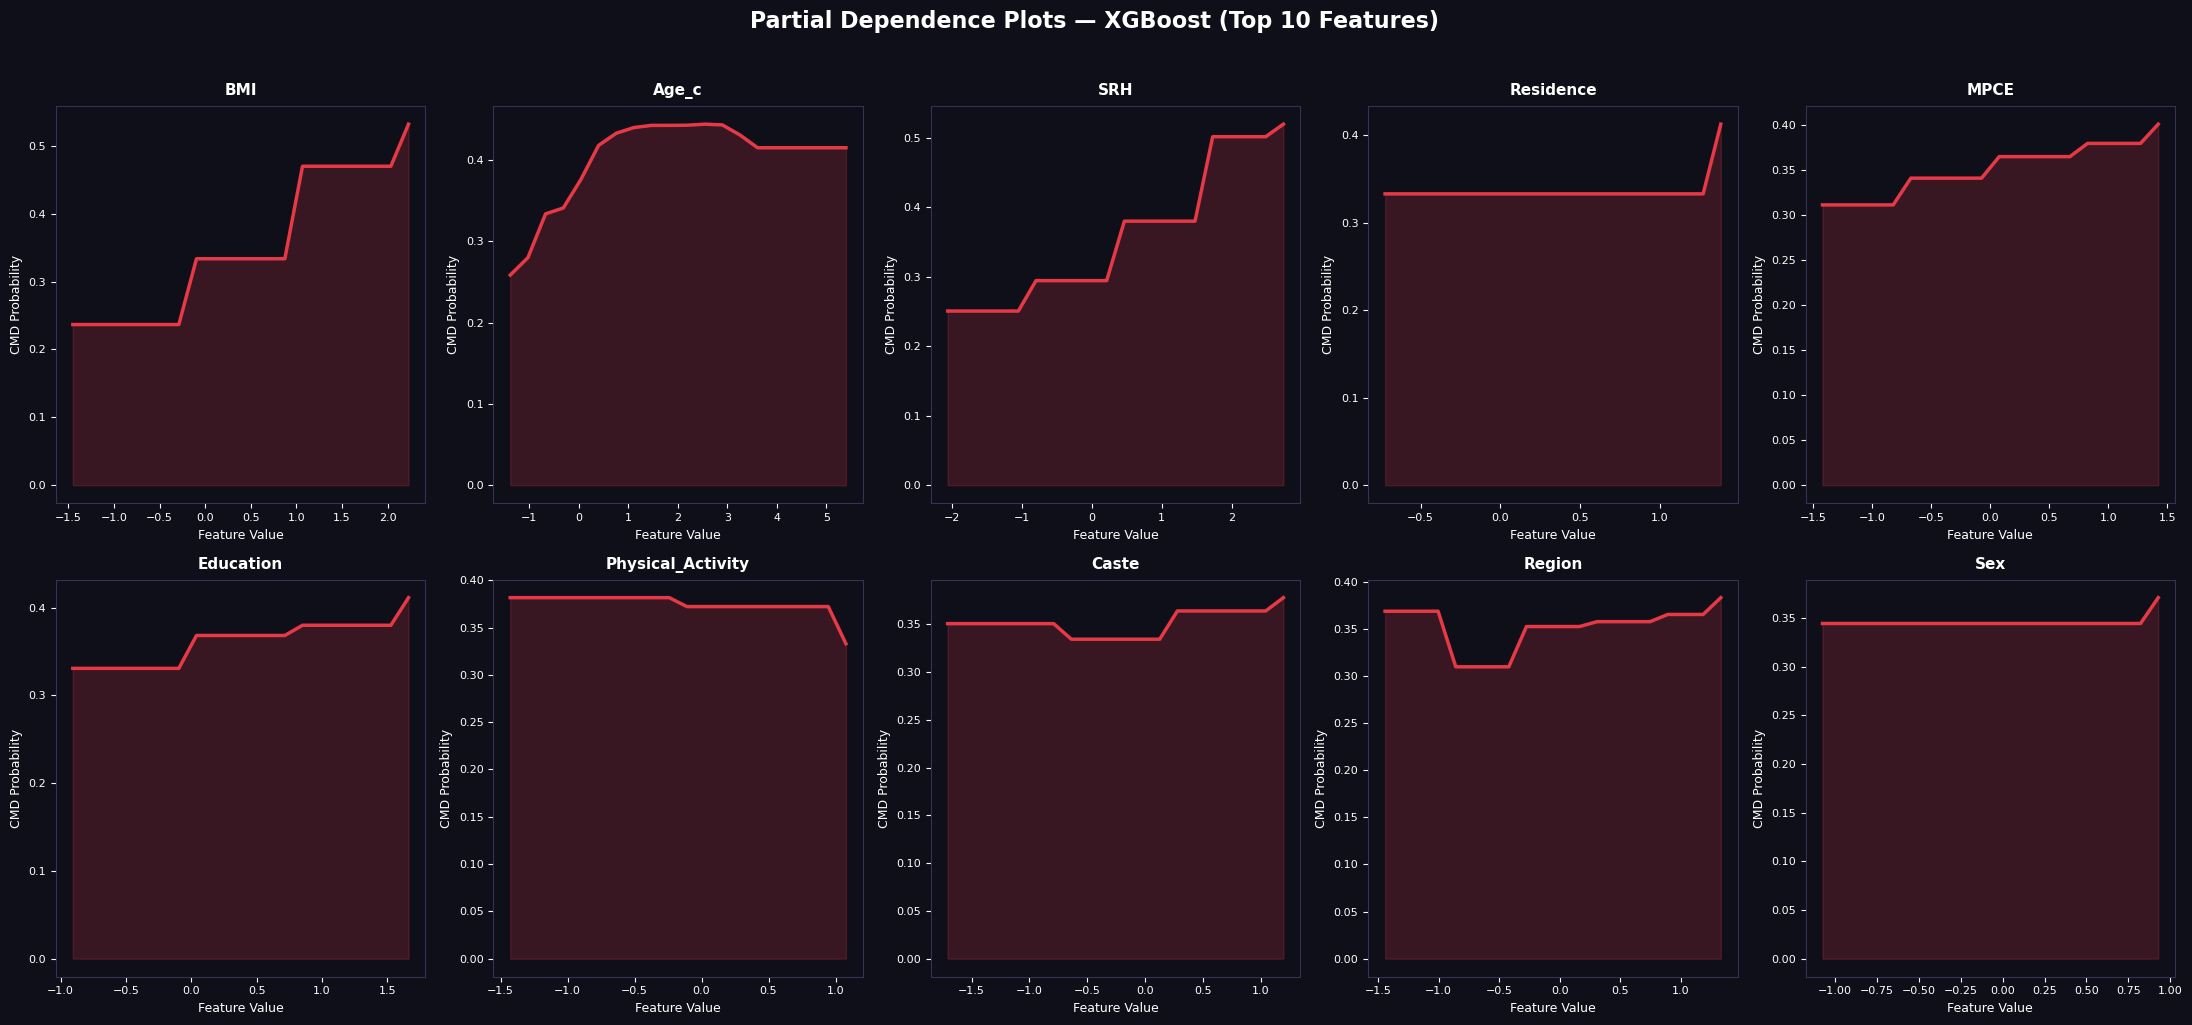

✅ PDP XGBoost saved!


In [45]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

feature_names = x_train.columns.tolist()

top_features = ['BMI', 'Age_c', 'SRH', 'Residence',
                 'MPCE', 'Education', 'Physical_Activity',
                 'Caste', 'Region', 'Sex']

def manual_pdp(model, X, feature_idx, grid_resolution=20):
    X_copy = X.copy()
    feature_vals = np.linspace(
        X[:, feature_idx].min(),
        X[:, feature_idx].max(),
        grid_resolution
    )
    pdp_vals = []
    for val in feature_vals:
        X_temp = X_copy.copy()
        X_temp[:, feature_idx] = val
        preds = model.predict_proba(X_temp)[:, 1]
        pdp_vals.append(preds.mean())
    return feature_vals, np.array(pdp_vals)

# Convert to numpy
X_test_np = np.array(x_test_scaled)

fig, axes = plt.subplots(2, 5, figsize=(22, 10))
fig.patch.set_facecolor('#0f0f1a')
axes = axes.flatten()

print("⏳ Computing PDP for XGBoost...")

for idx, feat_name in enumerate(top_features):
    feat_col_idx = feature_names.index(feat_name)
    
    grid_vals, pdp_vals = manual_pdp(
        model_xgb, X_test_np, feat_col_idx
    )
    
    ax = axes[idx]
    ax.set_facecolor('#0f0f1a')
    ax.plot(grid_vals, pdp_vals, 
            color='#e63946', linewidth=2.5)
    ax.fill_between(grid_vals, pdp_vals, 
                    alpha=0.2, color='#e63946')
    
    ax.set_title(feat_name, fontsize=11,
                 fontweight='bold', color='white', pad=8)
    ax.set_xlabel('Feature Value', fontsize=9, color='white')
    ax.set_ylabel('CMD Probability', fontsize=9, color='white')
    ax.tick_params(colors='white', labelsize=8)
    ax.spines[:].set_color('#333355')
    
    print(f"  ✅ {feat_name} done")

fig.suptitle('Partial Dependence Plots — XGBoost (Top 10 Features)',
             fontsize=16, fontweight='bold', color='white', y=1.02)

plt.tight_layout()
plt.savefig('pdp_xgboost.png', dpi=150,
            bbox_inches='tight', facecolor='#0f0f1a')
plt.show()
print("✅ PDP XGBoost saved!")

In [46]:
import sys
!{sys.executable} -m pip install catboost

Defaulting to user installation because normal site-packages is not writeable


In [24]:
#11. CatBoost

from catboost import CatBoostClassifier
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             confusion_matrix, roc_auc_score, precision_recall_curve,
                             cohen_kappa_score, matthews_corrcoef, balanced_accuracy_score)

# Build and train CatBoost
model_cat = CatBoostClassifier(iterations=100, learning_rate=0.1, depth=3, random_state=42, verbose=0)
model_cat.fit(x_train_scaled, y_train)

# Predictions
y_pred = model_cat.predict(x_test_scaled)
y_prob = model_cat.predict_proba(x_test_scaled)[:, 1]

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
TP = cm[1, 1]
TN = cm[0, 0]
FP = cm[0, 1]
FN = cm[1, 0]

# Metrics calculation
accuracy = accuracy_score(y_test, y_pred)
sensitivity = recall_score(y_test, y_pred)
specificity = TN / (TN + FP)
precision = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
npv = TN / (TN + FN)
balanced_acc = balanced_accuracy_score(y_test, y_pred)
mcc = matthews_corrcoef(y_test, y_pred)
kappa = cohen_kappa_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

# PR-AUC
precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_prob)
pr_auc = np.trapz(recall_curve, precision_curve)

# Display metrics
metrics = {
    "Accuracy": round(accuracy, 4),
    "Sensitivity/Recall": round(sensitivity, 4),
    "Specificity": round(specificity, 4),
    "Precision": round(precision, 4),
    "F1 Score": round(f1, 4),
    "NPV": round(npv, 4),
    "Balanced Accuracy": round(balanced_acc, 4),
    "MCC": round(mcc, 4),
    "Cohen's Kappa": round(kappa, 4),
    "AUC-ROC": round(auc, 4),
    "PR-AUC": round(pr_auc, 4)
}

for k, v in metrics.items():
    print(f"{k}: {v}")

Accuracy: 0.7094
Sensitivity/Recall: 0.417
Specificity: 0.8746
Precision: 0.6525
F1 Score: 0.5088
NPV: 0.7265
Balanced Accuracy: 0.6458
MCC: 0.3324
Cohen's Kappa: 0.3164
AUC-ROC: 0.7435
PR-AUC: 0.2563


C:\Users\kiran\AppData\Local\Temp\ipykernel_7276\1699310696.py:37: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pr_auc = np.trapz(recall_curve, precision_curve)


In [48]:
import shap
import pandas as pd
import numpy as np

# SHAP values for CatBoost
explainer = shap.TreeExplainer(model_cat)
shap_values = explainer.shap_values(x_test_scaled)

# Convert to numpy
shap_vals = np.array(shap_values)

# Fix dimensions
if shap_vals.ndim == 3:
    shap_vals = shap_vals[0]
if shap_vals.shape[0] == x_train.shape[1]:
    shap_vals = shap_vals.T

# Global SHAP importance
shap_importance = pd.DataFrame({
    'Feature': x_train.columns,
    'SHAP Importance': np.abs(shap_vals).mean(axis=0)
}).sort_values(by='SHAP Importance', ascending=False)

print("Top 10 SHAP Feature Importances (CatBoost):")
print(shap_importance.head(10))

Top 10 SHAP Feature Importances (CatBoost):
              Feature  SHAP Importance
9                 BMI         0.341563
6                 SRH         0.310033
1               Age_c         0.258083
0           Residence         0.190453
14               MPCE         0.139024
4           Education         0.115681
13  Physical_Activity         0.105476
17             Region         0.075095
15              Caste         0.063290
16           Religion         0.048794


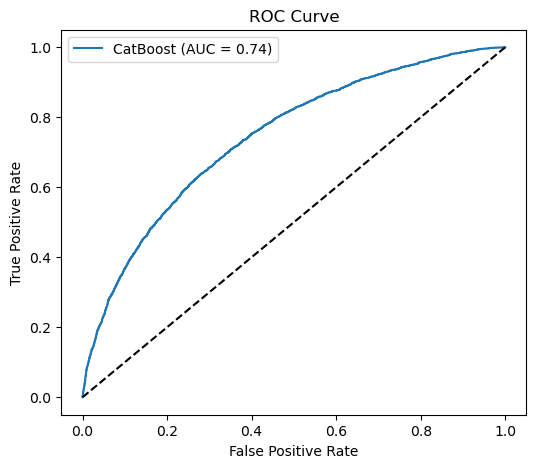

C:\Users\kiran\AppData\Local\Temp\ipykernel_11180\440718127.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


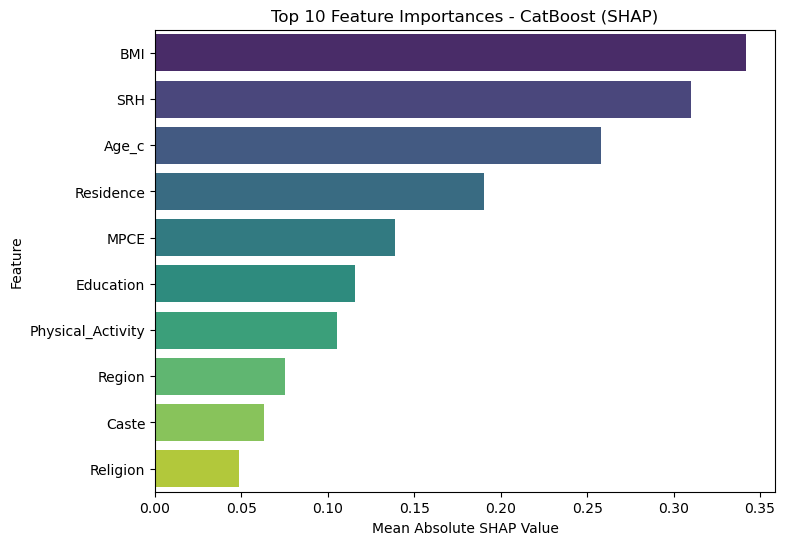

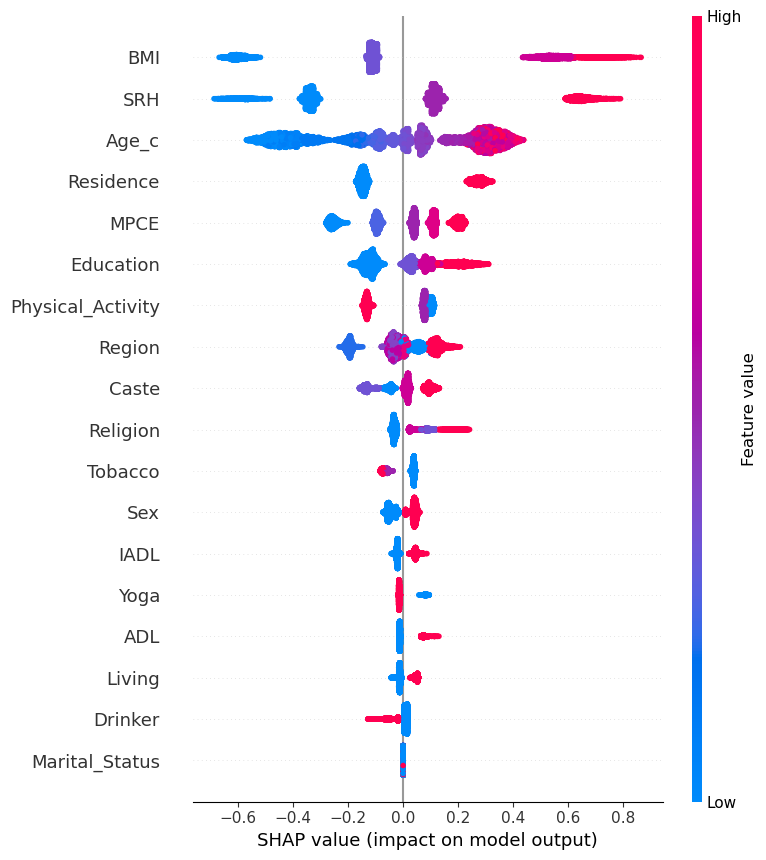

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'CatBoost (AUC = {auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# Feature Importance Bar Graph (Top 10 SHAP)
plt.figure(figsize=(8, 6))
sns.barplot(
    x='SHAP Importance',
    y='Feature',
    data=shap_importance.head(10),
    palette='viridis'
)
plt.xlabel('Mean Absolute SHAP Value')
plt.ylabel('Feature')
plt.title('Top 10 Feature Importances - CatBoost (SHAP)')
plt.show()

# SHAP summary plot (beeswarm)
shap.summary_plot(shap_vals, x_test_scaled, feature_names=x_train.columns)

374/374 ━━━━━━━━━━━━━━━━━━━━ 0s 897us/step


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


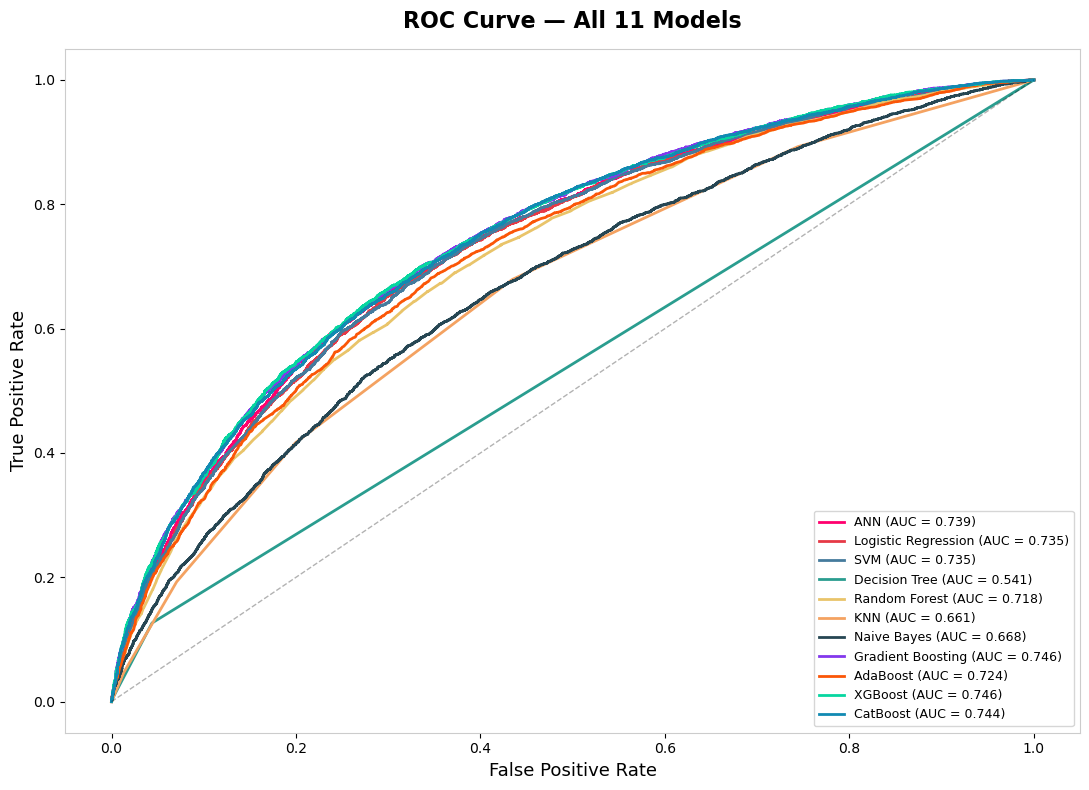

✅ ROC Curve saved as roc_all_models_white.png


In [58]:
# ============================================================
# CELL 1.1: Combined ROC Curve - All 11 Models (White Background)
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from sklearn.metrics import roc_curve, roc_auc_score

models_info = {
    'Logistic Regression': (model_lr,  x_test_scaled),
    'SVM':                 (model_svm, x_test_scaled),
    'Decision Tree':       (model_dt,  x_test_scaled),
    'Random Forest':       (rf_model,  x_test),
    'KNN':                 (model_knn, x_test_scaled),
    'Naive Bayes':         (model_nb,  x_test),
    'Gradient Boosting':   (model_gb,  x_test_scaled),
    'AdaBoost':            (model_ada, x_test_scaled),
    'XGBoost':             (model_xgb, x_test_scaled),
    'CatBoost':            (model_cat, x_test_scaled),
}

colors = ['#e63946','#457b9d','#2a9d8f','#e9c46a','#f4a261',
          '#264653','#8338ec','#fb5607','#06d6a0','#118ab2']

fig, ax = plt.subplots(figsize=(11, 8))

# Set background to white
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

# ANN separately
ann_prob = model_ann.predict(x_test_scaled).flatten()
fpr_ann, tpr_ann, _ = roc_curve(y_test, ann_prob)
auc_ann = roc_auc_score(y_test, ann_prob)
ax.plot(fpr_ann, tpr_ann, label=f'ANN (AUC = {auc_ann:.3f})', color='#ff006e', linewidth=2)

for i, (name, (model, x_data)) in enumerate(models_info.items()):
    y_prob_c = model.predict_proba(x_data)[:, 1]
    fpr_c, tpr_c, _ = roc_curve(y_test, y_prob_c)
    auc_c = roc_auc_score(y_test, y_prob_c)
    ax.plot(fpr_c, tpr_c, label=f'{name} (AUC = {auc_c:.3f})', color=colors[i], linewidth=2)

# Adjust visual elements for white background
ax.plot([0,1],[0,1], 'k--', linewidth=1, alpha=0.3) # 'k--' is a black dashed line
ax.set_xlabel('False Positive Rate', fontsize=13, color='black')
ax.set_ylabel('True Positive Rate', fontsize=13, color='black')
ax.set_title('ROC Curve — All 11 Models', fontsize=16, fontweight='bold', color='black', pad=15)
ax.tick_params(colors='black')

# Spine colors (axes borders)
for spine in ax.spines.values():
    spine.set_color('#cccccc')

# Legend styling
ax.legend(loc='lower right', fontsize=9, facecolor='white', edgecolor='#cccccc', labelcolor='black')

plt.tight_layout()
plt.savefig('roc_all_models_white.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

print("✅ ROC Curve saved as roc_all_models_white.png")

374/374 ━━━━━━━━━━━━━━━━━━━━ 0s 644us/step


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


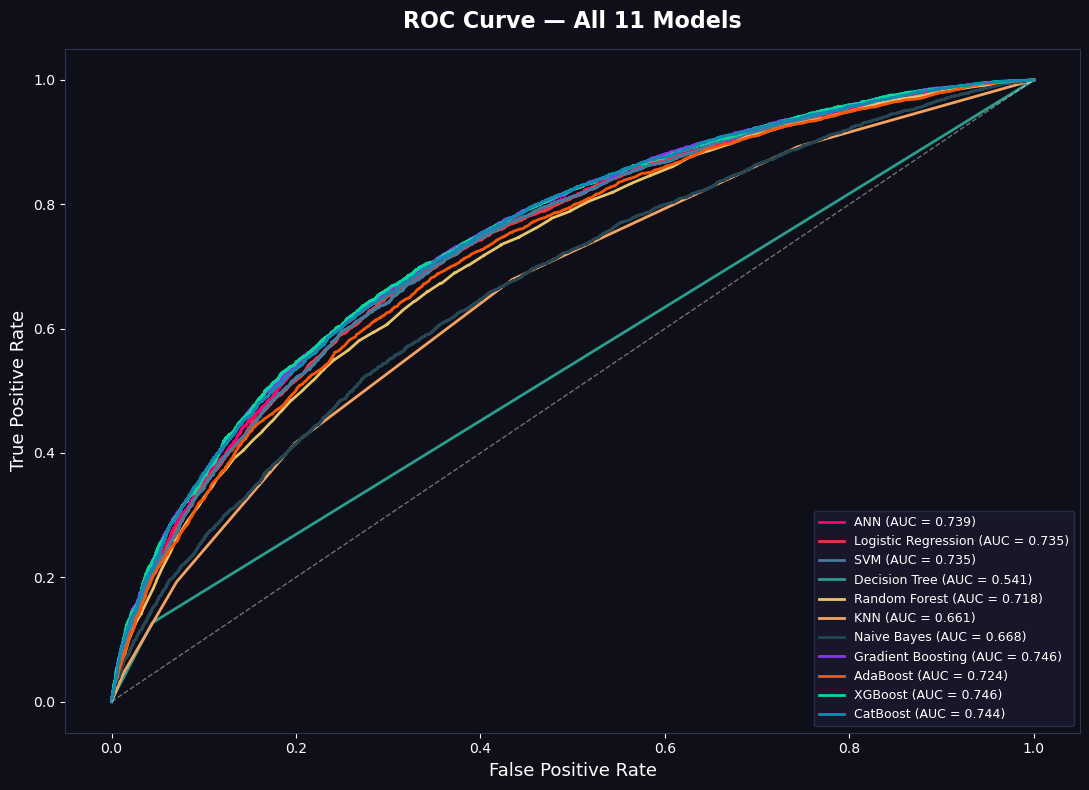

✅ ROC Curve saved as roc_all_models.png


In [50]:
# ============================================================
# CELL 1: Combined ROC Curve - All 11 Models
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from sklearn.metrics import roc_curve, roc_auc_score

models_info = {
    'Logistic Regression': (model_lr,  x_test_scaled),
    'SVM':                 (model_svm, x_test_scaled),
    'Decision Tree':       (model_dt,  x_test_scaled),
    'Random Forest':       (rf_model,  x_test),
    'KNN':                 (model_knn, x_test_scaled),
    'Naive Bayes':         (model_nb,  x_test),
    'Gradient Boosting':   (model_gb,  x_test_scaled),
    'AdaBoost':            (model_ada, x_test_scaled),
    'XGBoost':             (model_xgb, x_test_scaled),
    'CatBoost':            (model_cat, x_test_scaled),
}

colors = ['#e63946','#457b9d','#2a9d8f','#e9c46a','#f4a261',
          '#264653','#8338ec','#fb5607','#06d6a0','#118ab2']

fig, ax = plt.subplots(figsize=(11, 8))
fig.patch.set_facecolor('#0f0f1a')
ax.set_facecolor('#0f0f1a')

# ANN separately
ann_prob = model_ann.predict(x_test_scaled).flatten()
fpr_ann, tpr_ann, _ = roc_curve(y_test, ann_prob)
auc_ann = roc_auc_score(y_test, ann_prob)
ax.plot(fpr_ann, tpr_ann, label=f'ANN (AUC = {auc_ann:.3f})', color='#ff006e', linewidth=2)

for i, (name, (model, x_data)) in enumerate(models_info.items()):
    y_prob_c = model.predict_proba(x_data)[:, 1]
    fpr_c, tpr_c, _ = roc_curve(y_test, y_prob_c)
    auc_c = roc_auc_score(y_test, y_prob_c)
    ax.plot(fpr_c, tpr_c, label=f'{name} (AUC = {auc_c:.3f})', color=colors[i], linewidth=2)

ax.plot([0,1],[0,1], 'w--', linewidth=1, alpha=0.4)
ax.set_xlabel('False Positive Rate', fontsize=13, color='white')
ax.set_ylabel('True Positive Rate', fontsize=13, color='white')
ax.set_title('ROC Curve — All 11 Models', fontsize=16, fontweight='bold', color='white', pad=15)
ax.tick_params(colors='white')
ax.spines[:].set_color('#333355')
ax.legend(loc='lower right', fontsize=9, facecolor='#1a1a2e', edgecolor='#333355', labelcolor='white')
plt.tight_layout()
plt.savefig('roc_all_models.png', dpi=150, bbox_inches='tight', facecolor='#0f0f1a')
plt.show()
print("✅ ROC Curve saved as roc_all_models.png")

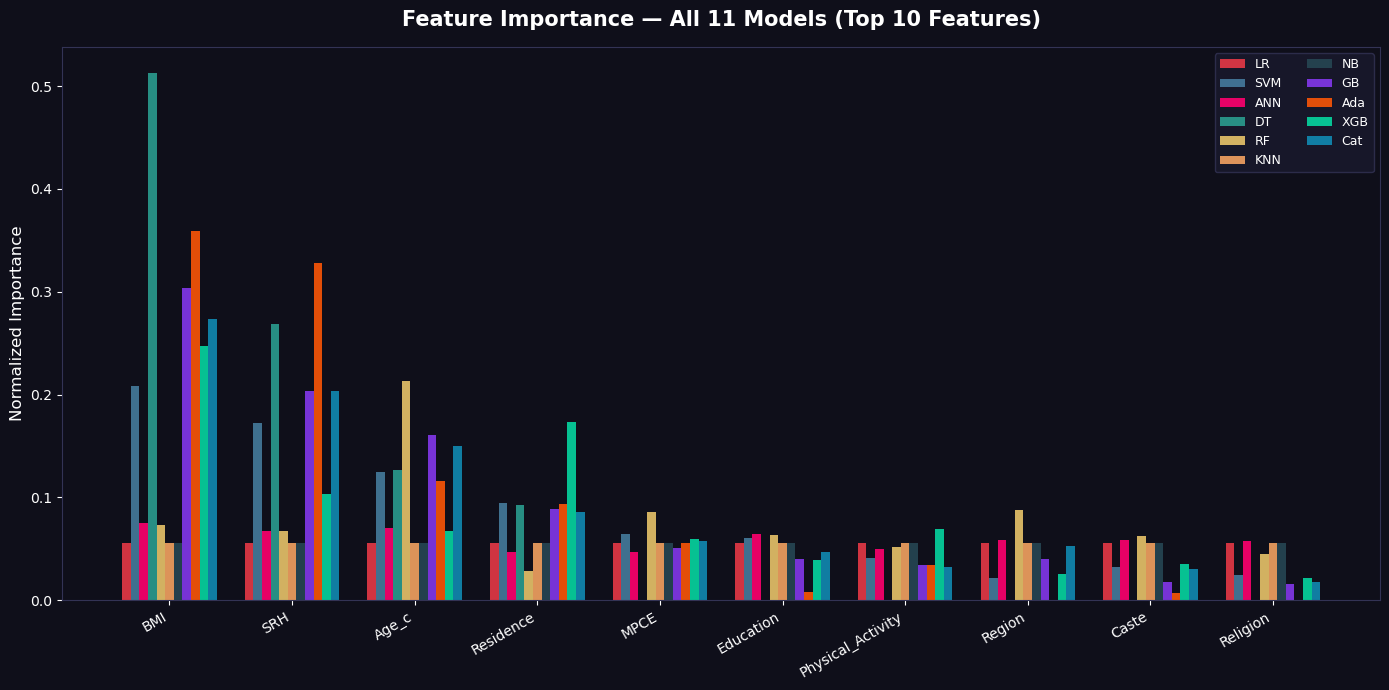

✅ Feature Importance saved as feature_importance_all_models.png


In [51]:
# ============================================================
# CELL 2: Combined Feature Importance - All 11 Models
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def get_feature_importance(model, model_name, feature_names):
    try:
        if model_name == 'ANN':
            weights = np.abs(model.layers[1].get_weights()[0]).mean(axis=1)
            return weights / weights.sum()
        elif model_name == 'SVM':
            if hasattr(model, 'coef_'):
                imp = np.abs(model.coef_[0])
            else:
                imp = np.ones(len(feature_names))
            return imp / imp.sum()
        elif model_name == 'Naive Bayes':
            imp = np.abs(model.feature_log_prob_[1])
            return imp / imp.sum()
        elif model_name == 'KNN':
            return np.ones(len(feature_names)) / len(feature_names)
        else:
            imp = model.feature_importances_
            return imp / imp.sum()
    except:
        return np.ones(len(feature_names)) / len(feature_names)

all_models = {
    'LR':   model_lr,
    'SVM':  model_svm,
    'ANN':  model_ann,
    'DT':   model_dt,
    'RF':   rf_model,
    'KNN':  model_knn,
    'NB':   model_nb,
    'GB':   model_gb,
    'Ada':  model_ada,
    'XGB':  model_xgb,
    'Cat':  model_cat,
}

feature_names = x_train.columns.tolist()
importance_df = pd.DataFrame(index=feature_names)

for name, model in all_models.items():
    importance_df[name] = get_feature_importance(model, name, feature_names)

# Top 10 features by mean importance
importance_df['Mean'] = importance_df.mean(axis=1)
top10 = importance_df.nlargest(10, 'Mean').drop(columns='Mean')

fig, ax = plt.subplots(figsize=(14, 7))
fig.patch.set_facecolor('#0f0f1a')
ax.set_facecolor('#0f0f1a')

x = np.arange(len(top10))
width = 0.07
colors = ['#e63946','#457b9d','#ff006e','#2a9d8f','#e9c46a',
          '#f4a261','#264653','#8338ec','#fb5607','#06d6a0','#118ab2']

for i, (col, color) in enumerate(zip(top10.columns, colors)):
    ax.bar(x + i * width, top10[col], width, label=col, color=color, alpha=0.9)

ax.set_xticks(x + width * 5)
ax.set_xticklabels(top10.index, rotation=30, ha='right', fontsize=10, color='white')
ax.set_ylabel('Normalized Importance', fontsize=12, color='white')
ax.set_title('Feature Importance — All 11 Models (Top 10 Features)', fontsize=15, fontweight='bold', color='white', pad=15)
ax.tick_params(colors='white')
ax.spines[:].set_color('#333355')
ax.legend(loc='upper right', fontsize=9, facecolor='#1a1a2e', edgecolor='#333355', labelcolor='white', ncol=2)
plt.tight_layout()
plt.savefig('feature_importance_all_models.png', dpi=150, bbox_inches='tight', facecolor='#0f0f1a')
plt.show()
print("✅ Feature Importance saved as feature_importance_all_models.png")

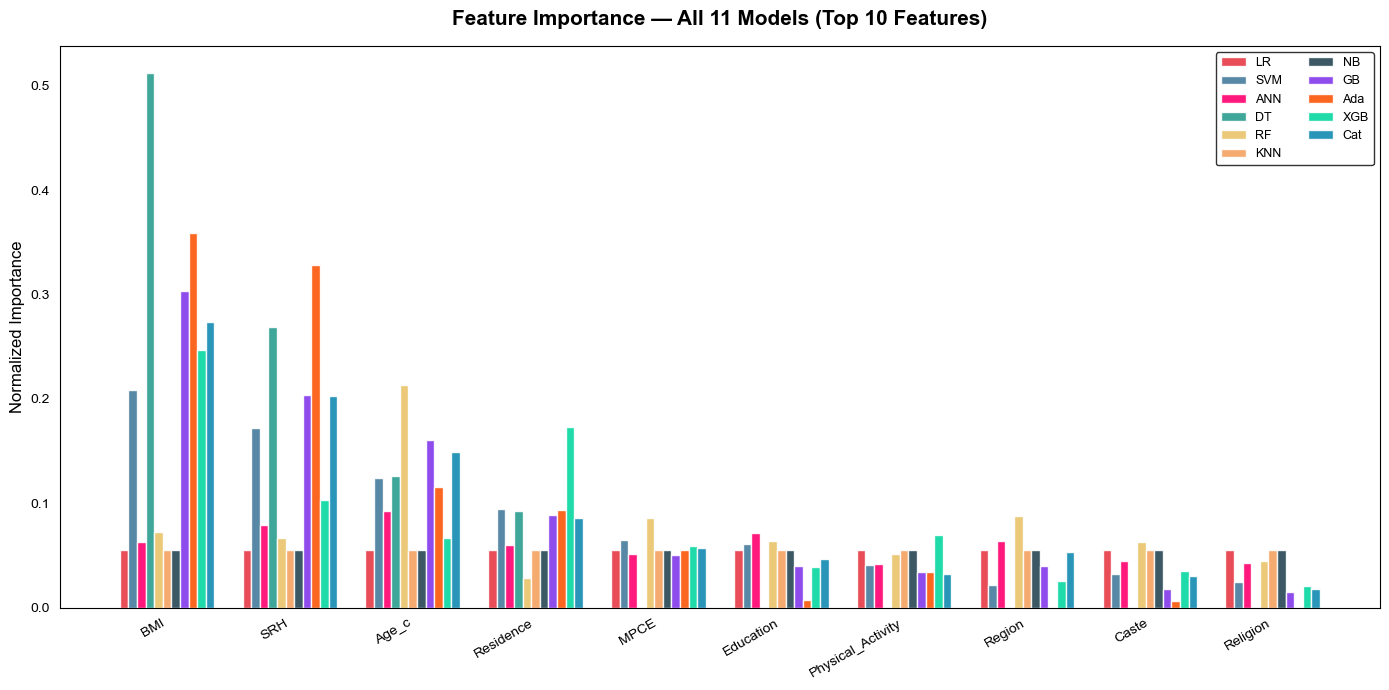

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. FORCE RESET: This clears any previously set dark themes
plt.rcdefaults() 
sns.set_style("white") 

# ... [Your get_feature_importance function and data processing] ...

fig, ax = plt.subplots(figsize=(14, 7), facecolor='white') # Explicitly set figure background
ax.set_facecolor('white') # Explicitly set axes background

x = np.arange(len(top10))
width = 0.07
colors = ['#e63946','#457b9d','#ff006e','#2a9d8f','#e9c46a',
          '#f4a261','#264653','#8338ec','#fb5607','#06d6a0','#118ab2']

for i, (col, color) in enumerate(zip(top10.columns, colors)):
    ax.bar(x + i * width, top10[col], width, label=col, color=color, alpha=0.9)

# 2. FORCE BLACK TEXT: Override any hidden style settings
ax.set_xticks(x + width * 5)
ax.set_xticklabels(top10.index, rotation=30, ha='right', fontsize=10, color='black')

ax.set_ylabel('Normalized Importance', fontsize=12, color='black')
ax.set_title('Feature Importance — All 11 Models (Top 10 Features)', 
             fontsize=15, fontweight='bold', color='black', pad=15)

# 3. FIX TICK COLORS
ax.tick_params(axis='x', colors='black')
ax.tick_params(axis='y', colors='black')

# 4. FIX BORDERS (SPINES)
for spine in ax.spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(0.8)

# 5. LEGEND FIX
ax.legend(loc='upper right', fontsize=9, facecolor='white', 
          edgecolor='black', labelcolor='black', ncol=2)

plt.tight_layout()

# 6. CRITICAL: Save with white facecolor to prevent transparency issues
plt.savefig('feature_importance_white.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

⏳ Computing SHAP values for all models (this may take a few minutes)...
  → LR...


  0%|          | 0/50 [00:00<?, ?it/s]

  → SVM...


  0%|          | 0/50 [00:00<?, ?it/s]

  → ANN...
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step


  0%|          | 0/50 [00:00<?, ?it/s]

... (7 outputs left out)

  0%|          | 0/50 [00:00<?, ?it/s]

  → XGB...


  0%|          | 0/50 [00:00<?, ?it/s]

  → Cat...


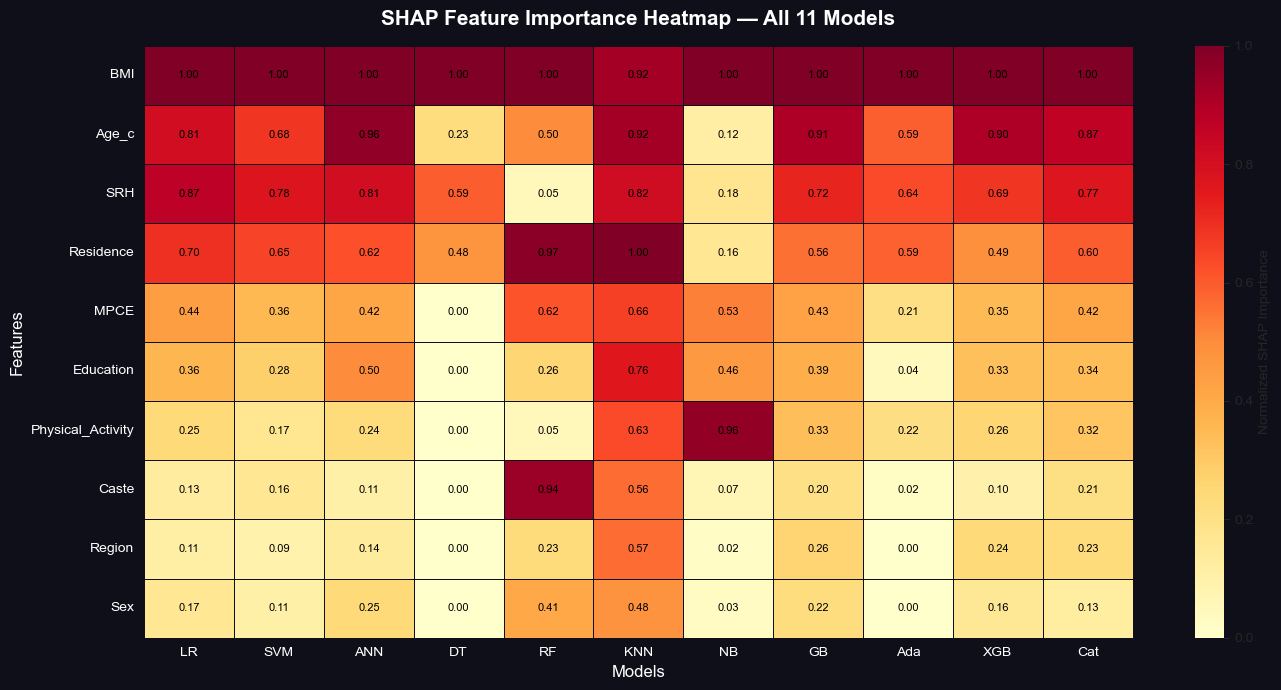

✅ SHAP Heatmap saved as shap_heatmap_all_models.png


In [28]:
# ============================================================
# CELL 3: Combined SHAP Importance Heatmap - All 11 Models
# ============================================================
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def compute_shap_importance(model, model_name, x_train_data, x_test_data, feature_names):
    try:
        if model_name in ['RF', 'DT', 'GB', 'Cat']:
            explainer = shap.TreeExplainer(model)
            sv = explainer.shap_values(x_test_data[:50])
            if isinstance(sv, list):
                sv = sv[1]
        elif model_name == 'ANN':
            explainer = shap.KernelExplainer(lambda x: model.predict(x).flatten(), x_train_data[:50])
            sv = explainer.shap_values(x_test_data[:50], nsamples=50)
        else:
            explainer = shap.KernelExplainer(lambda x: model.predict_proba(x)[:, 1], x_train_data[:50])
            sv = explainer.shap_values(x_test_data[:50], nsamples=50)
        sv = np.array(sv)
        if sv.ndim == 3: sv = sv[0]
        if sv.shape[0] == len(feature_names): sv = sv.T
        return np.abs(sv).mean(axis=0)
    except:
        return np.zeros(len(feature_names))

feature_names = x_train.columns.tolist()

shap_models = {
    'LR':  (model_lr,  x_train_scaled, x_test_scaled),
    'SVM': (model_svm, x_train_scaled, x_test_scaled),
    'ANN': (model_ann, x_train_scaled, x_test_scaled),
    'DT':  (model_dt,  x_train_scaled, x_test_scaled),
    'RF':  (rf_model,  x_train,        x_test),
    'KNN': (model_knn, x_train_scaled, x_test_scaled),
    'NB':  (model_nb,  x_train,        x_test),
    'GB':  (model_gb,  x_train_scaled, x_test_scaled),
    'Ada': (model_ada, x_train_scaled, x_test_scaled),
    'XGB': (model_xgb, x_train_scaled, x_test_scaled),
    'Cat': (model_cat, x_train_scaled, x_test_scaled),
}

print("⏳ Computing SHAP values for all models (this may take a few minutes)...")
shap_matrix = {}
for name, (model, x_tr, x_te) in shap_models.items():
    print(f"  → {name}...")
    shap_matrix[name] = compute_shap_importance(model, name, x_tr, x_te, feature_names)

shap_df = pd.DataFrame(shap_matrix, index=feature_names)
shap_df['Mean'] = shap_df.mean(axis=1)
top10_shap = shap_df.nlargest(10, 'Mean').drop(columns='Mean')

# Normalize
top10_shap_norm = top10_shap.div(top10_shap.max())

fig, ax = plt.subplots(figsize=(14, 7))
fig.patch.set_facecolor('#0f0f1a')
sns.heatmap(
    top10_shap_norm,
    ax=ax,
    cmap='YlOrRd',
    linewidths=0.5,
    linecolor='#0f0f1a',
    annot=True,
    fmt='.2f',
    annot_kws={'size': 8, 'color': 'black'},
    cbar_kws={'label': 'Normalized SHAP Importance'}
)
ax.set_title('SHAP Feature Importance Heatmap — All 11 Models', fontsize=15, fontweight='bold', color='white', pad=15)
ax.set_xlabel('Models', fontsize=12, color='white')
ax.set_ylabel('Features', fontsize=12, color='white')
ax.tick_params(colors='white', labelsize=10)
plt.tight_layout()
plt.savefig('shap_heatmap_all_models.png', dpi=150, bbox_inches='tight', facecolor='#0f0f1a')
plt.show()
print("✅ SHAP Heatmap saved as shap_heatmap_all_models.png")

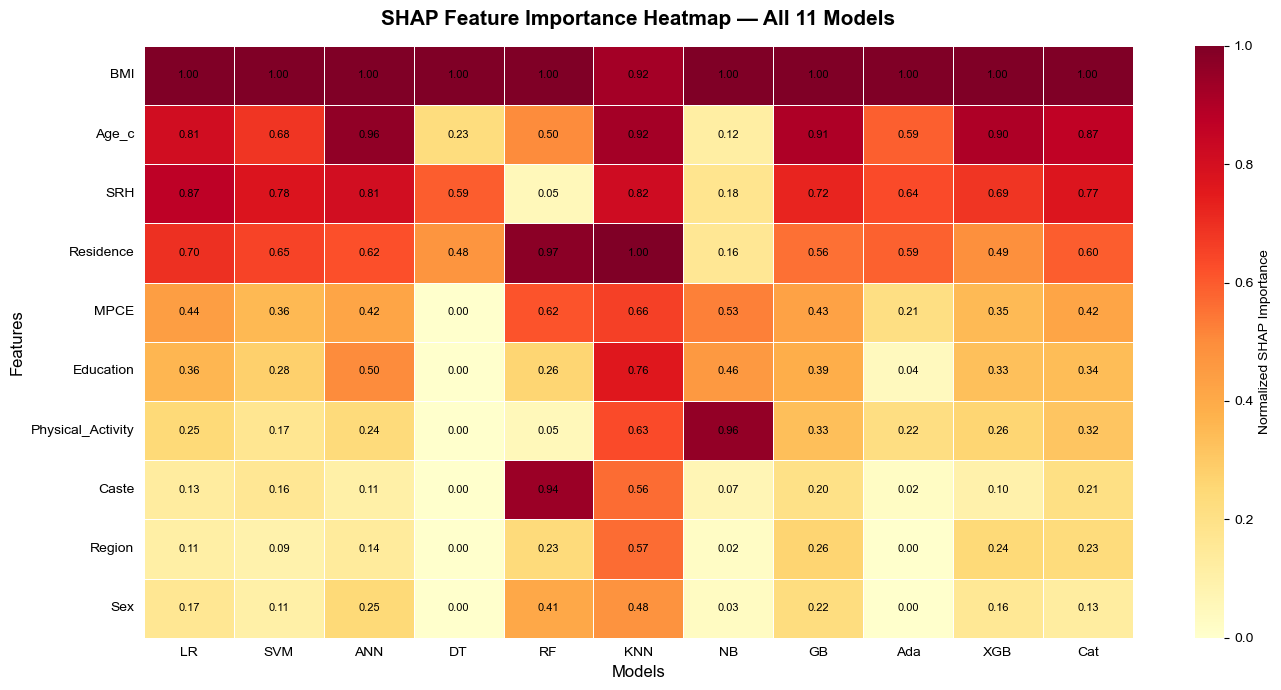

✅ White background SHAP Heatmap saved as shap_heatmap_all_models_white.png


In [29]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Force reset of any dark themes
plt.rcdefaults()
sns.set_style("white")

# ... [Keep your compute_shap_importance function and data processing as is] ...

# Normalize
top10_shap_norm = top10_shap.div(top10_shap.max())

# 1. Initialize figure with white background
fig, ax = plt.subplots(figsize=(14, 7), facecolor='white')
ax.set_facecolor('white')

# 2. Generate Heatmap
sns.heatmap(
    top10_shap_norm,
    ax=ax,
    cmap='YlOrRd',
    linewidths=0.5,
    linecolor='white',  # Changed from dark to white lines between cells
    annot=True,
    fmt='.2f',
    annot_kws={'size': 8, 'color': 'black'},
    cbar_kws={'label': 'Normalized SHAP Importance'}
)

# 3. Update text, labels, and title to black
ax.set_title('SHAP Feature Importance Heatmap — All 11 Models', 
             fontsize=15, fontweight='bold', color='black', pad=15)
ax.set_xlabel('Models', fontsize=12, color='black')
ax.set_ylabel('Features', fontsize=12, color='black')

# 4. Update tick parameters
ax.tick_params(colors='black', labelsize=10)

# 5. Fix Colorbar label color (if necessary)
cbar = ax.collections[0].colorbar
cbar.set_label('Normalized SHAP Importance', color='black')
cbar.ax.yaxis.set_tick_params(color='black', labelcolor='black')

plt.tight_layout()

# 6. Save with explicit white facecolor
plt.savefig('shap_heatmap_all_models_white.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

print("✅ White background SHAP Heatmap saved as shap_heatmap_all_models_white.png")

C:\Users\kiran\AppData\Local\Temp\ipykernel_11180\2848321053.py:24: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pr_auc = np.trapz(recall_curve, precision_curve)


135/374 ━━━━━━━━━━━━━━━━━━━━ 0s 753us/step

C:\Users\kiran\AppData\Local\Temp\ipykernel_11180\2848321053.py:24: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pr_auc = np.trapz(recall_curve, precision_curve)


374/374 ━━━━━━━━━━━━━━━━━━━━ 0s 833us/step


C:\Users\kiran\AppData\Local\Temp\ipykernel_11180\2848321053.py:24: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pr_auc = np.trapz(recall_curve, precision_curve)
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\kiran\AppData\Local\Temp\ipykernel_11180\2848321053.py:24: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pr_auc = np.trapz(recall_curve, precision_curve)
C:\Users\kiran\AppData\Local\Temp\ipykernel_11180\2848321053.py:24: DeprecationWarning: 


📊 Metrics Comparison Table — All 11 Models
                     Accuracy  Sensitivity  Specificity  Precision  F1 Score     NPV  Balanced Acc     MCC  Cohen's Kappa  AUC-ROC  PR-AUC
Logistic Regression    0.7020       0.4147       0.8643     0.6332    0.5012  0.7233        0.6395  0.3154         0.3017   0.7348  0.2422
SVM                    0.7023       0.3808       0.8839     0.6494    0.4801  0.7165        0.6323  0.3112         0.2909   0.7346  0.2422
ANN                    0.7065       0.4570       0.8474     0.6285    0.5292  0.7342        0.6522  0.3323         0.3236   0.7386  0.2501
Decision Tree          0.6399       0.0032       0.9995     0.7778    0.0065  0.6397        0.5014  0.0337         0.0035   0.5413  0.1562
Random Forest          0.6916       0.4358       0.8360     0.6002    0.5050  0.7240        0.6359  0.2969         0.2891   0.7180  0.2198
KNN                    0.6619       0.4163       0.8006     0.5412    0.4706  0.7083        0.6085  0.2327         0.2284 

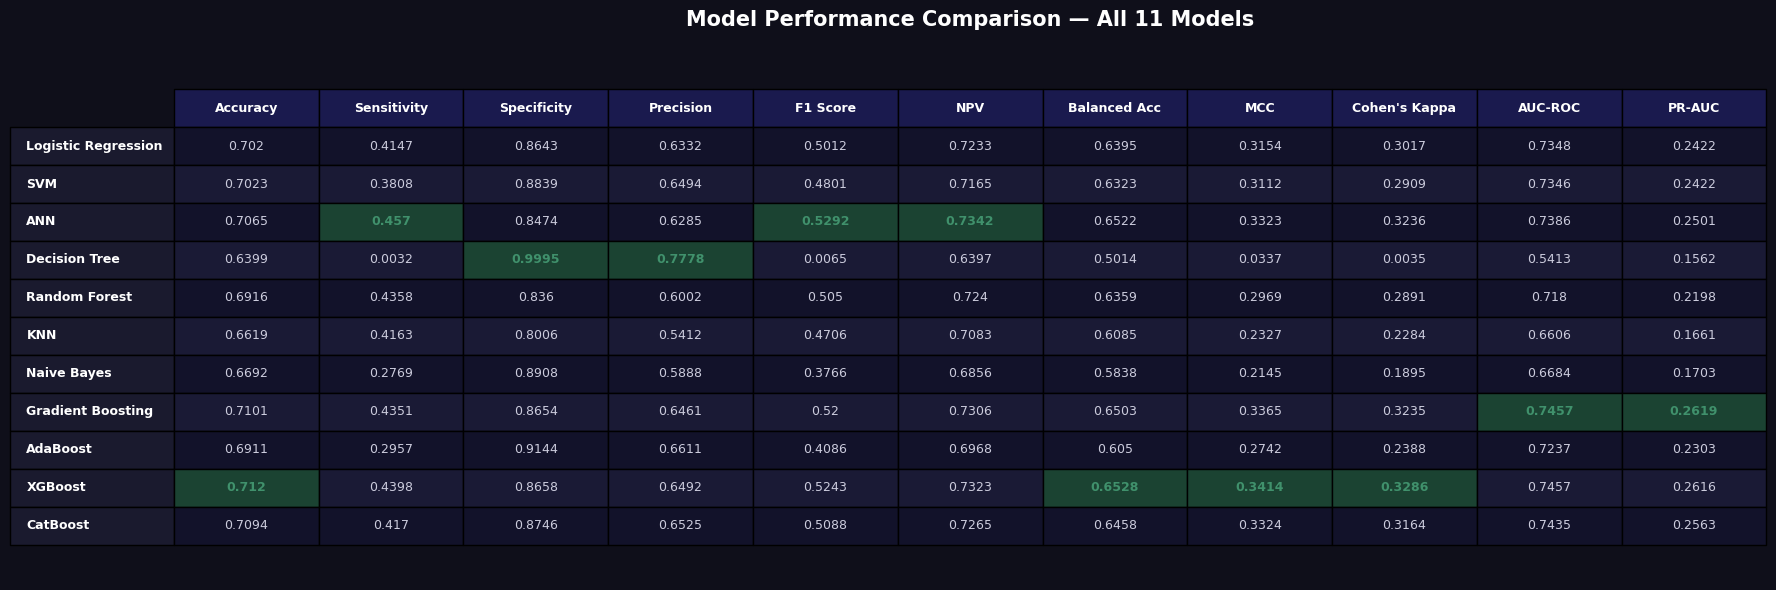

✅ Metrics Table saved as metrics_table_all_models.png


In [53]:
# ============================================================
# CELL 4: Professional Metrics Comparison Table - All 11 Models
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             confusion_matrix, roc_auc_score, precision_recall_curve,
                             cohen_kappa_score, matthews_corrcoef, balanced_accuracy_score)

def compute_metrics(model, model_name, x_data, y_true):
    if model_name == 'ANN':
        y_prob = model.predict(x_data).flatten()
        y_pred = (y_prob >= 0.5).astype(int)
    else:
        y_prob = model.predict_proba(x_data)[:, 1]
        y_pred = model.predict(x_data)

    cm = confusion_matrix(y_true, y_pred)
    TP, TN = cm[1,1], cm[0,0]
    FP, FN = cm[0,1], cm[1,0]

    precision_curve, recall_curve, _ = precision_recall_curve(y_true, y_prob)
    pr_auc = np.trapz(recall_curve, precision_curve)

    return {
        'Accuracy':          round(accuracy_score(y_true, y_pred), 4),
        'Sensitivity':       round(recall_score(y_true, y_pred), 4),
        'Specificity':       round(TN / (TN + FP), 4),
        'Precision':         round(precision_score(y_true, y_pred), 4),
        'F1 Score':          round(f1_score(y_true, y_pred), 4),
        'NPV':               round(TN / (TN + FN), 4),
        'Balanced Acc':      round(balanced_accuracy_score(y_true, y_pred), 4),
        'MCC':               round(matthews_corrcoef(y_true, y_pred), 4),
        "Cohen's Kappa":     round(cohen_kappa_score(y_true, y_pred), 4),
        'AUC-ROC':           round(roc_auc_score(y_true, y_prob), 4),
        'PR-AUC':            round(pr_auc, 4),
    }

eval_models = {
    'Logistic Regression': (model_lr,  x_test_scaled),
    'SVM':                 (model_svm, x_test_scaled),
    'ANN':                 (model_ann, x_test_scaled),
    'Decision Tree':       (model_dt,  x_test_scaled),
    'Random Forest':       (rf_model,  x_test),
    'KNN':                 (model_knn, x_test_scaled),
    'Naive Bayes':         (model_nb,  x_test),
    'Gradient Boosting':   (model_gb,  x_test_scaled),
    'AdaBoost':            (model_ada, x_test_scaled),
    'XGBoost':             (model_xgb, x_test_scaled),
    'CatBoost':            (model_cat, x_test_scaled),
}

results = {}
for name, (model, x_data) in eval_models.items():
    results[name] = compute_metrics(model, name, x_data, y_test)

results_df = pd.DataFrame(results).T
print("\n📊 Metrics Comparison Table — All 11 Models")
print("=" * 120)
print(results_df.to_string())
print("=" * 120)

# Best model per metric
print("\n🏆 Best Model per Metric:")
for col in results_df.columns:
    best = results_df[col].idxmax()
    print(f"  {col:20s} → {best:25s} ({results_df[col].max():.4f})")

# ── Professional styled plot ──
fig, ax = plt.subplots(figsize=(18, 6))
fig.patch.set_facecolor('#0f0f1a')
ax.set_facecolor('#0f0f1a')
ax.axis('off')

table = ax.table(
    cellText=results_df.round(4).values,
    rowLabels=results_df.index,
    colLabels=results_df.columns,
    cellLoc='center',
    loc='center'
)
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1.2, 2)

# Style header
for j in range(len(results_df.columns)):
    table[0, j].set_facecolor('#1a1a4e')
    table[0, j].set_text_props(color='white', fontweight='bold')

# Style row labels
for i in range(len(results_df)):
    table[i+1, -1].set_facecolor('#1a1a2e')
    table[i+1, -1].set_text_props(color='white', fontweight='bold')

# Highlight best value in each column green
for j, col in enumerate(results_df.columns):
    best_idx = results_df[col].idxmax()
    best_row = results_df.index.tolist().index(best_idx)
    table[best_row+1, j].set_facecolor('#1b4332')
    table[best_row+1, j].set_text_props(color='#40916c', fontweight='bold')

# Alternate row colors
for i in range(len(results_df)):
    for j in range(len(results_df.columns)):
        if table[i+1, j].get_facecolor() == (1,1,1,1):
            color = '#12122a' if i % 2 == 0 else '#1a1a35'
            table[i+1, j].set_facecolor(color)
            table[i+1, j].set_text_props(color='#ccccdd')

ax.set_title('Model Performance Comparison — All 11 Models',
             fontsize=15, fontweight='bold', color='white', pad=20)

plt.tight_layout()
plt.savefig('metrics_table_all_models.png', dpi=150, bbox_inches='tight', facecolor='#0f0f1a')
plt.show()
print("✅ Metrics Table saved as metrics_table_all_models.png")

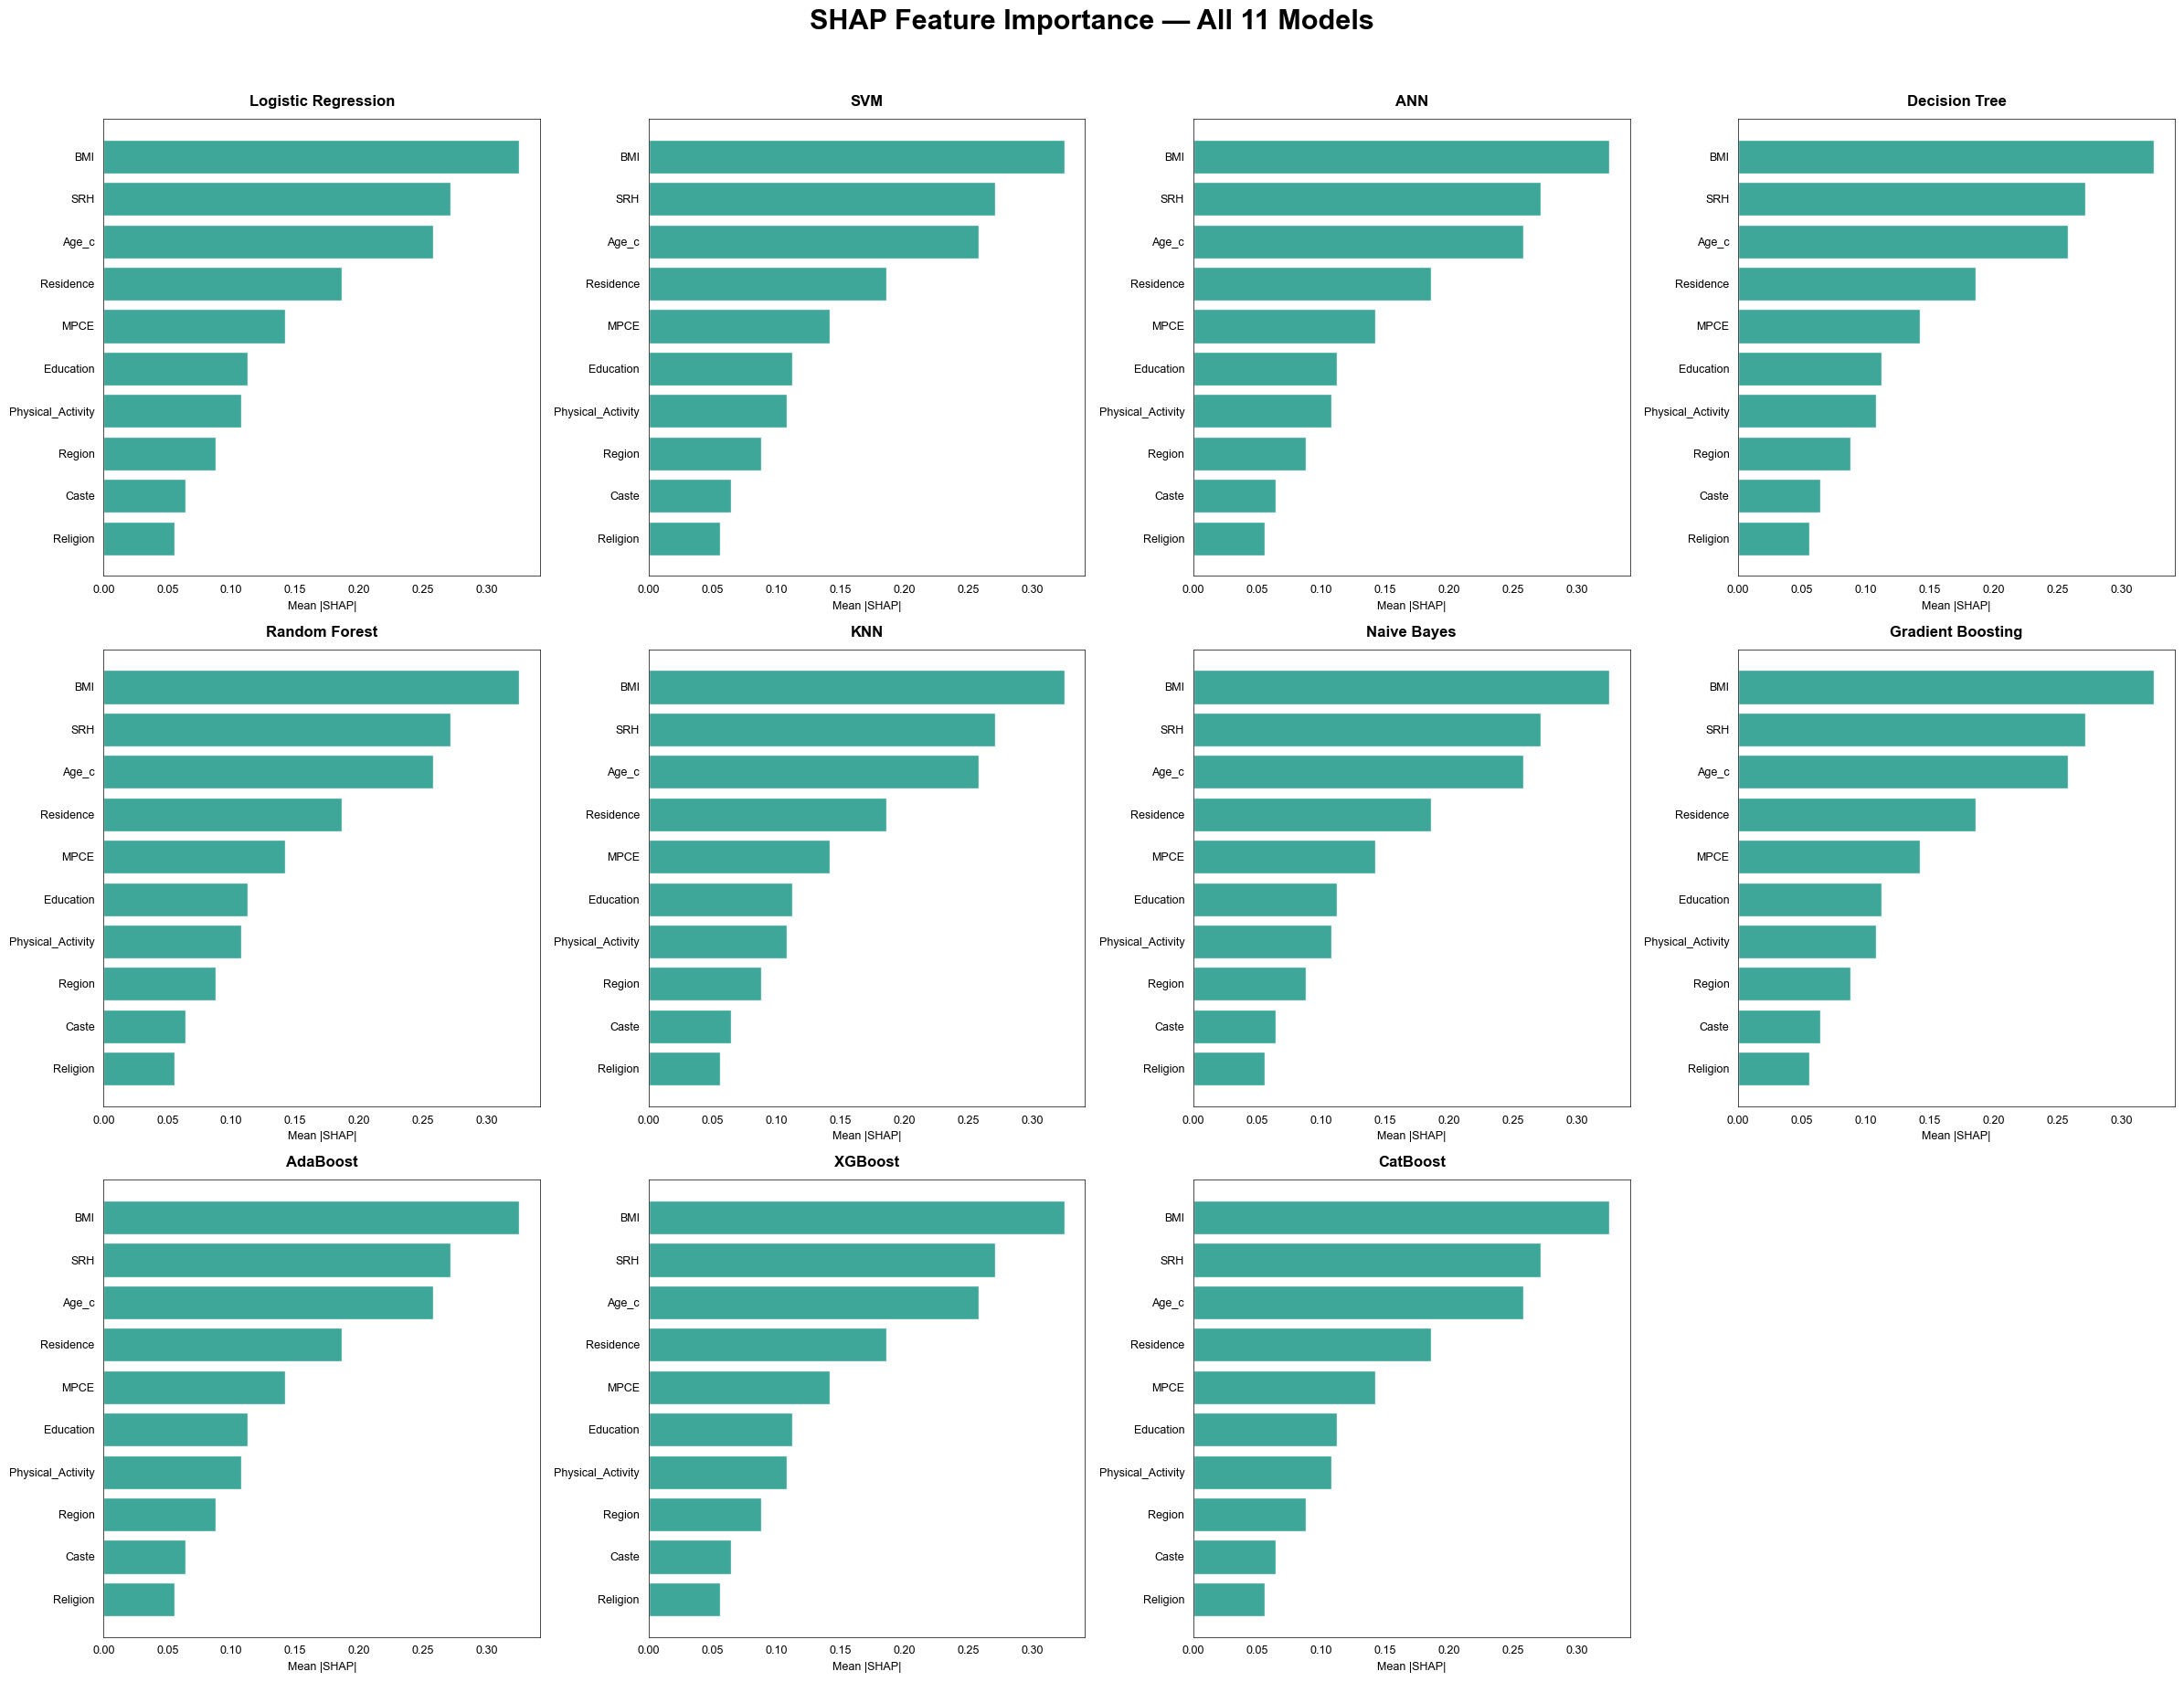

In [38]:
import shap
import matplotlib.pyplot as plt
import matplotlib
import numpy as np
import seaborn as sns

# 1. THE "KILL SWITCH" FOR DARK MODE
plt.close('all')           # Close any existing dark windows
matplotlib.rc_file_defaults() # Reset rcParams to original defaults
matplotlib.style.use('default') # Force the standard white style
sns.set_style("white")     # Ensure seaborn doesn't inject a grey grid

# 2. Setup your data
# [Keep your models_shap and feature_names definitions here]

# 3. Explicitly define white in the figure initialization
fig, axes = plt.subplots(3, 4, figsize=(24, 18), facecolor='white', edgecolor='white')
axes = axes.flatten()
axes[-1].set_visible(False)

bar_color = '#2a9d8f' # Professional Teal

for idx, (name, (model, mtype, x_tr, x_te)) in enumerate(models_shap.items()):
    try:
        # ... [Your SHAP computation logic remains exactly the same] ...
        
        ax = axes[idx]
        ax.set_facecolor('white') # Force subplot area to white
        
        # Plotting
        ax.barh(
            [feature_names[i] for i in sorted_idx],
            mean_shap[sorted_idx],
            color=bar_color,
            alpha=0.9
        )
        
        # 4. FORCE BLACK TEXT (Override any dark mode defaults)
        ax.set_title(name, fontsize=12, fontweight='bold', color='black', pad=10)
        ax.set_xlabel('Mean |SHAP|', fontsize=9, color='black')
        ax.tick_params(axis='both', colors='black', labelsize=9)
        
        # Make the box lines (spines) visible and black/grey
        for spine in ax.spines.values():
            spine.set_edgecolor('black')
            spine.set_linewidth(0.5)
            spine.set_visible(True)

    except Exception as e:
        axes[idx].set_visible(False)

# 5. Global Title in Black
fig.suptitle('SHAP Feature Importance — All 11 Models',
             fontsize=22, fontweight='bold', color='black', y=1.02)

plt.tight_layout()

# 6. CRITICAL: Save with white background explicitly
# If you don't set facecolor here, it might save as transparent (which looks black in some viewers)
plt.savefig('shap_final_white.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

Computing SHAP for Logistic Regression...


  0%|          | 0/100 [00:00<?, ?it/s]

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_least_angle.py:723: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 8 iterations, i.e. alpha=1.626e-04, with an active set of 8 regressors, and the smallest cholesky pivot element being 2.980e-08. Reduce max_iter or increase eps parameters.
  warnings.warn(


Computing SHAP for SVM...


  0%|          | 0/100 [00:00<?, ?it/s]

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_least_angle.py:723: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 5 iterations, i.e. alpha=7.734e-04, with an active set of 5 regressors, and the smallest cholesky pivot element being 2.980e-08. Reduce max_iter or increase eps parameters.
  warnings.warn(


... (7 outputs left out)

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but MultinomialNB was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but MultinomialNB was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but MultinomialNB was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but MultinomialNB was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but MultinomialNB was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packag

Computing SHAP for Gradient Boosting...
Computing SHAP for AdaBoost...


  0%|          | 0/100 [00:00<?, ?it/s]

Computing SHAP for XGBoost...
Computing SHAP for CatBoost...


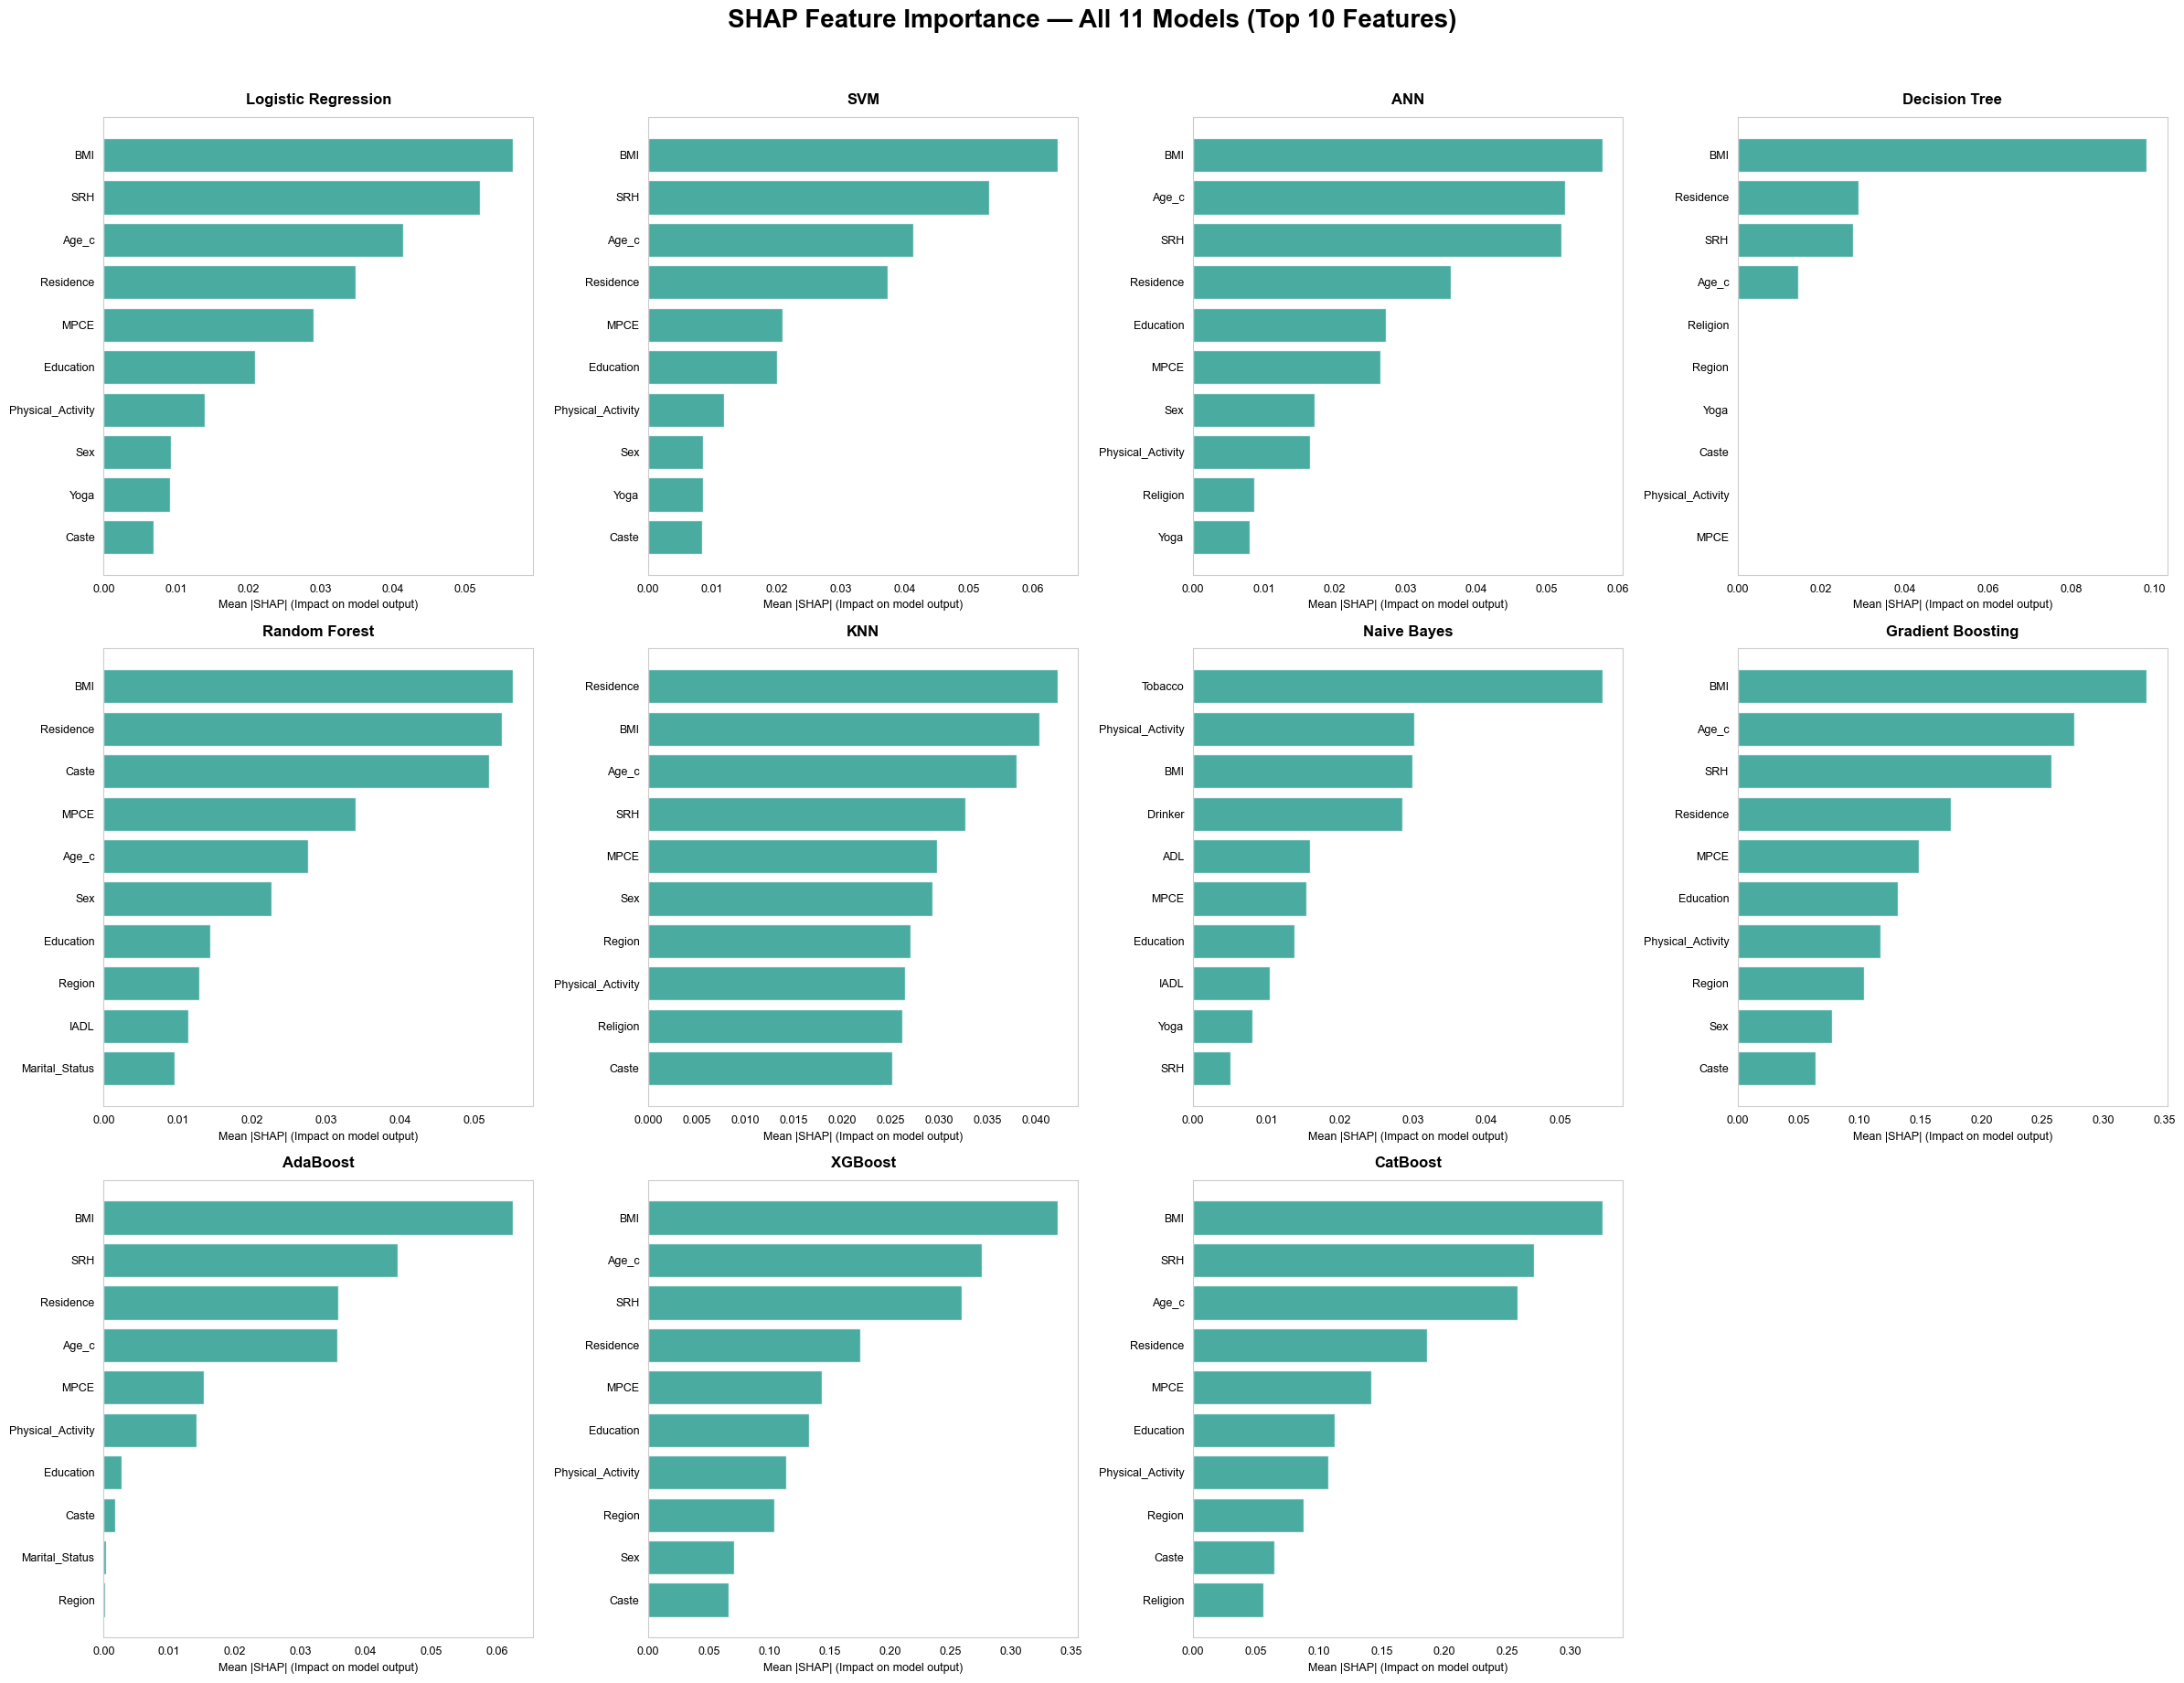

✅ Combined SHAP plot with white background saved!


In [40]:
import shap

import matplotlib.pyplot as plt

import numpy as np



models_shap = {

    'Logistic Regression': (model_lr,  'kernel', x_train_scaled, x_test_scaled),

    'SVM':                 (model_svm, 'kernel', x_train_scaled, x_test_scaled),

    'ANN':                 (model_ann, 'ann',    x_train_scaled, x_test_scaled),

    'Decision Tree':       (model_dt,  'tree',   x_train,        x_test),

    'Random Forest':       (rf_model,  'tree',   x_train,        x_test),

    'KNN':                 (model_knn, 'kernel', x_train_scaled, x_test_scaled),

    'Naive Bayes':         (model_nb,  'kernel', x_train,        x_test),

    'Gradient Boosting':   (model_gb,  'tree',   x_train_scaled, x_test_scaled),

    'AdaBoost':            (model_ada, 'kernel', x_train_scaled, x_test_scaled),

    'XGBoost':             (model_xgb, 'tree',   x_train_scaled, x_test_scaled),

    'CatBoost':            (model_cat, 'tree',   x_train_scaled, x_test_scaled),

}



feature_names = x_train.columns.tolist()



fig, axes = plt.subplots(3, 4, figsize=(24, 18))

fig.patch.set_facecolor('#0f0f1a')

axes = axes.flatten()



# Hide last empty subplot

axes[-1].set_visible(False)



for idx, (name, (model, mtype, x_tr, x_te)) in enumerate(models_shap.items()):

    print(f"Computing SHAP for {name}...")

    try:

        if mtype == 'tree':

            explainer = shap.TreeExplainer(model)

            sv = explainer.shap_values(x_te[:100])

            if isinstance(sv, list):

                sv = sv[1]

        elif mtype == 'ann':

            explainer = shap.KernelExplainer(

                lambda x: model.predict(x).flatten(), x_tr[:50])

            sv = explainer.shap_values(x_te[:100], nsamples=50)

        else:

            explainer = shap.KernelExplainer(

                lambda x: model.predict_proba(x)[:, 1], x_tr[:50])

            sv = explainer.shap_values(x_te[:100], nsamples=50)



        sv = np.array(sv)

        if sv.ndim == 3:

            sv = sv[0]

        if sv.shape[0] == len(feature_names):

            sv = sv.T



        # Mean absolute SHAP per feature

        mean_shap = np.abs(sv).mean(axis=0)

        sorted_idx = np.argsort(mean_shap)[-10:]

       

        ax = axes[idx]

        ax.set_facecolor('#0f0f1a')

        ax.barh(

            [feature_names[i] for i in sorted_idx],

            mean_shap[sorted_idx],

            color='#e63946',

            alpha=0.85

        )

        ax.set_title(name, fontsize=11, fontweight='bold',

                     color='white', pad=8)

        ax.tick_params(colors='white', labelsize=8)

        ax.spines[:].set_color('#333355')

        ax.set_xlabel('Mean |SHAP|', fontsize=8, color='white')



    except Exception as e:

        print(f"  ⚠️ Failed for {name}: {e}")

        axes[idx].set_visible(False)



fig.suptitle('SHAP Feature Importance — All 11 Models',

             fontsize=18, fontweight='bold', color='white', y=1.01)

plt.tight_layout()

plt.savefig('shap_combined_all_models.png', dpi=150,

            bbox_inches='tight', facecolor='#0f0f1a')

plt.show()

print("✅ Combined SHAP plot saved!")

In [59]:
# 5.1============================================================
# Individual SHAP Plots for All 11 Models (White Background)
# ============================================================
import shap
import matplotlib.pyplot as plt
import numpy as np
import os

# Create a folder to keep things organized
if not os.path.exists('shap_plots'):
    os.makedirs('shap_plots')

models_shap = {
    'Logistic Regression': (model_lr,  'kernel', x_train_scaled, x_test_scaled),
    'SVM':                 (model_svm, 'kernel', x_train_scaled, x_test_scaled),
    'ANN':                 (model_ann, 'ann',    x_train_scaled, x_test_scaled),
    'Decision Tree':       (model_dt,  'tree',   x_train,         x_test),
    'Random Forest':       (rf_model,  'tree',   x_train,         x_test),
    'KNN':                 (model_knn, 'kernel', x_train_scaled, x_test_scaled),
    'Naive Bayes':         (model_nb,  'kernel', x_train,         x_test),
    'Gradient Boosting':   (model_gb,  'tree',   x_train_scaled, x_test_scaled),
    'AdaBoost':            (model_ada, 'kernel', x_train_scaled, x_test_scaled),
    'XGBoost':             (model_xgb, 'tree',   x_train_scaled, x_test_scaled),
    'CatBoost':            (model_cat, 'tree',   x_train_scaled, x_test_scaled),
}

feature_names = x_train.columns.tolist()

for name, (model, mtype, x_tr, x_te) in models_shap.items():
    print(f"Computing SHAP for {name}...")
    try:
        # --- SHAP Calculation Logic ---
        if mtype == 'tree':
            explainer = shap.TreeExplainer(model)
            sv = explainer.shap_values(x_te[:100])
            if isinstance(sv, list):
                sv = sv[1]
        elif mtype == 'ann':
            explainer = shap.KernelExplainer(lambda x: model.predict(x).flatten(), x_tr[:50])
            sv = explainer.shap_values(x_te[:100], nsamples=50)
        else:
            explainer = shap.KernelExplainer(lambda x: model.predict_proba(x)[:, 1], x_tr[:50])
            sv = explainer.shap_values(x_te[:100], nsamples=50)

        sv = np.array(sv)
        if sv.ndim == 3: sv = sv[0]
        if sv.shape[0] == len(feature_names): sv = sv.T

        # --- Individual Plotting Logic ---
        mean_shap = np.abs(sv).mean(axis=0)
        sorted_idx = np.argsort(mean_shap)[-10:] # Top 10 features
        
        fig, ax = plt.subplots(figsize=(8, 6))
        fig.patch.set_facecolor('white')
        ax.set_facecolor('white')

        ax.barh(
            [feature_names[i] for i in sorted_idx],
            mean_shap[sorted_idx],
            color='#e63946',
            alpha=0.85
        )
        
        # Labels and Title (Black for white background)
        ax.set_title(f'SHAP Importance: {name}', fontsize=14, fontweight='bold', color='black', pad=15)
        ax.tick_params(colors='black', labelsize=10)
        ax.set_xlabel('Mean |SHAP Value| (Impact on Model Output)', fontsize=10, color='black')
        
        # Clean up spines
        for spine in ax.spines.values():
            spine.set_color('#cccccc')

        plt.tight_layout()
        
        # Save each model with its own name
        clean_name = name.lower().replace(" ", "_")
        plt.savefig(f'shap_plots/shap_{clean_name}.png', dpi=150, bbox_inches='tight', facecolor='white')
        plt.close() # Close to free up memory
        
        print(f"  ✅ Saved: shap_plots/shap_{clean_name}.png")

    except Exception as e:
        print(f"  ⚠️ Failed for {name}: {e}")

print("\nAll individual SHAP plots are ready in the 'shap_plots' folder!")

Computing SHAP for Logistic Regression...


  0%|          | 0/100 [00:00<?, ?it/s]

  ✅ Saved: shap_plots/shap_logistic_regression.png
Computing SHAP for SVM...


  0%|          | 0/100 [00:00<?, ?it/s]

  ✅ Saved: shap_plots/shap_svm.png
Computing SHAP for ANN...
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


  0%|          | 0/100 [00:00<?, ?it/s]

... (6 outputs left out)

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but MultinomialNB was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but MultinomialNB was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but MultinomialNB was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but MultinomialNB was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but MultinomialNB was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packag

  ✅ Saved: shap_plots/shap_naive_bayes.png
Computing SHAP for Gradient Boosting...
  ✅ Saved: shap_plots/shap_gradient_boosting.png
Computing SHAP for AdaBoost...


  0%|          | 0/100 [00:00<?, ?it/s]

  ✅ Saved: shap_plots/shap_adaboost.png
Computing SHAP for XGBoost...
  ✅ Saved: shap_plots/shap_xgboost.png
Computing SHAP for CatBoost...
  ✅ Saved: shap_plots/shap_catboost.png

All individual SHAP plots are ready in the 'shap_plots' folder!


⏳ Computing combined PDP for all 11 models...


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


  ⚠️ ANN - BMI: This ANNWrapper instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.
  ✅ BMI done


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.w

  ⚠️ ANN - Age_c: This ANNWrapper instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.
  ✅ Age_c done


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.w

... (11 outputs left out)

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.w

  ⚠️ ANN - Region: This ANNWrapper instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.
  ✅ Region done
  ⚠️ Logistic Regression - Sex: cannot reshape array of size 1 into shape (2)
  ⚠️ SVM - Sex: cannot reshape array of size 1 into shape (2)
  ⚠️ Decision Tree - Sex: cannot reshape array of size 1 into shape (2)


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


  ⚠️ Random Forest - Sex: cannot reshape array of size 1 into shape (2)
  ⚠️ KNN - Sex: cannot reshape array of size 1 into shape (2)
  ⚠️ Naive Bayes - Sex: cannot reshape array of size 1 into shape (2)
  ⚠️ AdaBoost - Sex: cannot reshape array of size 1 into shape (2)
  ⚠️ XGBoost - Sex: cannot reshape array of size 1 into shape (2)
  ⚠️ CatBoost - Sex: cannot reshape array of size 1 into shape (2)
  ⚠️ ANN - Sex: This ANNWrapper instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.
  ✅ Sex done


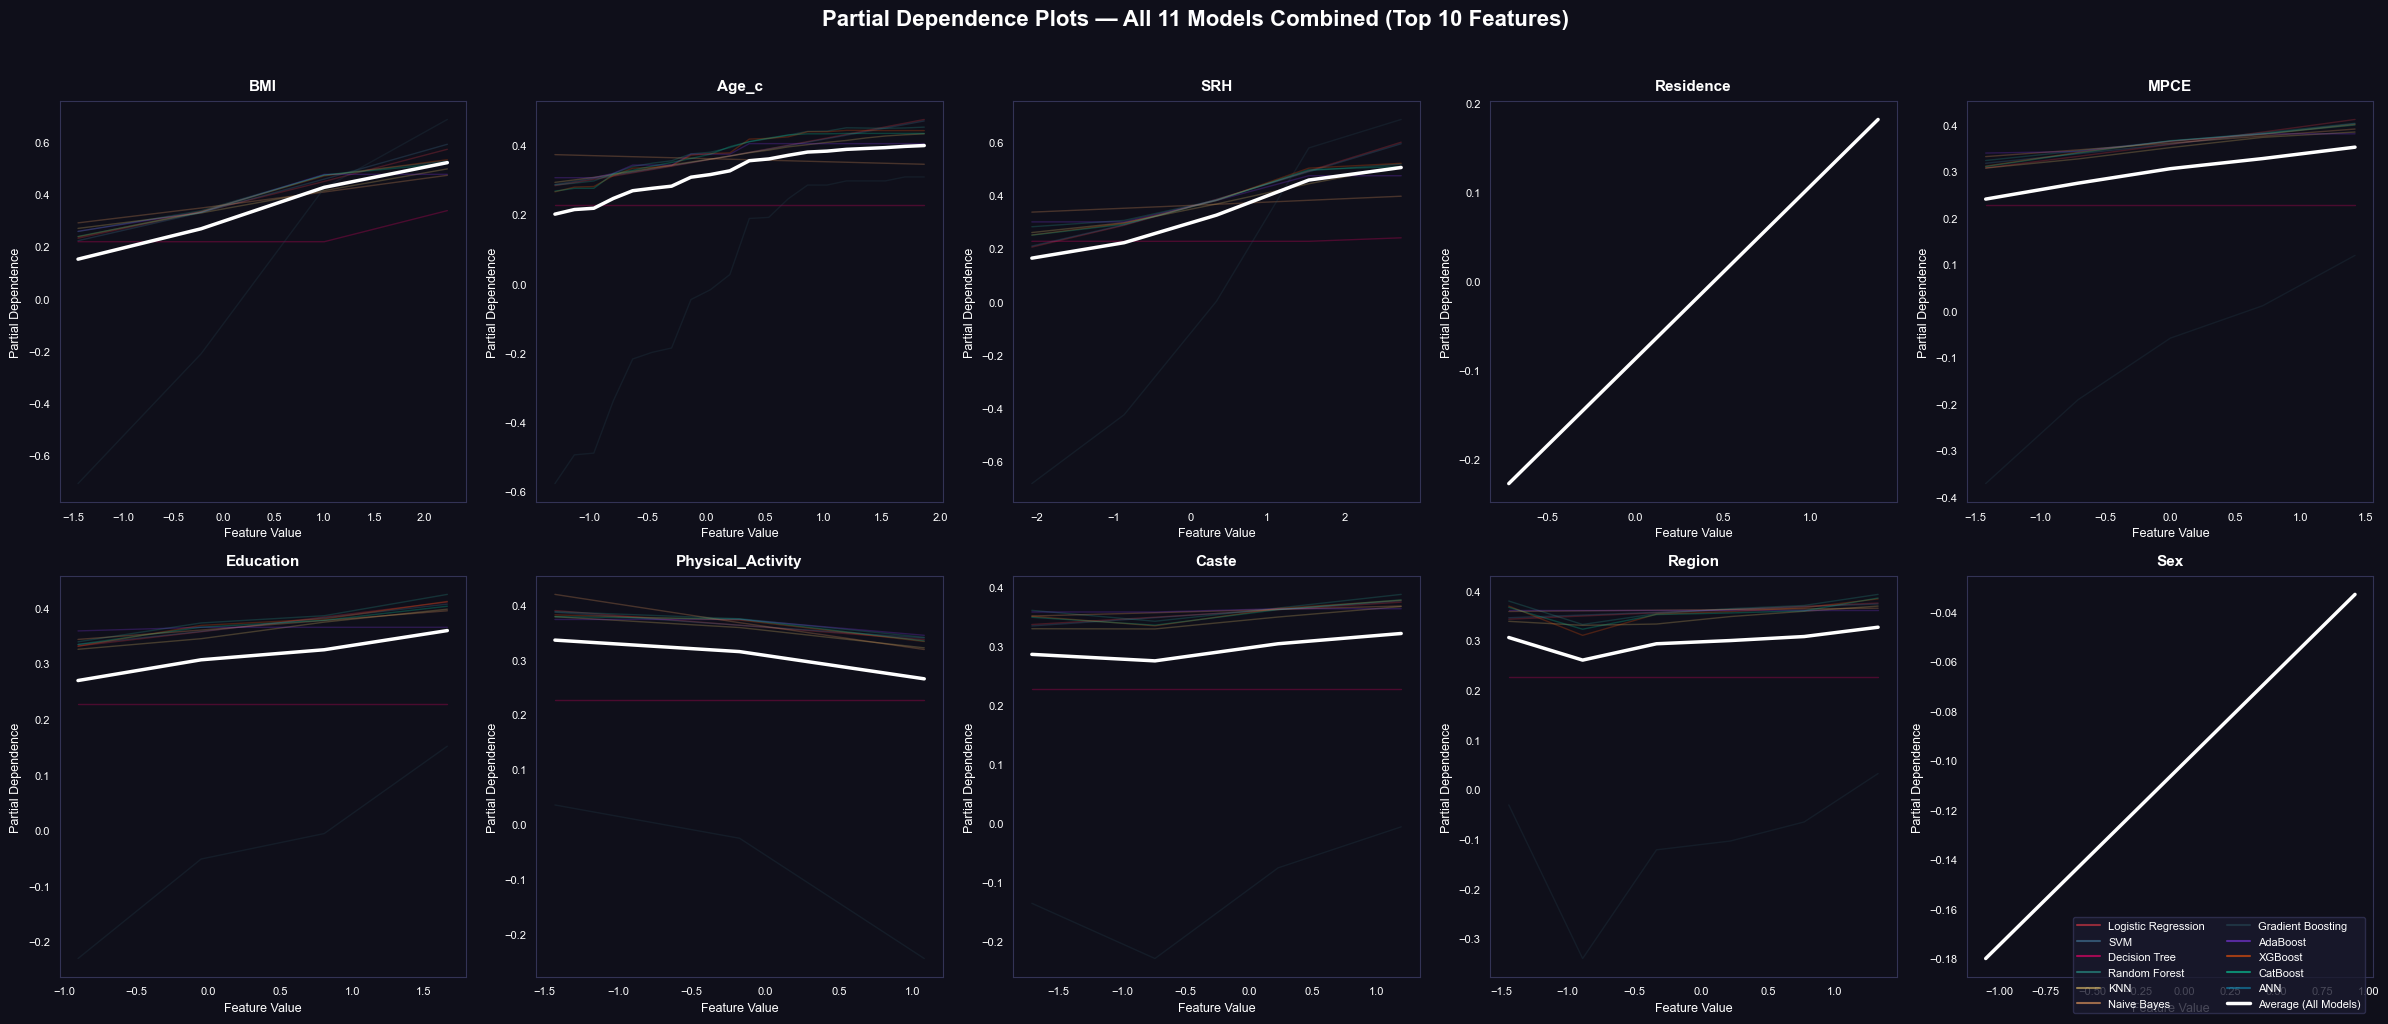

✅ Combined PDP saved!


In [35]:
from sklearn.inspection import partial_dependence
import matplotlib.pyplot as plt
import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin

feature_names = x_train.columns.tolist()

# ✅ Correct feature names from your dataset
top_features = ['BMI', 'Age_c', 'SRH', 'Residence',
                 'MPCE', 'Education', 'Physical_Activity',
                 'Caste', 'Region', 'Sex']

models_pdp = {
    'Logistic Regression': (model_lr,  x_test_scaled),
    'SVM':                 (model_svm, x_test_scaled),
    'Decision Tree':       (model_dt,  x_test_scaled),
    'Random Forest':       (rf_model,  x_test),
    'KNN':                 (model_knn, x_test_scaled),
    'Naive Bayes':         (model_nb,  x_test),
    'Gradient Boosting':   (model_gb,  x_test_scaled),
    'AdaBoost':            (model_ada, x_test_scaled),
    'XGBoost':             (model_xgb, x_test_scaled),
    'CatBoost':            (model_cat, x_test_scaled),
}

# ANN Wrapper
class ANNWrapper(BaseEstimator, ClassifierMixin):
    def predict_proba(self, X):
        prob = model_ann.predict(X).flatten()
        return np.column_stack([1 - prob, prob])
    def fit(self, X, y): return self

ann_wrapper = ANNWrapper()

# ── ONE figure with subplots for each feature ──
fig, axes = plt.subplots(2, 5, figsize=(24, 10))
fig.patch.set_facecolor('#0f0f1a')
axes = axes.flatten()

colors = ['#e63946','#457b9d','#ff006e','#2a9d8f','#e9c46a',
          '#f4a261','#264653','#8338ec','#fb5607','#06d6a0','#118ab2']

model_names = list(models_pdp.keys()) + ['ANN']

print("⏳ Computing combined PDP for all 11 models...")

for feat_idx, feat_name in enumerate(top_features):
    ax = axes[feat_idx]
    ax.set_facecolor('#0f0f1a')

    feat_col_idx = feature_names.index(feat_name)
    all_pdp_values = []
    grid_values = None

    # 10 sklearn models
    for i, (model_name, (model, x_data)) in enumerate(models_pdp.items()):
        try:
            pdp_result = partial_dependence(
                model, x_data,
                features=[feat_col_idx],
                grid_resolution=20,
                kind='average'
            )
            if grid_values is None:
                grid_values = pdp_result['grid_values'][0]
            all_pdp_values.append(pdp_result['average'][0])
            ax.plot(grid_values, pdp_result['average'][0],
                    color=colors[i], alpha=0.25, linewidth=1)
        except Exception as e:
            print(f"  ⚠️ {model_name} - {feat_name}: {e}")

    # ANN
    try:
        pdp_ann = partial_dependence(
            ann_wrapper, x_test_scaled,
            features=[feat_col_idx],
            grid_resolution=20,
            kind='average'
        )
        if grid_values is None:
            grid_values = pdp_ann['grid_values'][0]
        all_pdp_values.append(pdp_ann['average'][0])
        ax.plot(grid_values, pdp_ann['average'][0],
                color=colors[10], alpha=0.25, linewidth=1)
    except Exception as e:
        print(f"  ⚠️ ANN - {feat_name}: {e}")

    # ── Bold average line ──
    if len(all_pdp_values) > 0:
        avg_pdp = np.mean(all_pdp_values, axis=0)
        ax.plot(grid_values, avg_pdp,
                color='white', linewidth=2.5,
                label='Average', zorder=5)

    ax.set_title(feat_name, fontsize=11,
                 fontweight='bold', color='white', pad=8)
    ax.set_xlabel('Feature Value', fontsize=9, color='white')
    ax.set_ylabel('Partial Dependence', fontsize=9, color='white')
    ax.tick_params(colors='white', labelsize=8)
    ax.spines[:].set_color('#333355')

    print(f"  ✅ {feat_name} done")

# ── Single legend for all models ──
handles = [plt.Line2D([0], [0], color=colors[i],
           linewidth=1.5, alpha=0.6)
           for i in range(len(model_names))]
handles.append(plt.Line2D([0], [0], color='white', linewidth=2.5))
legend_labels = model_names + ['Average (All Models)']

fig.legend(handles, legend_labels,
           loc='lower right', fontsize=8,
           facecolor='#1a1a2e', edgecolor='#333355',
           labelcolor='white', ncol=2,
           bbox_to_anchor=(0.99, 0.01))

fig.suptitle('Partial Dependence Plots — All 11 Models Combined (Top 10 Features)',
             fontsize=16, fontweight='bold', color='white', y=1.02)

plt.tight_layout()
plt.savefig('pdp_all_models_combined.png', dpi=150,
            bbox_inches='tight', facecolor='#0f0f1a')
plt.show()
print("✅ Combined PDP saved!")

⏳ Computing combined PDP for all 11 models...


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


  ⚠️ ANN - BMI: This ANNWrapper instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.
  ✅ BMI done


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.w

  ⚠️ ANN - Age_c: This ANNWrapper instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.
  ✅ Age_c done


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.w

... (11 outputs left out)

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.w

  ⚠️ ANN - Region: This ANNWrapper instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.
  ✅ Region done
  ⚠️ Logistic Regression - Sex: cannot reshape array of size 1 into shape (2)
  ⚠️ SVM - Sex: cannot reshape array of size 1 into shape (2)
  ⚠️ Decision Tree - Sex: cannot reshape array of size 1 into shape (2)


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


  ⚠️ Random Forest - Sex: cannot reshape array of size 1 into shape (2)
  ⚠️ KNN - Sex: cannot reshape array of size 1 into shape (2)
  ⚠️ Naive Bayes - Sex: cannot reshape array of size 1 into shape (2)
  ⚠️ AdaBoost - Sex: cannot reshape array of size 1 into shape (2)
  ⚠️ XGBoost - Sex: cannot reshape array of size 1 into shape (2)
  ⚠️ CatBoost - Sex: cannot reshape array of size 1 into shape (2)
  ⚠️ ANN - Sex: This ANNWrapper instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.
  ✅ Sex done


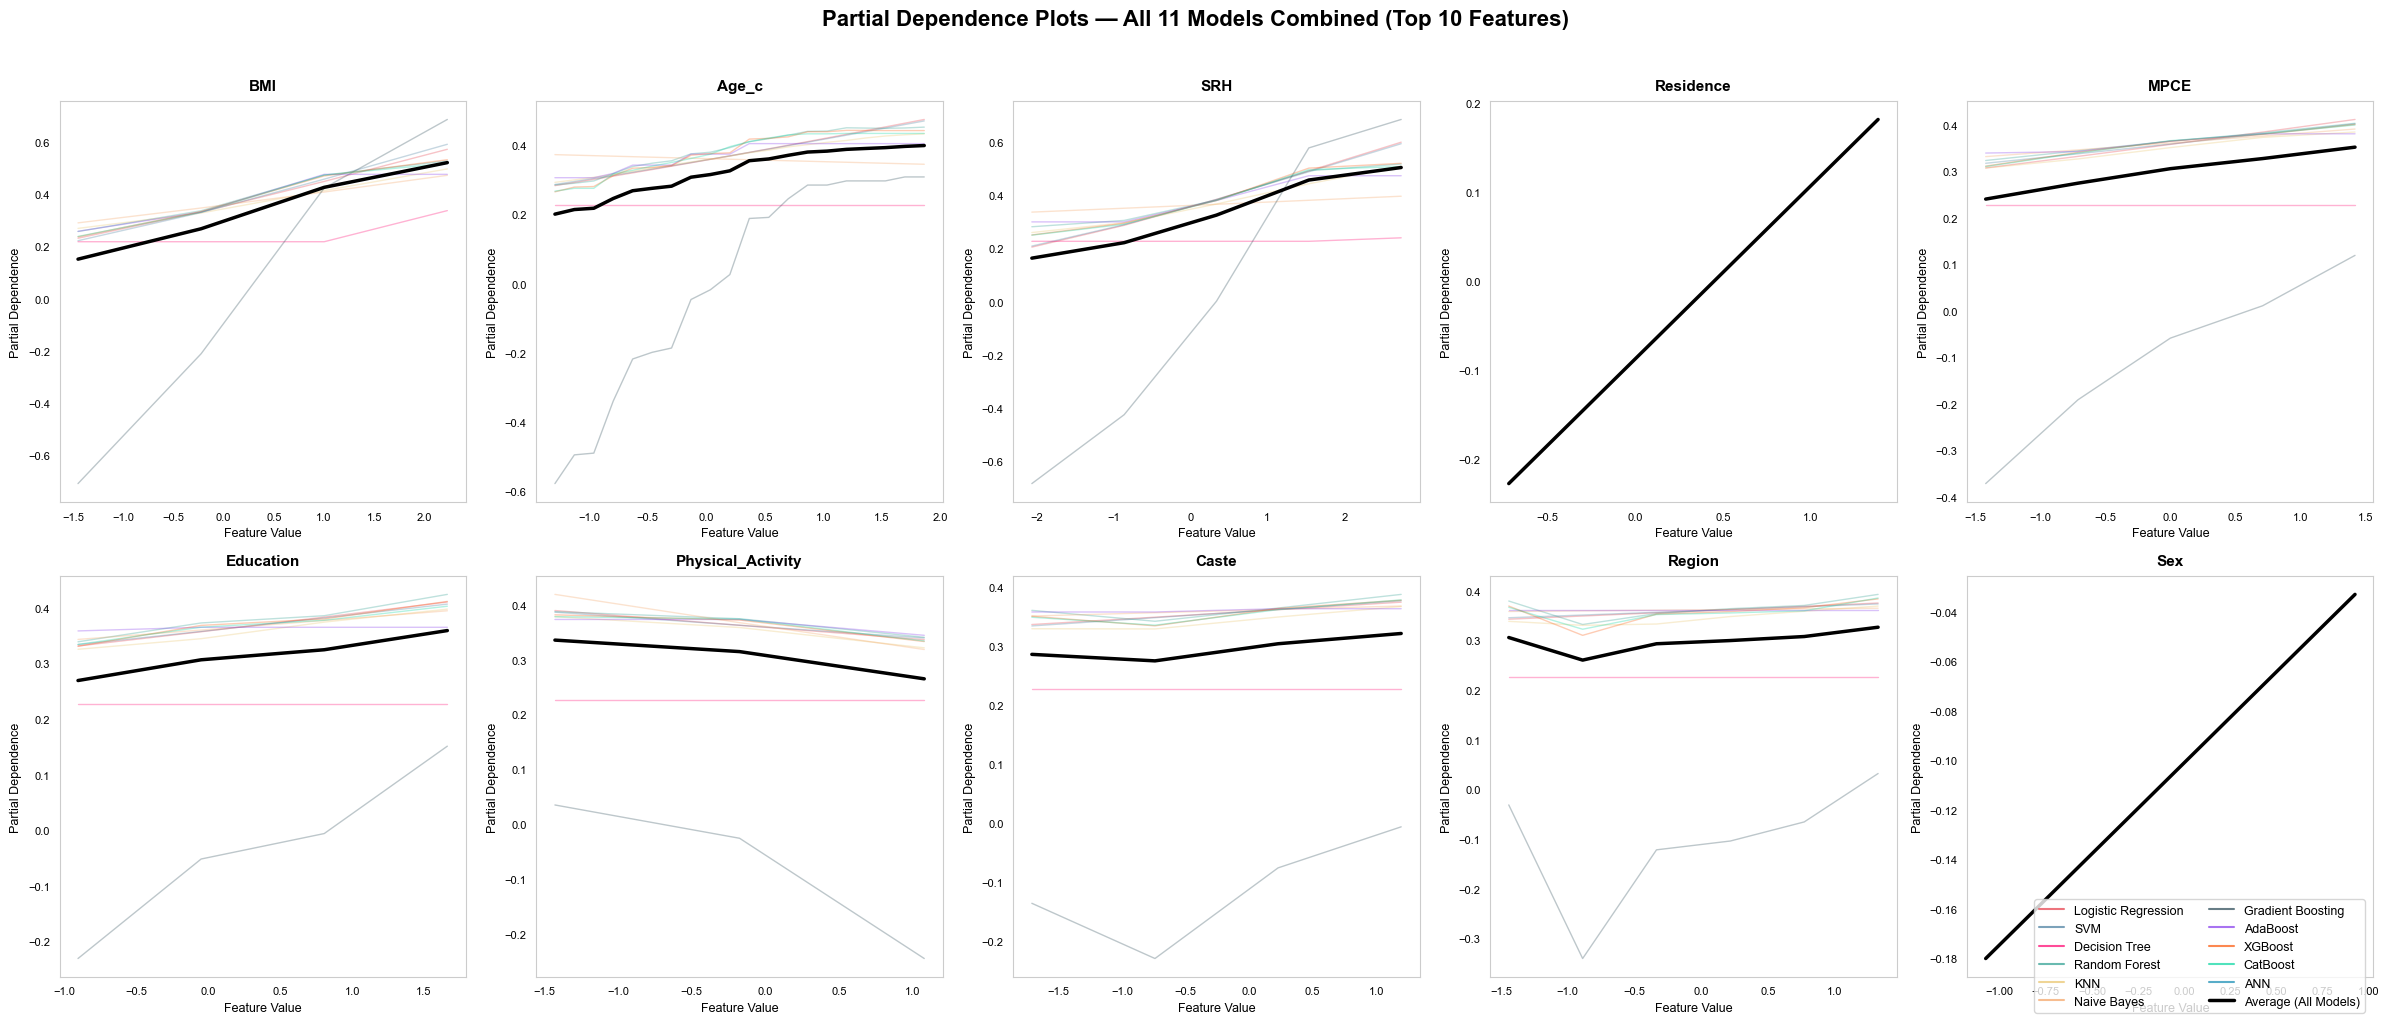

✅ Combined PDP with white background saved!


In [36]:
from sklearn.inspection import partial_dependence
import matplotlib.pyplot as plt
import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin

# 1. Force white style reset
plt.rcdefaults()
import seaborn as sns
sns.set_style("white")

# ... [Keep top_features and models_pdp definition same as your code] ...

# ── ONE figure with subplots for each feature ──
fig, axes = plt.subplots(2, 5, figsize=(24, 10), facecolor='white')
axes = axes.flatten()

# Standard professional colors for the lines
colors = ['#e63946','#457b9d','#ff006e','#2a9d8f','#e9c46a',
          '#f4a261','#264653','#8338ec','#fb5607','#06d6a0','#118ab2']

model_names = list(models_pdp.keys()) + ['ANN']

print("⏳ Computing combined PDP for all 11 models...")

for feat_idx, feat_name in enumerate(top_features):
    ax = axes[feat_idx]
    ax.set_facecolor('white') # Set subplot background to white

    feat_col_idx = feature_names.index(feat_name)
    all_pdp_values = []
    grid_values = None

    # 10 sklearn models
    for i, (model_name, (model, x_data)) in enumerate(models_pdp.items()):
        try:
            pdp_result = partial_dependence(
                model, x_data,
                features=[feat_col_idx],
                grid_resolution=20,
                kind='average'
            )
            if grid_values is None:
                grid_values = pdp_result['grid_values'][0]
            all_pdp_values.append(pdp_result['average'][0])
            ax.plot(grid_values, pdp_result['average'][0],
                    color=colors[i], alpha=0.3, linewidth=1) # Slightly higher alpha for white bg
        except Exception as e:
            print(f"  ⚠️ {model_name} - {feat_name}: {e}")

    # ANN
    try:
        pdp_ann = partial_dependence(
            ann_wrapper, x_test_scaled,
            features=[feat_col_idx],
            grid_resolution=20,
            kind='average'
        )
        if grid_values is None:
            grid_values = pdp_ann['grid_values'][0]
        all_pdp_values.append(pdp_ann['average'][0])
        ax.plot(grid_values, pdp_ann['average'][0],
                color=colors[10], alpha=0.3, linewidth=1)
    except Exception as e:
        print(f"  ⚠️ ANN - {feat_name}: {e}")

    # ── Bold average line (Changed to BLACK for white background) ──
    if len(all_pdp_values) > 0:
        avg_pdp = np.mean(all_pdp_values, axis=0)
        ax.plot(grid_values, avg_pdp,
                color='black', linewidth=2.5,
                label='Average', zorder=5)

    # 2. Update Text and Spines to Black
    ax.set_title(feat_name, fontsize=11, fontweight='bold', color='black', pad=8)
    ax.set_xlabel('Feature Value', fontsize=9, color='black')
    ax.set_ylabel('Partial Dependence', fontsize=9, color='black')
    ax.tick_params(colors='black', labelsize=8)
    for spine in ax.spines.values():
        spine.set_color('#cccccc') # Light gray border for subplots

    print(f"  ✅ {feat_name} done")

# ── Single legend for all models ──
handles = [plt.Line2D([0], [0], color=colors[i], linewidth=1.5, alpha=0.7)
           for i in range(len(model_names))]
handles.append(plt.Line2D([0], [0], color='black', linewidth=2.5)) # Black line for Average
legend_labels = model_names + ['Average (All Models)']

# 3. Update Legend for white background
fig.legend(handles, legend_labels,
           loc='lower right', fontsize=9,
           facecolor='white', edgecolor='#cccccc',
           labelcolor='black', ncol=2,
           bbox_to_anchor=(0.99, 0.01))

fig.suptitle('Partial Dependence Plots — All 11 Models Combined (Top 10 Features)',
             fontsize=16, fontweight='bold', color='black', y=1.02)

plt.tight_layout()

# 4. Save with white facecolor
plt.savefig('pdp_all_models_white.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

print("✅ Combined PDP with white background saved!")

In [60]:
# ============================================================
# Individual PDP Plots for Top Features (White Background)
# ============================================================
from sklearn.inspection import partial_dependence
import matplotlib.pyplot as plt
import numpy as np
import os
from sklearn.base import BaseEstimator, ClassifierMixin

# Create a folder for PDP plots
if not os.path.exists('pdp_plots'):
    os.makedirs('pdp_plots')

feature_names = x_train.columns.tolist()

# Features to plot
top_features = ['BMI', 'Age_c', 'SRH', 'Residence',
                'MPCE', 'Education', 'Physical_Activity',
                'Caste', 'Region', 'Sex']

models_pdp = {
    'Logistic Regression': (model_lr,  x_test_scaled),
    'SVM':                 (model_svm, x_test_scaled),
    'Decision Tree':       (model_dt,  x_test_scaled),
    'Random Forest':       (rf_model,  x_test),
    'KNN':                 (model_knn, x_test_scaled),
    'Naive Bayes':         (model_nb,  x_test),
    'Gradient Boosting':   (model_gb,  x_test_scaled),
    'AdaBoost':            (model_ada, x_test_scaled),
    'XGBoost':             (model_xgb, x_test_scaled),
    'CatBoost':            (model_cat, x_test_scaled),
}

# ANN Wrapper
class ANNWrapper(BaseEstimator, ClassifierMixin):
    def predict_proba(self, X):
        prob = model_ann.predict(X).flatten()
        return np.column_stack([1 - prob, prob])
    def fit(self, X, y): return self

ann_wrapper = ANNWrapper()

colors = ['#e63946','#457b9d','#ff006e','#2a9d8f','#e9c46a',
          '#f4a261','#264653','#8338ec','#fb5607','#06d6a0','#118ab2']

model_names = list(models_pdp.keys()) + ['ANN']

print("⏳ Computing individual PDPs for each feature...")

for feat_name in top_features:
    # Create a fresh figure for each feature
    fig, ax = plt.subplots(figsize=(10, 6))
    fig.patch.set_facecolor('white')
    ax.set_facecolor('white')

    feat_col_idx = feature_names.index(feat_name)
    all_pdp_values = []
    grid_values = None

    # Plot 10 sklearn models
    for i, (model_name, (model, x_data)) in enumerate(models_pdp.items()):
        try:
            pdp_result = partial_dependence(
                model, x_data,
                features=[feat_col_idx],
                grid_resolution=20,
                kind='average'
            )
            if grid_values is None:
                grid_values = pdp_result['grid_values'][0]
            
            all_pdp_values.append(pdp_result['average'][0])
            ax.plot(grid_values, pdp_result['average'][0],
                    color=colors[i], alpha=0.3, linewidth=1.5, label=model_name)
        except Exception as e:
            print(f"  ⚠️ {model_name} - {feat_name}: {e}")

    # Plot ANN
    try:
        pdp_ann = partial_dependence(
            ann_wrapper, x_test_scaled,
            features=[feat_col_idx],
            grid_resolution=20,
            kind='average'
        )
        all_pdp_values.append(pdp_ann['average'][0])
        ax.plot(grid_values, pdp_ann['average'][0],
                color=colors[10], alpha=0.3, linewidth=1.5, label='ANN')
    except Exception as e:
        print(f"  ⚠️ ANN - {feat_name}: {e}")

    # Bold average line (Changed from white to black/navy for visibility)
    if len(all_pdp_values) > 0:
        avg_pdp = np.mean(all_pdp_values, axis=0)
        ax.plot(grid_values, avg_pdp,
                color='black', linewidth=3,
                label='AVERAGE (ALL MODELS)', zorder=10)

    # Styling for white background
    ax.set_title(f'Partial Dependence: {feat_name}', fontsize=14, fontweight='bold', color='black', pad=15)
    ax.set_xlabel(f'{feat_name} Value', fontsize=11, color='black')
    ax.set_ylabel('Partial Dependence (Probability)', fontsize=11, color='black')
    ax.tick_params(colors='black', labelsize=10)
    
    for spine in ax.spines.values():
        spine.set_color('#cccccc')

    # Legend for each plot
    ax.legend(loc='best', fontsize=8, facecolor='white', edgecolor='#cccccc', labelcolor='black', ncol=2)

    plt.tight_layout()
    clean_name = feat_name.lower().replace(" ", "_")
    plt.savefig(f'pdp_plots/pdp_{clean_name}.png', dpi=150, bbox_inches='tight', facecolor='white')
    plt.close()
    
    print(f"  ✅ Saved: pdp_plots/pdp_{clean_name}.png")

print("\nDone! All individual PDP plots are in the 'pdp_plots' folder.")

⏳ Computing individual PDPs for each feature...


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


  ⚠️ ANN - BMI: This ANNWrapper instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.
  ✅ Saved: pdp_plots/pdp_bmi.png


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.w

  ⚠️ ANN - Age_c: This ANNWrapper instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.
  ✅ Saved: pdp_plots/pdp_age_c.png


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.w

... (11 outputs left out)

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.w

  ⚠️ ANN - Region: This ANNWrapper instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.
  ✅ Saved: pdp_plots/pdp_region.png
  ⚠️ Logistic Regression - Sex: cannot reshape array of size 1 into shape (2)
  ⚠️ SVM - Sex: cannot reshape array of size 1 into shape (2)
  ⚠️ Decision Tree - Sex: cannot reshape array of size 1 into shape (2)


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


  ⚠️ Random Forest - Sex: cannot reshape array of size 1 into shape (2)
  ⚠️ KNN - Sex: cannot reshape array of size 1 into shape (2)
  ⚠️ Naive Bayes - Sex: cannot reshape array of size 1 into shape (2)
  ⚠️ AdaBoost - Sex: cannot reshape array of size 1 into shape (2)
  ⚠️ XGBoost - Sex: cannot reshape array of size 1 into shape (2)
  ⚠️ CatBoost - Sex: cannot reshape array of size 1 into shape (2)
  ⚠️ ANN - Sex: This ANNWrapper instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.
  ✅ Saved: pdp_plots/pdp_sex.png

Done! All individual PDP plots are in the 'pdp_plots' folder.


374/374 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


P-value Matrix:
         LR     SVM     ANN   DT      RF     KNN      NB      GB     Ada     XGB     Cat
LR   1.0000  0.9111  0.0201  0.0  0.0033  0.0000  0.0000  0.0020  0.0003  0.0001  0.0018
SVM  0.9111  1.0000  0.0293  0.0  0.0027  0.0000  0.0000  0.0040  0.0001  0.0003  0.0037
ANN  0.0201  0.0293  1.0000  0.0  0.0000  0.0000  0.0000  0.4313  0.0000  0.0903  0.6276
DT   0.0000  0.0000  0.0000  1.0  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000
RF   0.0033  0.0027  0.0000  0.0  1.0000  0.0000  0.0000  0.0000  0.9093  0.0000  0.0000
KNN  0.0000  0.0000  0.0000  0.0  0.0000  1.0000  0.1135  0.0000  0.0000  0.0000  0.0000
NB   0.0000  0.0000  0.0000  0.0  0.0000  0.1135  1.0000  0.0000  0.0000  0.0000  0.0000
GB   0.0020  0.0040  0.4313  0.0  0.0000  0.0000  0.0000  1.0000  0.0000  0.0944  0.7296
Ada  0.0003  0.0001  0.0000  0.0  0.9093  0.0000  0.0000  0.0000  1.0000  0.0000  0.0000
XGB  0.0001  0.0003  0.0903  0.0  0.0000  0.0000  0.0000  0.0944  0.0000  1.0000  0.1380
Cat  

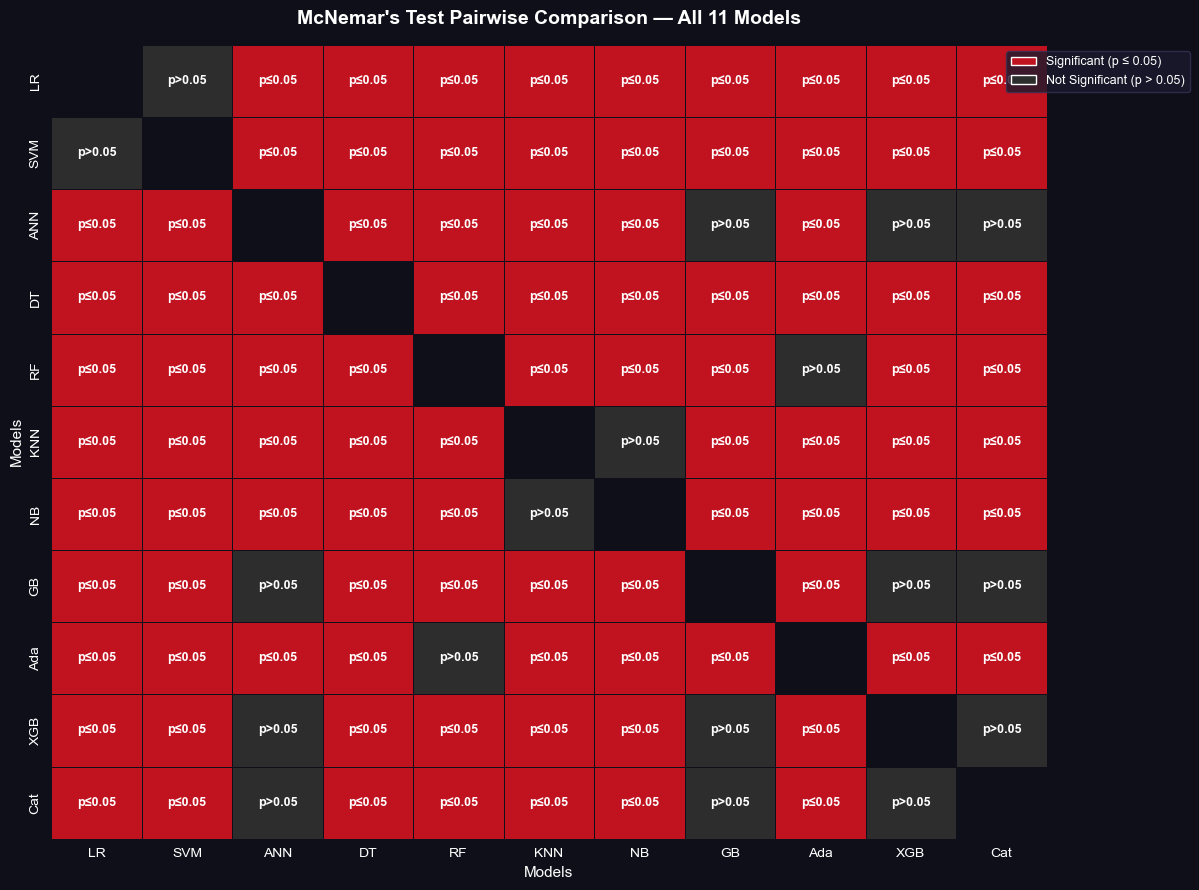

✅ McNemar's Test saved!


In [31]:
#McNemar's test 

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.contingency_tables import mcnemar

# Get predictions for all 11 models
predictions = {
    'LR':  model_lr.predict(x_test_scaled),
    'SVM': model_svm.predict(x_test_scaled),
    'ANN': (model_ann.predict(x_test_scaled).flatten() >= 0.5).astype(int),
    'DT':  model_dt.predict(x_test_scaled),
    'RF':  rf_model.predict(x_test),
    'KNN': model_knn.predict(x_test_scaled),
    'NB':  model_nb.predict(x_test),
    'GB':  model_gb.predict(x_test_scaled),
    'Ada': model_ada.predict(x_test_scaled),
    'XGB': model_xgb.predict(x_test_scaled),
    'Cat': model_cat.predict(x_test_scaled),
}

model_names = list(predictions.keys())
n = len(model_names)

# ── Compute p-values matrix ──
pvalue_matrix = np.ones((n, n))

for i in range(n):
    for j in range(n):
        if i != j:
            pred_i = predictions[model_names[i]]
            pred_j = predictions[model_names[j]]

            # Build contingency table
            # [both correct, i correct j wrong]
            # [i wrong j correct, both wrong]
            both_correct    = np.sum((pred_i == y_test) & (pred_j == y_test))
            i_right_j_wrong = np.sum((pred_i == y_test) & (pred_j != y_test))
            i_wrong_j_right = np.sum((pred_i != y_test) & (pred_j == y_test))
            both_wrong      = np.sum((pred_i != y_test) & (pred_j != y_test))

            table = [[both_correct, i_right_j_wrong],
                     [i_wrong_j_right, both_wrong]]

            try:
                result = mcnemar(table, exact=False, correction=True)
                pvalue_matrix[i, j] = result.pvalue
            except:
                pvalue_matrix[i, j] = 1.0

# ── Binary significance matrix ──
significance_matrix = (pvalue_matrix <= 0.05).astype(int)

# ── Print p-values ──
pvalue_df = pd.DataFrame(pvalue_matrix,
                          index=model_names,
                          columns=model_names)
print("P-value Matrix:")
print(pvalue_df.round(4).to_string())

# ── Plot ──
fig, ax = plt.subplots(figsize=(12, 9))
fig.patch.set_facecolor('#0f0f1a')
ax.set_facecolor('#0f0f1a')

# Create color matrix
# Dark red = significant, light grey = not significant
color_matrix = np.where(significance_matrix == 1, 1.0, 0.0)

# Mask diagonal
mask = np.eye(n, dtype=bool)

sns.heatmap(
    pd.DataFrame(color_matrix,
                 index=model_names,
                 columns=model_names),
    ax=ax,
    cmap=['#2d2d2d', '#c1121f'],
    mask=mask,
    linewidths=0.5,
    linecolor='#0f0f1a',
    cbar=False,
    annot=pd.DataFrame(
        np.where(mask, 'X',
        np.where(significance_matrix == 1, 'p≤0.05', 'p>0.05')),
        index=model_names,
        columns=model_names
    ),
    fmt='',
    annot_kws={'size': 9, 'color': 'white', 'fontweight': 'bold'}
)

ax.set_title("McNemar's Test Pairwise Comparison — All 11 Models",
             fontsize=14, fontweight='bold', color='white', pad=15)
ax.tick_params(colors='white', labelsize=10)
ax.set_xlabel('Models', fontsize=11, color='white')
ax.set_ylabel('Models', fontsize=11, color='white')

# Legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#c1121f', label='Significant (p ≤ 0.05)'),
    Patch(facecolor='#2d2d2d', label='Not Significant (p > 0.05)')
]
ax.legend(handles=legend_elements,
          loc='upper right',
          facecolor='#1a1a2e',
          edgecolor='#333355',
          labelcolor='white',
          fontsize=9,
          bbox_to_anchor=(1.15, 1))

plt.tight_layout()
plt.savefig('mcnemar_test_all_models.png', dpi=150,
            bbox_inches='tight', facecolor='#0f0f1a')
plt.show()
print("✅ McNemar's Test saved!")

C:\Users\kiran\AppData\Local\Temp\ipykernel_7276\1128713285.py:22: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot_matrix = pvalue_df.applymap(format_significance).values


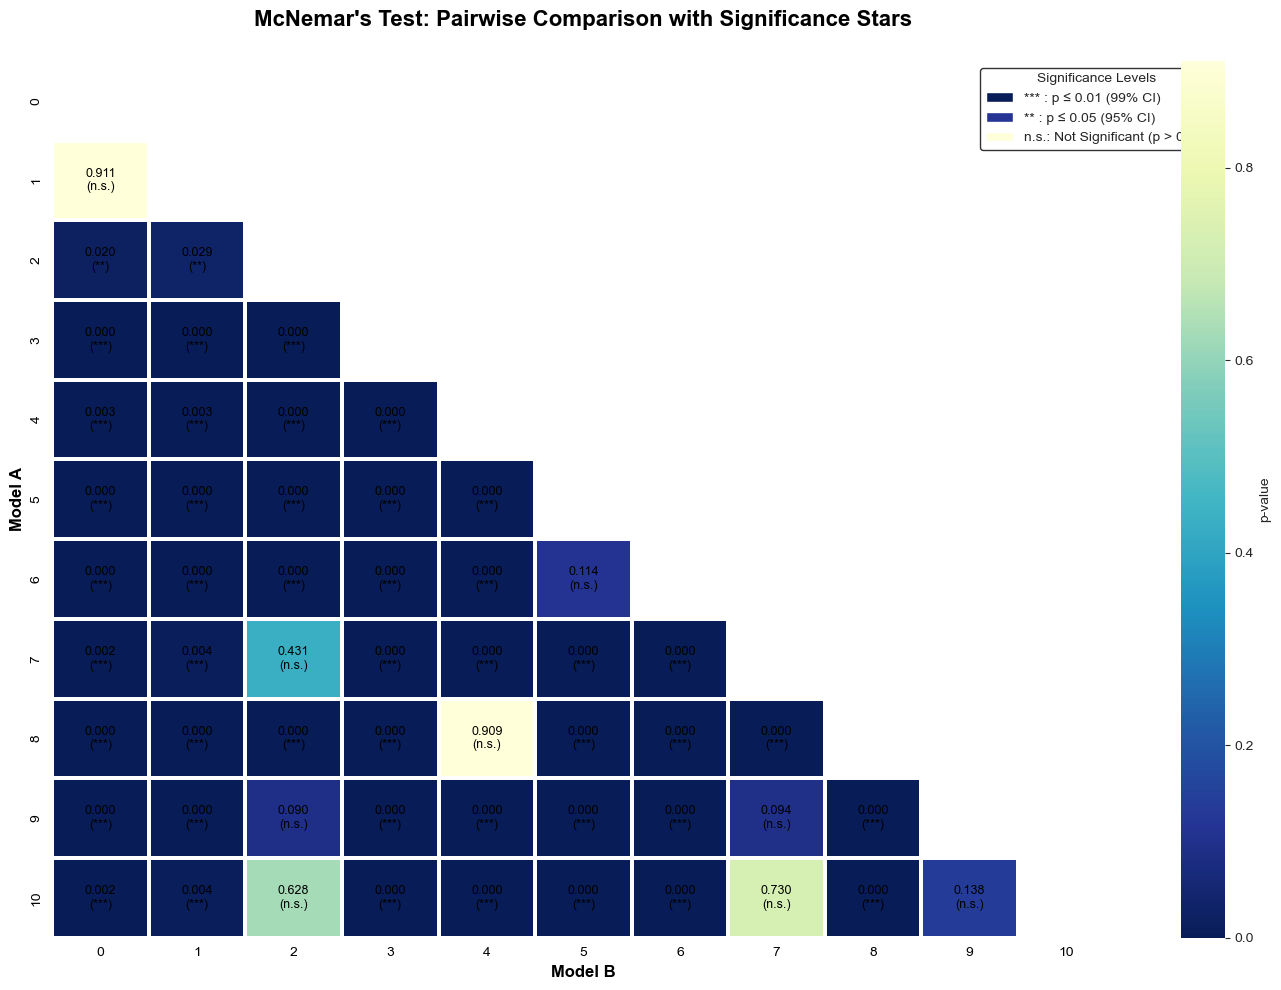

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

# 1. Reset to clean white style
plt.rcdefaults()
sns.set_style("white")

# 2. Define Significance Labeling Function
def format_significance(p):
    if p <= 0.01:
        return f"{p:.3f}\n(***)" # 99% CI
    elif p <= 0.05:
        return f"{p:.3f}\n(**)"  # 95% CI
    else:
        return f"{p:.3f}\n(n.s.)"

# 3. Prepare the Annotation Matrix (Values + Stars)
# Assuming pvalue_df is your DataFrame from the McNemar calculation
annot_matrix = pvalue_df.applymap(format_significance).values

# 4. Create Mask for the Upper Triangle (to show only half)
mask = np.triu(np.ones_like(pvalue_matrix, dtype=bool))

# 5. Plotting
fig, ax = plt.subplots(figsize=(14, 10), facecolor='white')
ax.set_facecolor('white')

# We use a sequential colormap where lower p-values (significant) are darker
sns.heatmap(
    pvalue_matrix, 
    mask=mask,
    ax=ax,
    cmap='YlGnBu_r', # Darker colors = more significant (lower p-value)
    annot=annot_matrix,
    fmt='',
    linewidths=1.5,
    linecolor='white',
    cbar_kws={'label': 'p-value'},
    annot_kws={'size': 9, 'color': 'black', 'fontweight': 'normal'}
)

# 6. Formatting Titles and Labels
ax.set_title("McNemar's Test: Pairwise Comparison with Significance Stars", 
             fontsize=16, fontweight='bold', color='black', pad=25)
ax.set_xlabel('Model B', fontsize=12, fontweight='bold', color='black')
ax.set_ylabel('Model A', fontsize=12, fontweight='bold', color='black')
ax.tick_params(colors='black', labelsize=10)

# 7. Add Legend for Confidence Intervals
legend_elements = [
    Patch(facecolor='#081d58', label='*** : p ≤ 0.01 (99% CI)'),
    Patch(facecolor='#253494', label='** : p ≤ 0.05 (95% CI)'),
    Patch(facecolor='#ffffd9', label='n.s.: Not Significant (p > 0.05)')
]
ax.legend(handles=legend_elements, loc='upper right', 
          bbox_to_anchor=(1.1, 1), frameon=True, 
          facecolor='white', edgecolor='black', title="Significance Levels")

plt.tight_layout()
plt.savefig('mcnemar_final_white.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

In [57]:
print(x_train.columns.tolist())

['Residence', 'Age_c', 'Sex', 'Marital_Status', 'Education', 'Living', 'SRH', 'ADL', 'IADL', 'BMI', 'Tobacco', 'Drinker', 'Yoga', 'Physical_Activity', 'MPCE', 'Caste', 'Religion', 'Region']
